# Pathway enrichment by DC - Ascites v Metastatic tumour
* Using NR code from 2024-11-26_Pathway-Enrichment.ipynb
* using pathway gene sets downloaded in the local R Studio (I:\Group_Data\MR_Groups\RG05. Cancer Immunotherapies\01 Team Research Data\Luzia\R\NR_AtlasAnalysis, Pathway Enrichment.rmd)

* Using clustered all DC cancer data and will isolate the ovarian cancer and the metastatic and ascites conditions from this data

Set up workspace

In [5]:
#load packages 
import os
import tools

In [1]:
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns

In [2]:
import scanpy as sc
import pandas as pd

In [3]:
import dandelion as ddl

/home/uqlbukat/.local/lib/python3.11/site-packages/nxviz/__init__.py:33: UserWarning: 
nxviz has a new API! Version 0.7.4 onwards, the old class-based API is being
deprecated in favour of a new API focused on advancing a grammar of network
graphics. If your plotting code depends on the old API, please consider
pinning nxviz at version 0.7.4, as the new API will break your old code.

To check out the new API, please head over to the docs at
https://ericmjl.github.io/nxviz/ to learn more. We hope you enjoy using it!

(This deprecation message will go away in version 1.0.)



In [6]:
#show current directory 
os.getcwd()
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment'

Print software versions

In [ ]:
sc.logging.print_header()

/scratch/temp/25199326/ipykernel_1153681/1023403583.py:1: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')


Package,Version
tools,1.0.30
tqdm,4.67.3
matplotlib,3.10.8
scanpy,1.11.5
seaborn,0.13.2
pandas,2.3.3
sc-dandelion,0.5.7
Component,Info
Python,"3.11.15 | packaged by conda-forge | (main, Mar 5 2026, 16:45:40) [GCC 14.3.0]"
OS,Linux-5.14.0-611.54.1.el9_7.x86_64-x86_64-with-glibc2.34


In [ ]:
ddl.logging.print_header()

dandelion==0.5.7 pandas==2.3.3 numpy==2.3.5 matplotlib==3.10.8 networkx==3.6.1 scipy==1.17.0


### Read in The full DC Cancer dataset
20250617_AllDC_bbknn.h5ad which is the DC only version of atlas

In [7]:
data_all = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad')

In [ ]:
data_all

AnnData object with n_obs × n_vars = 29887 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions'

In [8]:
data_all.obs["cancer_with_H"].value_counts()

cancer_with_H
HGSOC             9188
HNSCC             6640
NSCLC             5668
Breast Cancer     2727
Melanoma          1504
GBM                949
HCC                853
PDAC               757
NPC                460
GAC                404
CRC                305
iCCA               237
Acral Melanoma     195
Name: count, dtype: int64

In [9]:
#isolate ovarian cancer data
data_oc = data_all[data_all.obs["cancer_with_H"] == "HGSOC"]
data_oc

View of AnnData object with n_obs × n_vars = 9188 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispe

In [16]:
#Check the sample type information recorded in the dataset, sample_type_major2 defines metastatic vs mets vs ascites vs ascites
data_oc.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              3513
metastatic tumour    3005
primary tumour       2541
healthy               129
Name: count, dtype: int64

In [48]:
data_oc = data_oc[data_oc.obs["sample_type_major2"].isin(["ascites", "metastatic tumour"])].copy()

In [49]:
data_oc.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              3513
metastatic tumour    3005
Name: count, dtype: int64

In [50]:
data_DC1 = data_oc[data_oc.obs["NR_annotations_simple"] == "cDC1"]
data_DC2 = data_oc[data_oc.obs["NR_annotations_simple"] == "cDC2"]
data_mregDC = data_oc[data_oc.obs["NR_annotations_simple"] == "mregDC"]

In [51]:
data_DC1.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              1025
metastatic tumour     667
Name: count, dtype: int64

In [52]:
data_DC2.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              2242
metastatic tumour    1796
Name: count, dtype: int64

In [53]:
data_mregDC.obs["sample_type_major2"].value_counts()

sample_type_major2
metastatic tumour    542
ascites              246
Name: count, dtype: int64

## Hallmark pathways:

### Import Hallmark gene sets
* will be imported as a dictionary where each key is a sheet name, each value is a dataframe (gene set)

In [54]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
H_sets = pd.read_excel("hallmark_sets.xlsx", sheet_name=None)

In [55]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment')

In [56]:
#Print the sheet names
print(H_sets.keys())

dict_keys(['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5', 'Sheet6', 'Sheet7', 'Sheet8', 'Sheet9', 'Sheet10', 'Sheet11', 'Sheet12', 'Sheet13', 'Sheet14', 'Sheet15', 'Sheet16', 'Sheet17', 'Sheet18', 'Sheet19', 'Sheet20', 'Sheet21', 'Sheet22', 'Sheet23', 'Sheet24', 'Sheet25', 'Sheet26', 'Sheet27', 'Sheet28', 'Sheet29', 'Sheet30', 'Sheet31', 'Sheet32', 'Sheet33', 'Sheet34', 'Sheet35', 'Sheet36', 'Sheet37', 'Sheet38', 'Sheet39', 'Sheet40', 'Sheet41', 'Sheet42', 'Sheet43', 'Sheet44', 'Sheet45', 'Sheet46', 'Sheet47', 'Sheet48', 'Sheet49', 'Sheet50'])


In [57]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
H_sets2 = {df["gs_name"].iloc[0]: df for _, df in H_sets.items()}
H_sets = H_sets2

# Result
print(H_sets.keys())

dict_keys(['HALLMARK_ADIPOGENESIS', 'HALLMARK_ALLOGRAFT_REJECTION', 'HALLMARK_ANDROGEN_RESPONSE', 'HALLMARK_ANGIOGENESIS', 'HALLMARK_APICAL_JUNCTION', 'HALLMARK_APICAL_SURFACE', 'HALLMARK_APOPTOSIS', 'HALLMARK_BILE_ACID_METABOLISM', 'HALLMARK_CHOLESTEROL_HOMEOSTASIS', 'HALLMARK_COAGULATION', 'HALLMARK_COMPLEMENT', 'HALLMARK_DNA_REPAIR', 'HALLMARK_E2F_TARGETS', 'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION', 'HALLMARK_ESTROGEN_RESPONSE_EARLY', 'HALLMARK_ESTROGEN_RESPONSE_LATE', 'HALLMARK_FATTY_ACID_METABOLISM', 'HALLMARK_G2M_CHECKPOINT', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_HEDGEHOG_SIGNALING', 'HALLMARK_HEME_METABOLISM', 'HALLMARK_HYPOXIA', 'HALLMARK_IL2_STAT5_SIGNALING', 'HALLMARK_IL6_JAK_STAT3_SIGNALING', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_INTERFERON_ALPHA_RESPONSE', 'HALLMARK_INTERFERON_GAMMA_RESPONSE', 'HALLMARK_KRAS_SIGNALING_DN', 'HALLMARK_KRAS_SIGNALING_UP', 'HALLMARK_MITOTIC_SPINDLE', 'HALLMARK_MTORC1_SIGNALING', 'HALLMARK_MYC_TARGETS_V1', 'HALLMARK_MYC_TARGETS_V2', 'HALLMAR

In [58]:
H_sets

{'HALLMARK_ADIPOGENESIS':     gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0         ABCA1         19  ENSG00000165029          ABCA1            19   
 1         ABCB8      11194  ENSG00000197150          ABCB8         11194   
 2         ACAA2      10449  ENSG00000167315          ACAA2         10449   
 3         ACADL         33  ENSG00000115361          ACADL            33   
 4         ACADM         34  ENSG00000117054          ACADM            34   
 ..          ...        ...              ...            ...           ...   
 195      UQCR11      10975  ENSG00000127540         UQCR11         10975   
 196      UQCRC1       7384  ENSG00000010256         UQCRC1          7384   
 197       UQCRQ      27089  ENSG00000164405          UQCRQ         27089   
 198       VEGFB       7423  ENSG00000173511          VEGFB          7423   
 199       YWHAG       7532  ENSG00000170027          YWHAG          7532   
 
      db_ensembl_gene source_gene  gs_id         

### Score DC subsets by enrichment for each gene set (each dataframe in dictionary)

In [59]:
# Iterate through each gene set in H_sets - DC1
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_DC1, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets - DC2
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_DC2, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets - mregDC
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_mregDC, gene_list=gene_set, score_name=f"{set_name}_score")

       'FABP4', 'GPAT4', 'LEP', 'MIGA2', 'MRAP', 'MTARC2', 'ORM1', 'SLC66A3',
       'SQOR'],
      dtype='object')
       'IL4', 'IL9', 'MBL2', 'NOS2', 'RARS1', 'TGFB1', 'WARS1'],
      dtype='object')


/home/uqlbukat/.local/lib/python3.11/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.


       'COL9A1', 'DMP1', 'DSC1', 'FLNC', 'FYB1', 'KRT31', 'MAP3K20', 'NECTIN1',
       'NECTIN2', 'NECTIN3', 'NECTIN4', 'NHERF4', 'NRAP', 'PALS1', 'PECAM1',
       'WNK4'],
      dtype='object')
       'CYP8B1', 'DIO1', 'GC', 'HAO1', 'HSD3B1', 'NR0B2', 'NR1H4', 'SERPINA6',
       'SLC67A1', 'SOAT2', 'TTR'],
      dtype='object')
       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PLG',
       'PROZ', 'RGN'],
      dtype='object')
       'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'P3H1', 'POSTN', 'PRSS2', 'SCG2', 'SGCG', 'TGFB1'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SOX3'],
      dtype='object')
       'HMGCS2', 'LARGE1', 'NHERF1', 'NPY1R', 'PCP4', 'PLAAT3', 'SEMA3B',
       'SERPINA5', 'SOX3', 'TH'],
      dtype='object')
       'FABP1', 'FABP2', 'GAD2', 'GAPDHS', 'H2AZ1', 'HAO2', 'HMGCS2', 'KMT5A',
       'MIX23', 'XIST'],
  

/home/uqlbukat/.local/lib/python3.11/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.


       'IL4', 'IL9', 'MBL2', 'NOS2', 'RARS1', 'TGFB1', 'WARS1'],
      dtype='object')
       'COL9A1', 'DMP1', 'DSC1', 'FLNC', 'FYB1', 'KRT31', 'MAP3K20', 'NECTIN1',
       'NECTIN2', 'NECTIN3', 'NECTIN4', 'NHERF4', 'NRAP', 'PALS1', 'PECAM1',
       'WNK4'],
      dtype='object')
       'CYP8B1', 'DIO1', 'GC', 'HAO1', 'HSD3B1', 'NR0B2', 'NR1H4', 'SERPINA6',
       'SLC67A1', 'SOAT2', 'TTR'],
      dtype='object')
       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PLG',
       'PROZ', 'RGN'],
      dtype='object')
       'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'P3H1', 'POSTN', 'PRSS2', 'SCG2', 'SGCG', 'TGFB1'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SOX3'],
      dtype='object')
       'HMGCS2', 'LARGE1', 'NHERF1', 'NPY1R', 'PCP4', 'PLAAT3', 'SEMA3B',
       'SERPINA5', 'SOX3', 'TH'],
      dtype='object')
       'FABP1', 'FA

/home/uqlbukat/.local/lib/python3.11/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.


       'CYP8B1', 'DIO1', 'GC', 'HAO1', 'HSD3B1', 'NR0B2', 'NR1H4', 'SERPINA6',
       'SLC67A1', 'SOAT2', 'TTR'],
      dtype='object')
       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PLG',
       'PROZ', 'RGN'],
      dtype='object')
       'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'P3H1', 'POSTN', 'PRSS2', 'SCG2', 'SGCG', 'TGFB1'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SOX3'],
      dtype='object')
       'HMGCS2', 'LARGE1', 'NHERF1', 'NPY1R', 'PCP4', 'PLAAT3', 'SEMA3B',
       'SERPINA5', 'SOX3', 'TH'],
      dtype='object')
       'FABP1', 'FABP2', 'GAD2', 'GAPDHS', 'H2AZ1', 'HAO2', 'HMGCS2', 'KMT5A',
       'MIX23', 'XIST'],
      dtype='object')
       'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A', 'TGFB1'],
      dtype='object')
       'NOL3', 'PFKFB1', 'PGLS', 'RARS1'],
      dtype='object')
       'GYPE', 'H1-0', 

### Perform ANOVA on results:

In [60]:
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [61]:
# Initialize a results dictionary to store p-values
stats_results = {}

#set cancer types to be sample_type_major2 - ascites and metastatic

# Iterate through each gene set
for set_name in H_sets.keys():
    # Extract the scores and corresponding cancer types
    scores = data_DC1.obs[f"{set_name}_score"]
    cancer_types = data_DC1.obs["sample_type_major2"]

    # Perform ANOVA
    groups = [scores[cancer_types == ct] for ct in cancer_types.unique()]
    f_stat, p_value = stats.f_oneway(*groups)

    # Save the results
    stats_results[set_name] = {
        "p_value": p_value,
        "f_stat": f_stat
    }

    # Perform post-hoc test if p_value is significant
    if p_value < 0.05:
        posthoc = pairwise_tukeyhsd(endog=scores, groups=cancer_types, alpha=0.05)
        print(f"Post-hoc results for {set_name}:")
        print(posthoc)

# Convert the results to a dataframe for easier viewing
results_df = pd.DataFrame(stats_results).T
print(results_df)

Post-hoc results for HALLMARK_ALLOGRAFT_REJECTION:
     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
 group1       group2      meandiff p-adj  lower  upper  reject
--------------------------------------------------------------
ascites metastatic tumour   0.0063 0.0005 0.0028 0.0099   True
--------------------------------------------------------------
Post-hoc results for HALLMARK_ANDROGEN_RESPONSE:
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
 group1       group2      meandiff p-adj lower  upper reject
------------------------------------------------------------
ascites metastatic tumour   0.0409   0.0 0.0369 0.045   True
------------------------------------------------------------
Post-hoc results for HALLMARK_ANGIOGENESIS:
     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
 group1       group2      meandiff p-adj  lower  upper  reject
--------------------------------------------------------------
ascites metastatic tumour   0.0108 0.0002 0.005

### Generate a heatmap of results:

/scratch/temp/25256248/ipykernel_2078942/2643245652.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


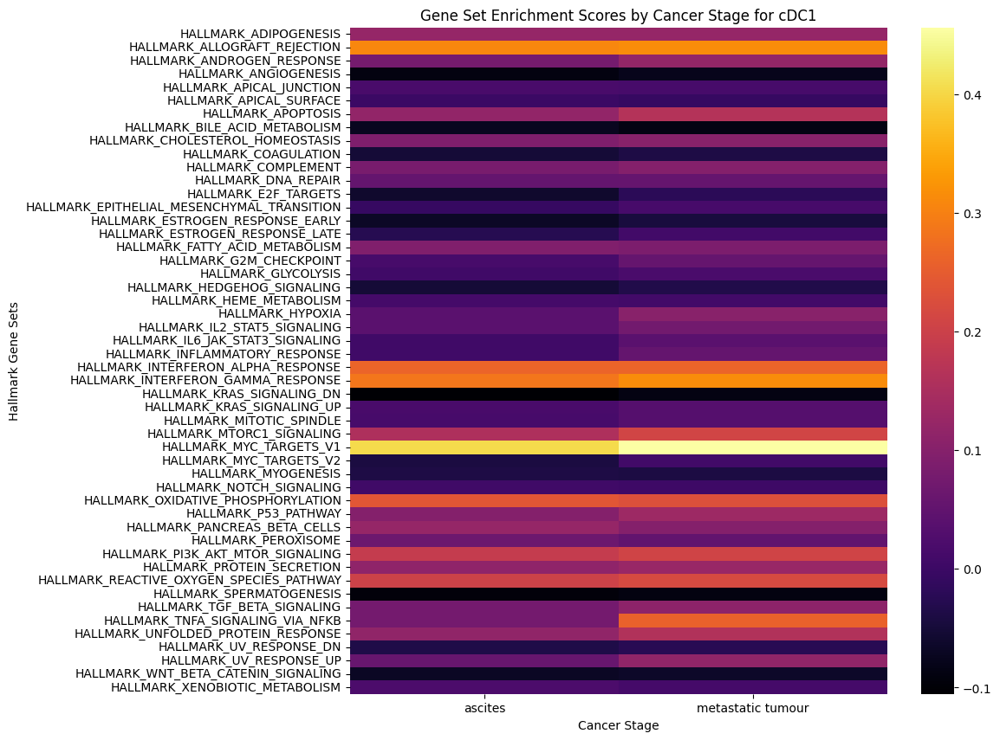

/scratch/temp/25256248/ipykernel_2078942/2643245652.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


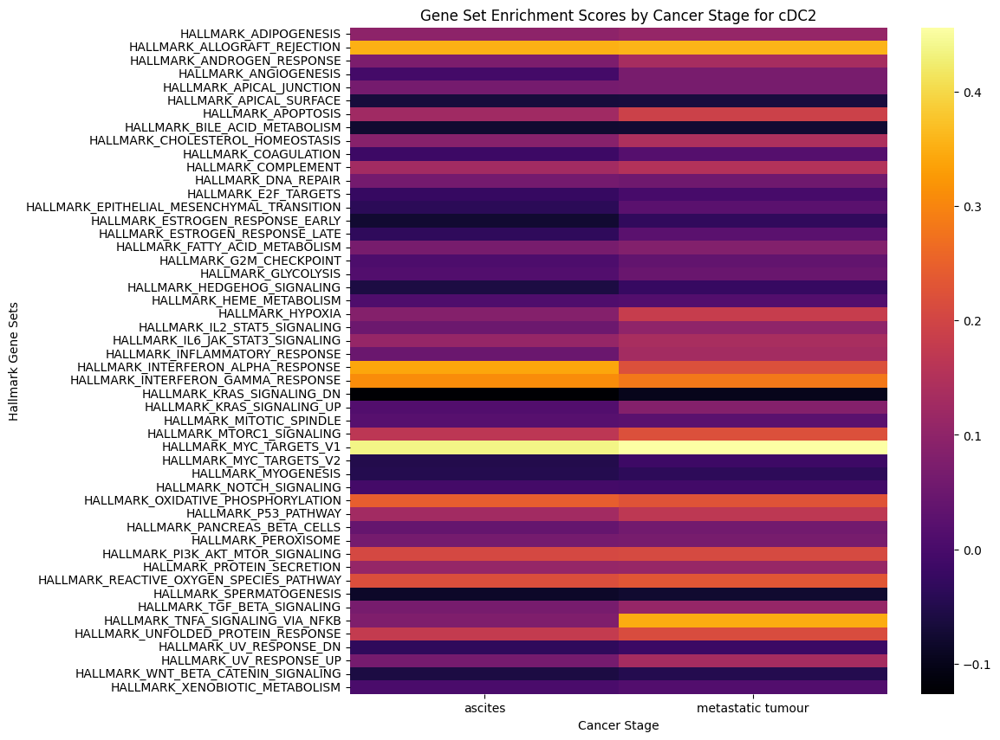

/scratch/temp/25256248/ipykernel_2078942/2643245652.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


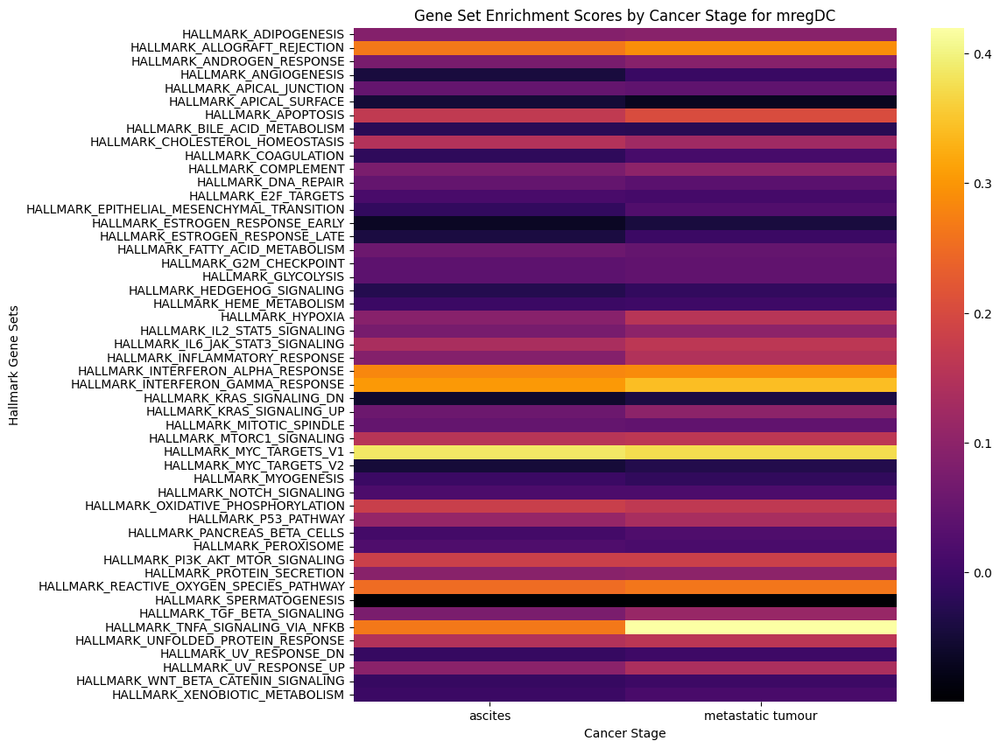

In [62]:
#DC1: 
# Extract gene set scores from `data_DC1.obs`
gene_set_scores = pd.DataFrame({
    set_name: data_DC1.obs[f"{set_name}_score"]
    for set_name in H_sets.keys()
})

# Add the sample_type_major2 metadata as a column
gene_set_scores["sample_type_major2"] = data_DC1.obs["sample_type_major2"].values

# Group by sample_type_major2 and compute mean scores for each group
grouped_scores = gene_set_scores.groupby("sample_type_major2").mean().T

# Plot the heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(grouped_scores, cmap="inferno", yticklabels=True, xticklabels=True)
plt.xlabel("Cancer Stage")
plt.ylabel("Hallmark Gene Sets")
plt.title("Gene Set Enrichment Scores by Cancer Stage for cDC1")
plt.show()

#DC2:
# Extract gene set scores from `data_DC2.obs`
gene_set_scores = pd.DataFrame({
    set_name: data_DC2.obs[f"{set_name}_score"]
    for set_name in H_sets.keys()
})

# Add the sample_type_major2 metadata as a column
gene_set_scores["sample_type_major2"] = data_DC2.obs["sample_type_major2"].values

# Group by sample_type_major2 and compute mean scores for each group
grouped_scores = gene_set_scores.groupby("sample_type_major2").mean().T

# Plot the heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(grouped_scores, cmap="inferno", yticklabels=True, xticklabels=True)
plt.xlabel("Cancer Stage")
plt.ylabel("Hallmark Gene Sets")
plt.title("Gene Set Enrichment Scores by Cancer Stage for cDC2")
plt.show()

#mregDC:
# Extract gene set scores from `data_DC1.obs`
gene_set_scores = pd.DataFrame({
    set_name: data_mregDC.obs[f"{set_name}_score"]
    for set_name in H_sets.keys()
})

# Add the sample_type_major2 metadata as a column
gene_set_scores["sample_type_major2"] = data_mregDC.obs["sample_type_major2"].values

# Group by sample_type_major2 and compute mean scores for each group
grouped_scores = gene_set_scores.groupby("sample_type_major2").mean().T

# Plot the heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(grouped_scores, cmap="inferno", yticklabels=True, xticklabels=True)
plt.xlabel("Cancer Stage")
plt.ylabel("Hallmark Gene Sets")
plt.title("Gene Set Enrichment Scores by Cancer Stage for mregDC")
plt.show()

### Repeat for KEGG pathways

Import KEGG gene sets
* will be imported as a dictionary where each key is a sheet name, and each value is a dataframe (gene sets)

In [63]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
K_sets = pd.read_excel("kegg_sets.xlsx", sheet_name=None)

os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets'

In [64]:
# Print the sheet names
print(K_sets.keys())

dict_keys(['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5', 'Sheet6', 'Sheet7', 'Sheet8', 'Sheet9', 'Sheet10', 'Sheet11', 'Sheet12', 'Sheet13', 'Sheet14', 'Sheet15', 'Sheet16', 'Sheet17', 'Sheet18', 'Sheet19', 'Sheet20', 'Sheet21', 'Sheet22', 'Sheet23', 'Sheet24', 'Sheet25', 'Sheet26', 'Sheet27', 'Sheet28', 'Sheet29', 'Sheet30', 'Sheet31', 'Sheet32', 'Sheet33', 'Sheet34', 'Sheet35', 'Sheet36', 'Sheet37', 'Sheet38', 'Sheet39', 'Sheet40', 'Sheet41', 'Sheet42', 'Sheet43', 'Sheet44', 'Sheet45', 'Sheet46', 'Sheet47', 'Sheet48', 'Sheet49', 'Sheet50', 'Sheet51', 'Sheet52', 'Sheet53', 'Sheet54', 'Sheet55', 'Sheet56', 'Sheet57', 'Sheet58', 'Sheet59', 'Sheet60', 'Sheet61', 'Sheet62', 'Sheet63', 'Sheet64', 'Sheet65', 'Sheet66', 'Sheet67', 'Sheet68', 'Sheet69', 'Sheet70', 'Sheet71', 'Sheet72', 'Sheet73', 'Sheet74', 'Sheet75', 'Sheet76', 'Sheet77', 'Sheet78', 'Sheet79', 'Sheet80', 'Sheet81', 'Sheet82', 'Sheet83', 'Sheet84', 'Sheet85', 'Sheet86', 'Sheet87', 'Sheet88', 'Sheet89', 'Sheet90', 'Sheet91

In [65]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
K_sets2 = {df["gs_name"].iloc[0]: df for _, df in K_sets.items()}
K_sets = K_sets2

# Result
print(K_sets.keys())

dict_keys(['KEGG_ABC_TRANSPORTERS', 'KEGG_ACUTE_MYELOID_LEUKEMIA', 'KEGG_ADHERENS_JUNCTION', 'KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY', 'KEGG_ALANINE_ASPARTATE_AND_GLUTAMATE_METABOLISM', 'KEGG_ALDOSTERONE_REGULATED_SODIUM_REABSORPTION', 'KEGG_ALLOGRAFT_REJECTION', 'KEGG_ALPHA_LINOLENIC_ACID_METABOLISM', 'KEGG_ALZHEIMERS_DISEASE', 'KEGG_AMINO_SUGAR_AND_NUCLEOTIDE_SUGAR_METABOLISM', 'KEGG_AMINOACYL_TRNA_BIOSYNTHESIS', 'KEGG_AMYOTROPHIC_LATERAL_SCLEROSIS_ALS', 'KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION', 'KEGG_APOPTOSIS', 'KEGG_ARACHIDONIC_ACID_METABOLISM', 'KEGG_ARGININE_AND_PROLINE_METABOLISM', 'KEGG_ARRHYTHMOGENIC_RIGHT_VENTRICULAR_CARDIOMYOPATHY_ARVC', 'KEGG_ASCORBATE_AND_ALDARATE_METABOLISM', 'KEGG_ASTHMA', 'KEGG_AUTOIMMUNE_THYROID_DISEASE', 'KEGG_AXON_GUIDANCE', 'KEGG_B_CELL_RECEPTOR_SIGNALING_PATHWAY', 'KEGG_BASAL_CELL_CARCINOMA', 'KEGG_BASAL_TRANSCRIPTION_FACTORS', 'KEGG_BASE_EXCISION_REPAIR', 'KEGG_BETA_ALANINE_METABOLISM', 'KEGG_BIOSYNTHESIS_OF_UNSATURATED_FATTY_ACIDS', 'KEGG_BLADDE

In [66]:
K_sets

{'KEGG_ABC_TRANSPORTERS':    gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0        ABCA1         19  ENSG00000165029          ABCA1            19   
 1       ABCA10      10349  ENSG00000154263         ABCA10         10349   
 2       ABCA12      26154  ENSG00000144452         ABCA12         26154   
 3       ABCA13     154664  ENSG00000179869         ABCA13        154664   
 4        ABCA2         20  ENSG00000107331          ABCA2            20   
 5        ABCA3         21  ENSG00000167972          ABCA3            21   
 6        ABCA4         24  ENSG00000198691          ABCA4            24   
 7        ABCA5      23461  ENSG00000154265          ABCA5         23461   
 8        ABCA6      23460  ENSG00000154262          ABCA6         23460   
 9        ABCA7      10347  ENSG00000064687          ABCA7         10347   
 10       ABCA8      10351  ENSG00000141338          ABCA8         10351   
 11       ABCA9      10350  ENSG00000154258          ABCA9     

### Remove unwanted sets so only select sets remain

In [67]:
# Keys to include in new dictionary
keys_include = ["KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY",
"KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION",
"KEGG_APOPTOSIS",
"KEGG_CALCIUM_SIGNALING_PATHWAY",
"KEGG_CELL_ADHESION_MOLECULES_CAMS",
"KEGG_CHEMOKINE_SIGNALING_PATHWAY",
"KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION",
"KEGG_CYTOSOLIC_DNA_SENSING_PATHWAY",
"KEGG_ENDOCYTOSIS",
"KEGG_FATTY_ACID_METABOLISM",
"KEGG_FC_GAMMA_R_MEDIATED_PHAGOCYTOSIS",
"KEGG_GLYCOLYSIS_GLUCONEOGENESIS",
"KEGG_JAK_STAT_SIGNALING_PATHWAY",
"KEGG_LEUKOCYTE_TRANSENDOTHELIAL_MIGRATION",
"KEGG_MAPK_SIGNALING_PATHWAY",
"KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_NOTCH_SIGNALING_PATHWAY",
"KEGG_OXIDATIVE_PHOSPHORYLATION",
"KEGG_PROTEASOME",
"KEGG_PROTEIN_EXPORT",
"KEGG_TGF_BETA_SIGNALING_PATHWAY",
"KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_TYROSINE_METABOLISM",
"KEGG_UBIQUITIN_MEDIATED_PROTEOLYSIS",
"KEGG_VEGF_SIGNALING_PATHWAY"]

In [68]:
# create a new dictionary with select keys (pathway sets)
K_sets_sub = {key: K_sets[key] for key in keys_include if key in K_sets}

# Display the new dictionary
K_sets_sub

{'KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY':    gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0        ACACB         32  ENSG00000076555          ACACB            32   
 1        ACSL1       2180  ENSG00000151726          ACSL1          2180   
 2        ACSL3       2181  ENSG00000123983          ACSL3          2181   
 3        ACSL4       2182  ENSG00000068366          ACSL4          2182   
 4        ACSL5      51703  ENSG00000197142          ACSL5         51703   
 ..         ...        ...              ...            ...           ...   
 62         TNF       7124  ENSG00000232810            TNF          7124   
 63    TNFRSF1A       7132  ENSG00000067182       TNFRSF1A          7132   
 64    TNFRSF1B       7133  ENSG00000028137       TNFRSF1B          7133   
 65       TRADD       8717  ENSG00000102871          TRADD          8717   
 66       TRAF2       7186  ENSG00000127191          TRAF2          7186   
 
     db_ensembl_gene  source_gene   gs_id  \
 

### Check data is seperated in each DC subset

In [69]:
data_DC1

AnnData object with n_obs × n_vars = 1692 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'HALLMARK_ADIPOGENESIS_score', 'HALLMARK_ALLOGRAFT_REJECTION_score', 'HALLMARK_ANDROGEN_RESPONSE_score', 'HALLMARK_ANGIOGENESIS_score', 'HALLMARK_APICAL_JUNCTION_score', 'HALLMARK_APICAL_SURFACE_

In [70]:
#Check the sample type information recorded in the dataset, sample_type_major2 defines primary vs mets vs ascites vs ascites
data_DC1.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              1025
metastatic tumour     667
Name: count, dtype: int64

In [71]:
data_DC2

AnnData object with n_obs × n_vars = 4038 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'HALLMARK_ADIPOGENESIS_score', 'HALLMARK_ALLOGRAFT_REJECTION_score', 'HALLMARK_ANDROGEN_RESPONSE_score', 'HALLMARK_ANGIOGENESIS_score', 'HALLMARK_APICAL_JUNCTION_score', 'HALLMARK_APICAL_SURFACE_

In [72]:
data_mregDC

AnnData object with n_obs × n_vars = 788 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'HALLMARK_ADIPOGENESIS_score', 'HALLMARK_ALLOGRAFT_REJECTION_score', 'HALLMARK_ANDROGEN_RESPONSE_score', 'HALLMARK_ANGIOGENESIS_score', 'HALLMARK_APICAL_JUNCTION_score', 'HALLMARK_APICAL_SURFACE_s

### Score DC subsets by enrichment for each gene set (each dataframe in dictionary)

In [73]:
# Iterate through each gene set in K_sets_sub - DC1
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_DC1, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - DC2
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_DC2, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - mregDC
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_mregDC, gene_list=gene_set, score_name=f"{set_name}_score")
     

       'PPARGC1A', 'PRKAG3'],
      dtype='object')
       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL5A', 'KIR2DS1', 'KIR2DS3',
       'KIR2DS4', 'KIR2DS5', 'KIR3DL3'],
      dtype='object')
       'AVPR1A', 'AVPR1B', 'BDKRB1', 'CACNA1B', 'CACNA1E', 'CACNA1I',
       'CACNA1S', 'CALML6', 'CAMK2A', 'CCKAR', 'CCKBR', 'CHP2', 'CHRM1',
       'CHRM2', 'CHRM5', 'DRD1', 'DRD5', 'GRM1', 'GRM5', 'GRPR', 'HTR2A',
       'HTR2C', 'HTR4', 'HTR5A', 'HTR6', 'LHCGR', 'MYLK2', 'MYLK3', 'NOS2',
       'P2RX3', 'P2RX6', 'PLCZ1', 'PLN', 'PPP3R2', 'PRKACG', 'PTGFR',
       'SLC25A31', 'TACR3', 'TRHR', 'VDAC2P5'],
      dtype='object')
       'CLDN6', 'CLDN8', 'HLA-DRB3', 'HLA-DRB4', 'NECTIN1', 'NECTIN2',
       'NECTIN3', 'NLGN4X', 'PECAM1'],
      dtype='object')
       'CCL3L3', 'CCR8', 'CXCL8', 'GNG13', 'GRK1', 'GRK2', 'GRK3', 'PF4V1',
       'PPBPP1', 'PRKACG'],
      dtype='object')
       'CCR8', 'CNTFR', 'CXCL8', 'EDAR', 'EPO', 'G

### Perform ANOVA

In [74]:
# cDC1:

# Initialize a results dictionary to store p-values
stats_results = {}

# Iterate through each gene set
for set_name in K_sets_sub.keys():
    # Extract the scores and corresponding cancer types
    scores = data_DC1.obs[f"{set_name}_score"]
    cancer_types = data_DC1.obs["sample_type_major2"]

    # Perform ANOVA
    groups = [scores[cancer_types == ct] for ct in cancer_types.unique()]
    f_stat, p_value = stats.f_oneway(*groups)

    # Save the results
    stats_results[set_name] = {
        "p_value": p_value,
        "f_stat": f_stat
    }

    # Perform post-hoc test if p_value is significant
    if p_value < 0.05:
        posthoc = pairwise_tukeyhsd(endog=scores, groups=cancer_types, alpha=0.05)
        print(f"Post-hoc results for {set_name}:")
        print(posthoc)

# Convert the results to a dataframe for easier viewing
results_df = pd.DataFrame(stats_results).T
print(results_df)

Post-hoc results for KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY:
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
 group1       group2      meandiff p-adj lower  upper  reject
-------------------------------------------------------------
ascites metastatic tumour   0.0199   0.0 0.0156 0.0242   True
-------------------------------------------------------------
Post-hoc results for KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION:
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
 group1       group2      meandiff p-adj lower  upper  reject
-------------------------------------------------------------
ascites metastatic tumour   0.0411   0.0 0.0291 0.0531   True
-------------------------------------------------------------
Post-hoc results for KEGG_APOPTOSIS:
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
 group1       group2      meandiff p-adj lower  upper  reject
-------------------------------------------------------------
ascites metastatic tumour   0.0234 

## Generate a heatmap of results for the KEGG sets

/scratch/temp/25256248/ipykernel_2078942/3706099655.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


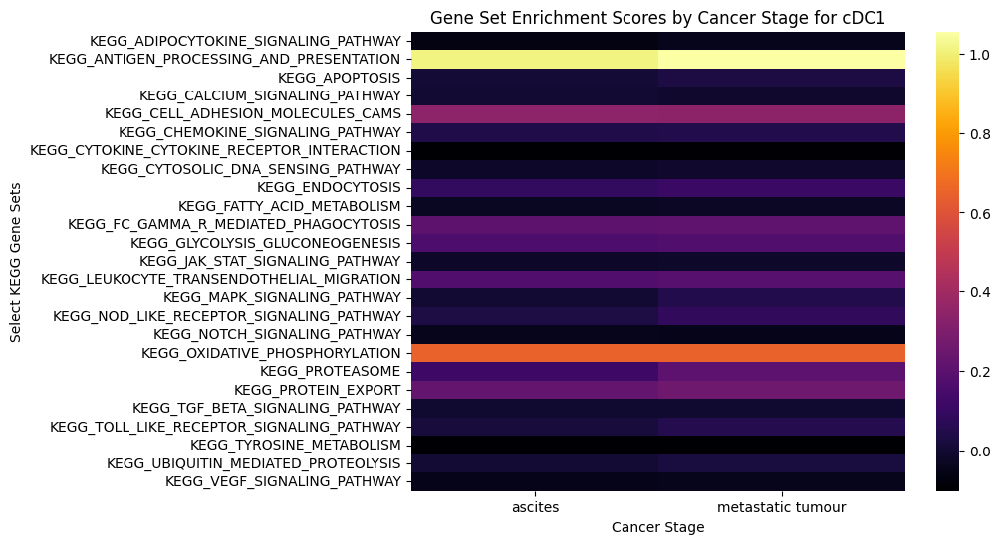

/scratch/temp/25256248/ipykernel_2078942/3706099655.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


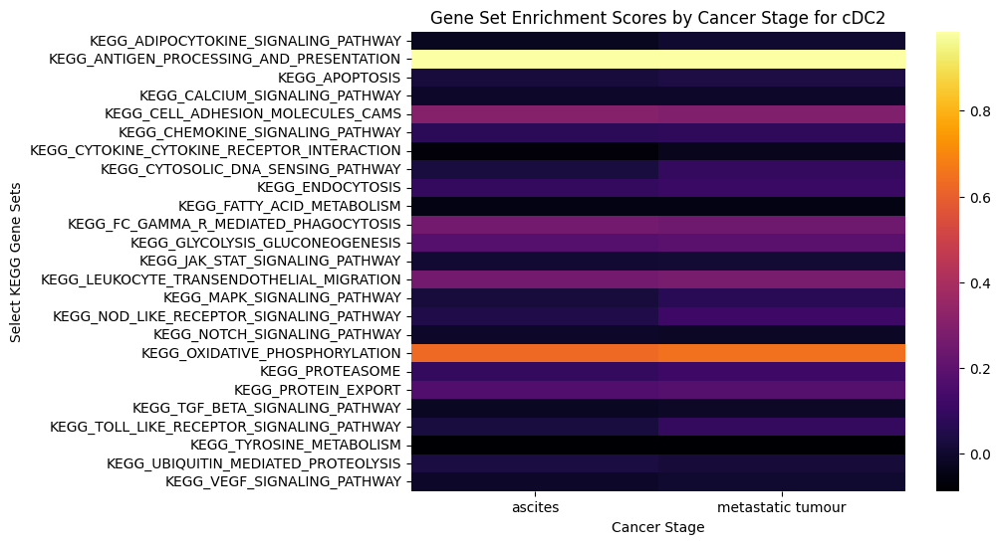

/scratch/temp/25256248/ipykernel_2078942/3706099655.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


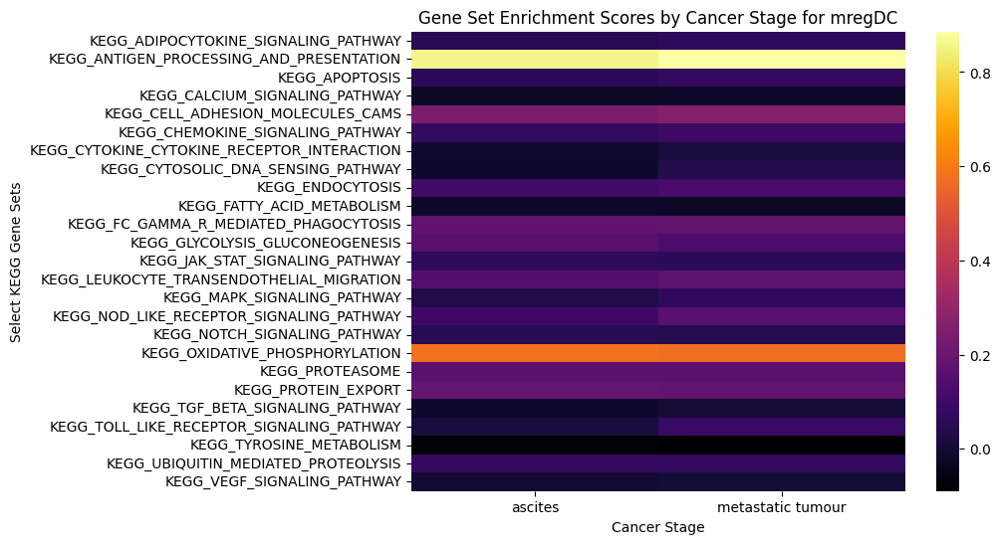

In [75]:
#DC1: 
# Extract gene set scores from `data_DC1.obs`
gene_set_scores = pd.DataFrame({
    set_name: data_DC1.obs[f"{set_name}_score"]
    for set_name in K_sets_sub.keys()
})

# Add the sample_type_major2 metadata as a column
gene_set_scores["sample_type_major2"] = data_DC1.obs["sample_type_major2"].values

# Group by sample_type_major2 and compute mean scores for each group
grouped_scores = gene_set_scores.groupby("sample_type_major2").mean().T

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(grouped_scores, cmap="inferno", yticklabels=True, xticklabels=True)
plt.xlabel("Cancer Stage")
plt.ylabel("Select KEGG Gene Sets")
plt.title("Gene Set Enrichment Scores by Cancer Stage for cDC1")
plt.show()

#DC2:
# Extract gene set scores from `data_DC2.obs`
gene_set_scores = pd.DataFrame({
    set_name: data_DC2.obs[f"{set_name}_score"]
    for set_name in K_sets_sub.keys()
})

# Add the sample_type_major2 metadata as a column
gene_set_scores["sample_type_major2"] = data_DC2.obs["sample_type_major2"].values

# Group by sample_type_major2 and compute mean scores for each group
grouped_scores = gene_set_scores.groupby("sample_type_major2").mean().T

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(grouped_scores, cmap="inferno", yticklabels=True, xticklabels=True)
plt.xlabel("Cancer Stage")
plt.ylabel("Select KEGG Gene Sets")
plt.title("Gene Set Enrichment Scores by Cancer Stage for cDC2")
plt.show()

#mregDC:
# Extract gene set scores from `data_DC1.obs`
gene_set_scores = pd.DataFrame({
    set_name: data_mregDC.obs[f"{set_name}_score"]
    for set_name in K_sets_sub.keys()
})

# Add the sample_type_major2 metadata as a column
gene_set_scores["sample_type_major2"] = data_mregDC.obs["sample_type_major2"].values

# Group by sample_type_major2 and compute mean scores for each group
grouped_scores = gene_set_scores.groupby("sample_type_major2").mean().T

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(grouped_scores, cmap="inferno", yticklabels=True, xticklabels=True)
plt.xlabel("Cancer Stage")
plt.ylabel("Select KEGG Gene Sets")
plt.title("Gene Set Enrichment Scores by Cancer Stage for mregDC")
plt.show()
     

## Do per sample - generate score for DC1s

### KEGG Pathways

In [76]:
# Create a dictionary to store mean scores per sample
sample_scores = {}

# Iterate through each gene set
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()

    # Score the cells using the gene set
    sc.tl.score_genes(data_DC1, gene_list=gene_set, score_name=f"{set_name}_score")


# Select only numeric columns for aggregation
numeric_columns = [f"{set_name}_score" for set_name in K_sets_sub.keys()]

# Ensure these columns exist in data_DC1.obs
numeric_columns = [col for col in numeric_columns if col in data_DC1.obs.columns]

# Group by 'integration_id' and calculate mean only for numeric columns
sample_scores_df = data_DC1.obs.groupby("integration_id")[numeric_columns].mean()

# Add the sample_type_major2 metadata for each sample
sample_scores_df["sample_type_major2"] = data_DC1.obs.groupby("integration_id")["sample_type_major2"].first()
     

       'PPARGC1A', 'PRKAG3'],
      dtype='object')
       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL5A', 'KIR2DS1', 'KIR2DS3',
       'KIR2DS4', 'KIR2DS5', 'KIR3DL3'],
      dtype='object')
       'AVPR1A', 'AVPR1B', 'BDKRB1', 'CACNA1B', 'CACNA1E', 'CACNA1I',
       'CACNA1S', 'CALML6', 'CAMK2A', 'CCKAR', 'CCKBR', 'CHP2', 'CHRM1',
       'CHRM2', 'CHRM5', 'DRD1', 'DRD5', 'GRM1', 'GRM5', 'GRPR', 'HTR2A',
       'HTR2C', 'HTR4', 'HTR5A', 'HTR6', 'LHCGR', 'MYLK2', 'MYLK3', 'NOS2',
       'P2RX3', 'P2RX6', 'PLCZ1', 'PLN', 'PPP3R2', 'PRKACG', 'PTGFR',
       'SLC25A31', 'TACR3', 'TRHR', 'VDAC2P5'],
      dtype='object')
       'CLDN6', 'CLDN8', 'HLA-DRB3', 'HLA-DRB4', 'NECTIN1', 'NECTIN2',
       'NECTIN3', 'NLGN4X', 'PECAM1'],
      dtype='object')
       'CCL3L3', 'CCR8', 'CXCL8', 'GNG13', 'GRK1', 'GRK2', 'GRK3', 'PF4V1',
       'PPBPP1', 'PRKACG'],
      dtype='object')
       'CCR8', 'CNTFR', 'CXCL8', 'EDAR', 'EPO', 'G

/scratch/temp/25256248/ipykernel_2078942/556443259.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/scratch/temp/25256248/ipykernel_2078942/556443259.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


/scratch/temp/25256248/ipykernel_2078942/2474769635.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


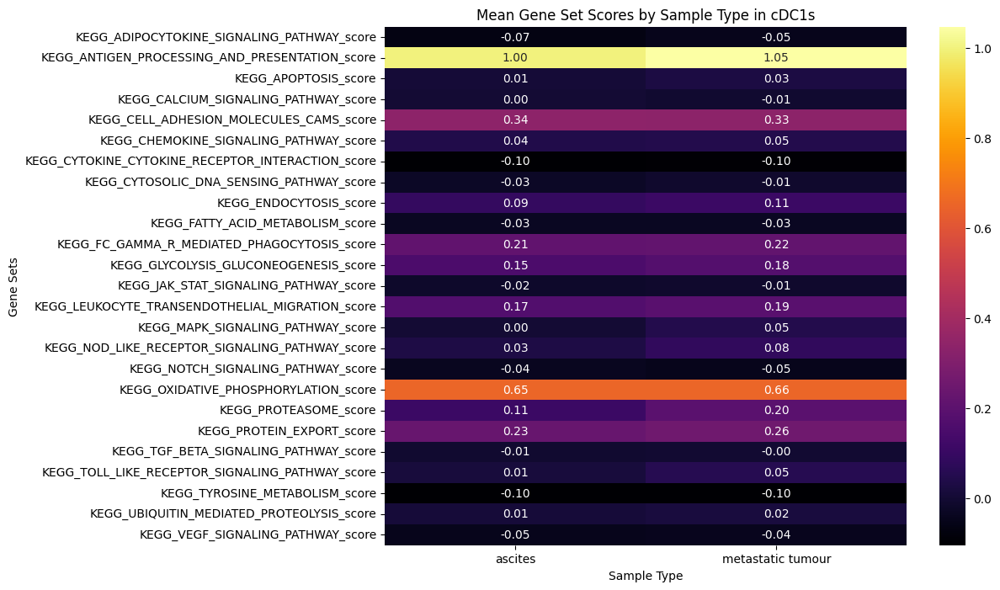

In [77]:
# Group by cancer type and compute the average score for each cancer type 
cancer_type_scores_df = sample_scores_df.groupby("sample_type_major2").mean()

# plot the scores
plt.figure(figsize=(10, 8))
sns.heatmap(cancer_type_scores_df.T, cmap="inferno", annot=True, fmt=".2f")
plt.xlabel("Sample Type")
plt.ylabel("Gene Sets")
plt.title("Mean Gene Set Scores by Sample Type in cDC1s")
plt.show()

In [78]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [79]:
data_DC1.obs.columns

Index(['nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type',
       'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major',
       'cancer_subtype',
       ...
       'KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY_score',
       'KEGG_NOTCH_SIGNALING_PATHWAY_score',
       'KEGG_OXIDATIVE_PHOSPHORYLATION_score', 'KEGG_PROTEASOME_score',
       'KEGG_PROTEIN_EXPORT_score', 'KEGG_TGF_BETA_SIGNALING_PATHWAY_score',
       'KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY_score',
       'KEGG_TYROSINE_METABOLISM_score',
       'KEGG_UBIQUITIN_MEDIATED_PROTEOLYSIS_score',
       'KEGG_VEGF_SIGNALING_PATHWAY_score'],
      dtype='object', length=118)

In [80]:
# Store results
comparison_results = []

# Use .obs dataframe from AnnData
obs_df = data_DC1.obs.copy()

# Keep only metastatic and ascites
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Loop through gene sets
for gene_set in K_sets_sub.keys():

    # Column name of pathway score
    score_col = f"{gene_set}_score"

    # Skip if pathway not present
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col} (not found)")
        continue

    # Split groups
    ascites_scores = obs_df.loc[
        obs_df["sample_type_major2"] == "ascites",
        score_col
    ]

    metastatic_scores = obs_df.loc[
        obs_df["sample_type_major2"] == "metastatic tumour",
        score_col
    ]

    # Skip empty groups
    if len(ascites_scores) == 0 or len(metastatic_scores) == 0:
        continue

    # Welch t-test
    stat, p_value = ttest_ind(
        ascites_scores,
        metastatic_scores,
        equal_var=False
    )

    # Means
    mean_ascites = ascites_scores.mean()
    mean_metastatic = metastatic_scores.mean()

    comparison_results.append({
        "Gene Set": gene_set,
        "Ascites Mean": mean_ascites,
        "Metastatic Mean": mean_metastatic,
        "Difference": mean_metastatic - mean_ascites,
        "P-value": p_value
    })

# Convert to dataframe
comparison_results_df = pd.DataFrame(comparison_results)

# FDR correction
comparison_results_df["FDR"] = multipletests(
    comparison_results_df["P-value"],
    method="fdr_bh"
)[1]

# Sort significant pathways first
comparison_results_df = comparison_results_df.sort_values("FDR")

comparison_results_df.head()

,Gene Set,Ascites Mean,Metastatic Mean,Difference,P-value,FDR
14,KEGG_MAPK_SIGNALING_PATHWAY,0.000781,0.048284,0.047504,5.834308e-152,1.458577e-150
15,KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY,0.034232,0.083862,0.049630,2.819669e-67,3.524586e-66
21,KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY,0.018708,0.054368,0.035660,9.127829e-46,7.606524e-45
18,KEGG_PROTEASOME,0.119517,0.202727,0.083210,1.530459e-29,9.565366e-29
8,KEGG_ENDOCYTOSIS,0.091824,0.109405,0.017581,1.012451e-28,5.062254e-28


In [81]:
from statannotations.Annotator import Annotator

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.554e-17 t=-8.658e+00


/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



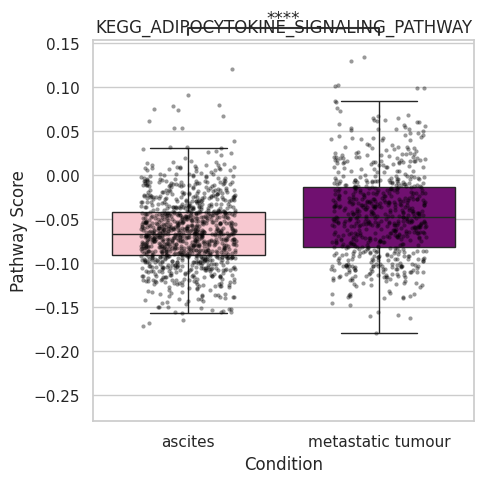

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.991e-10 t=-6.311e+00


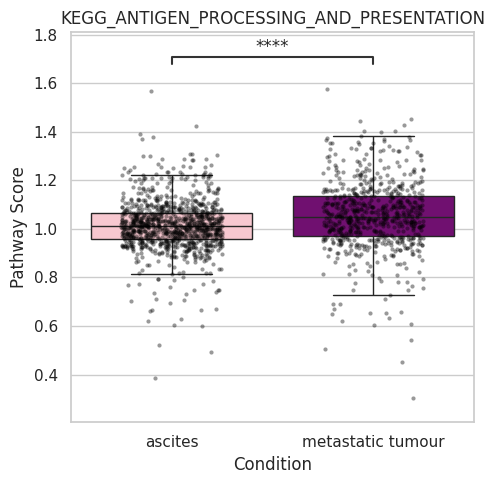

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.191e-23 t=-1.018e+01


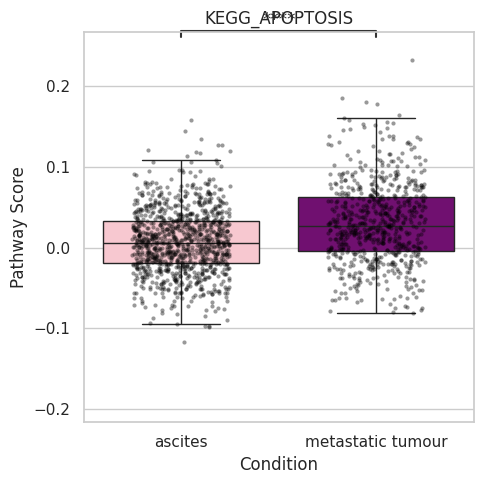

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.623e-17 t=8.574e+00


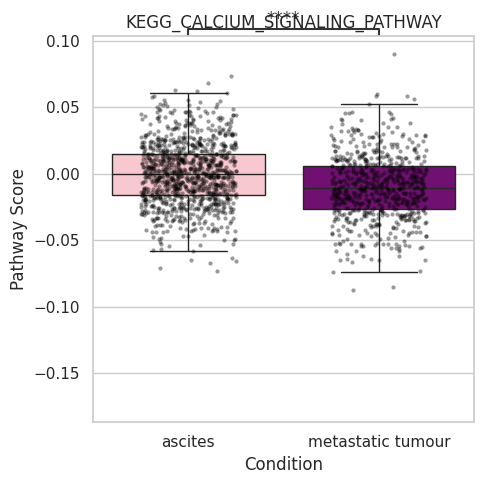

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.725e-01 t=1.365e+00


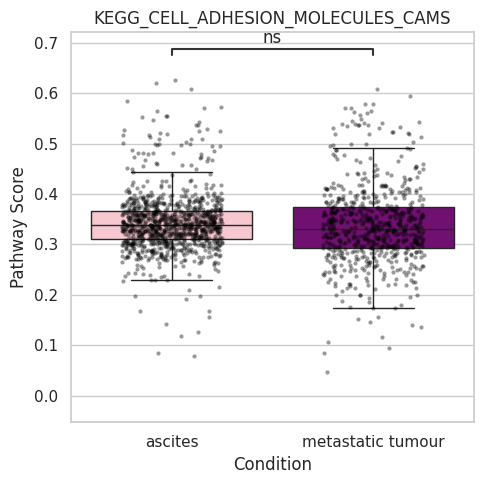

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.601e-01 t=-7.388e-01


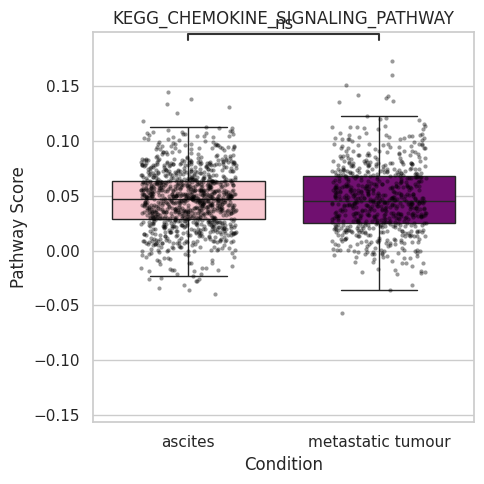

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.254e-03 t=-3.062e+00


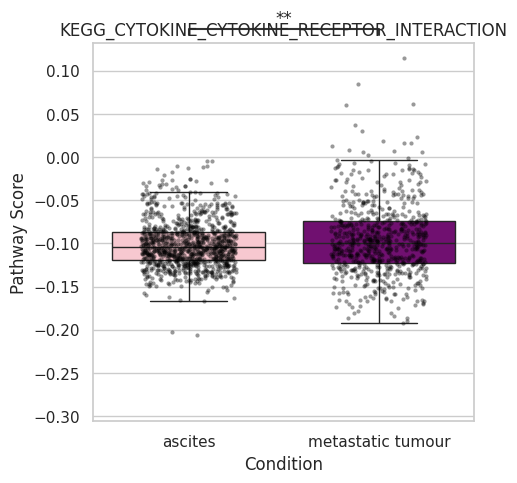

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.447e-03 t=-2.729e+00


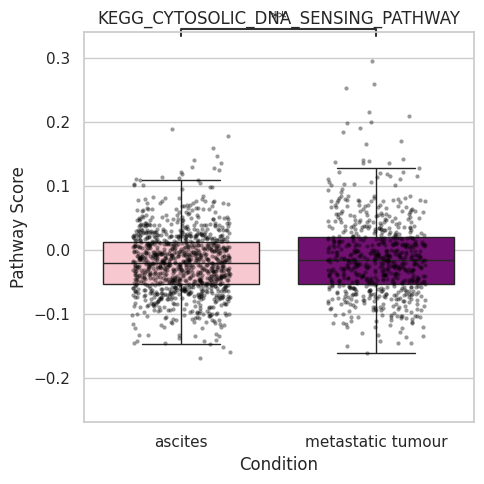

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.012e-28 t=-1.139e+01


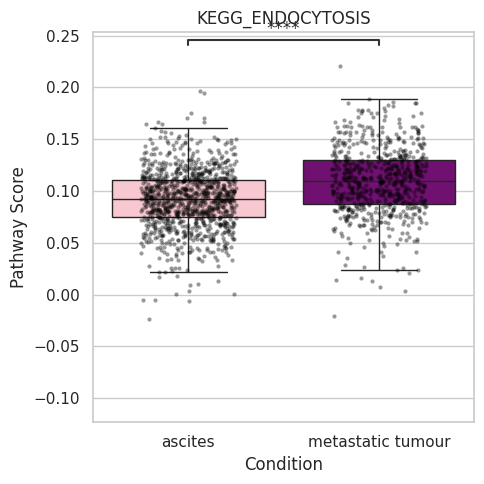

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.699e-01 t=-1.373e+00


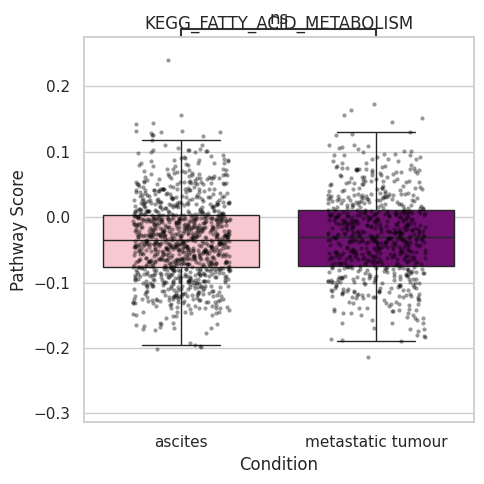

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.389e-01 t=-1.481e+00


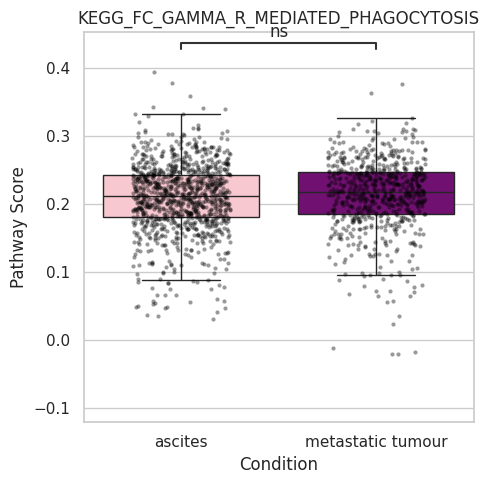

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.248e-02 t=-2.502e+00


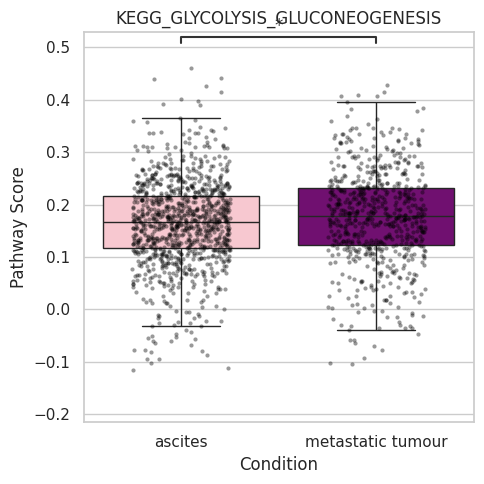

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.430e-04 t=-3.681e+00


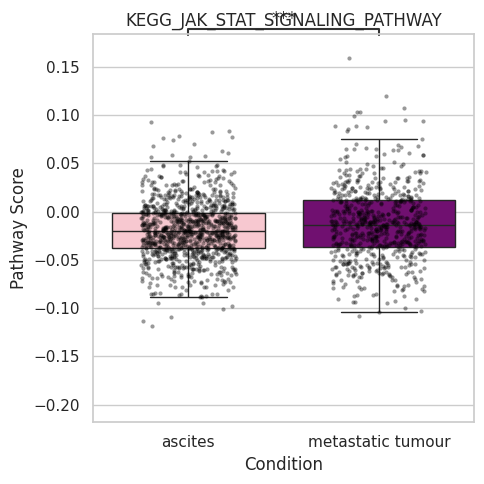

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.536e-09 t=-6.084e+00


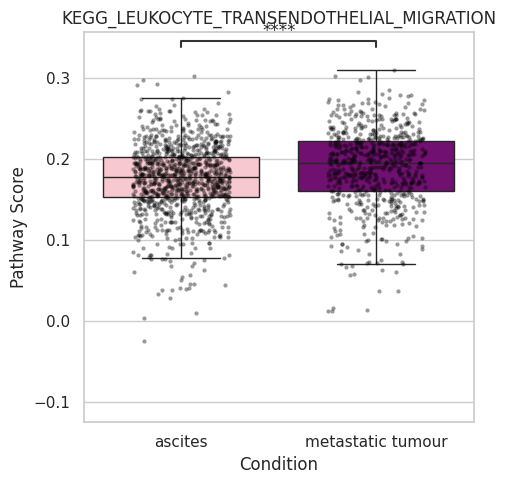

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.834e-152 t=-3.060e+01


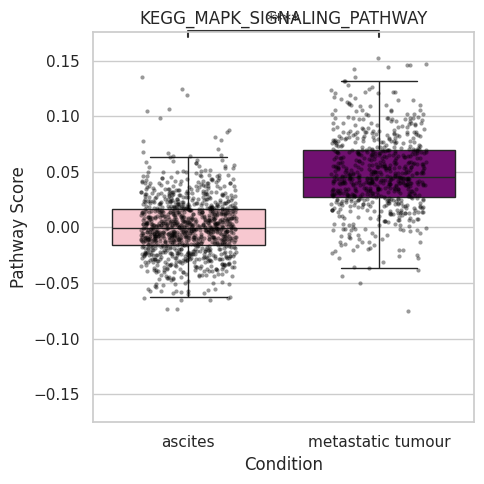

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.820e-67 t=-1.856e+01


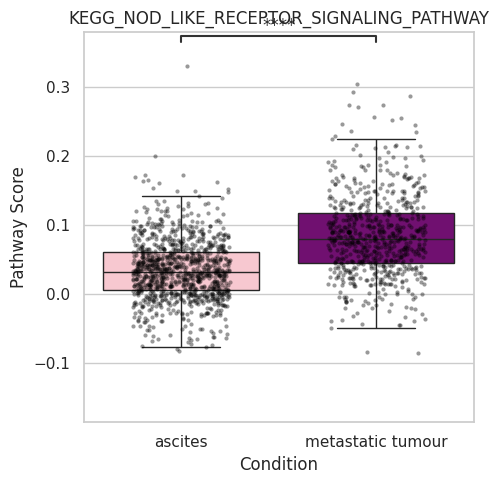

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.149e-01 t=8.156e-01


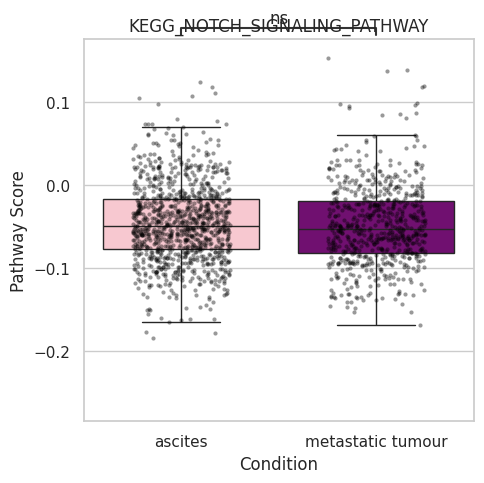

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.549e-01 t=-5.659e-02


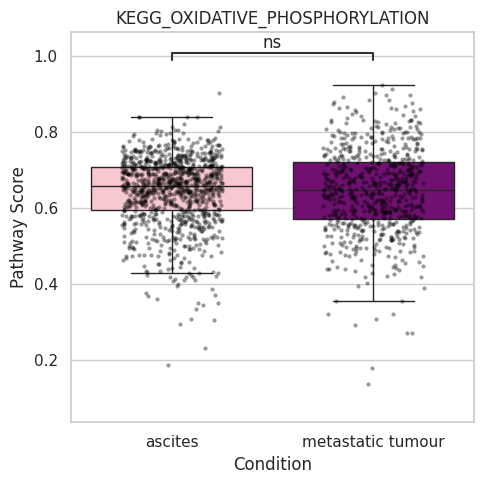

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.530e-29 t=-1.161e+01


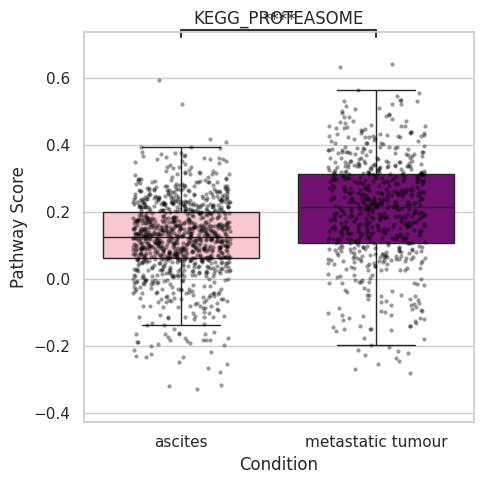

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.959e-07 t=-4.987e+00


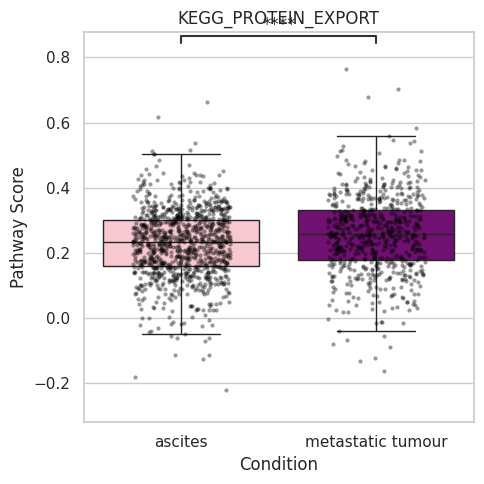

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.744e-03 t=-2.714e+00


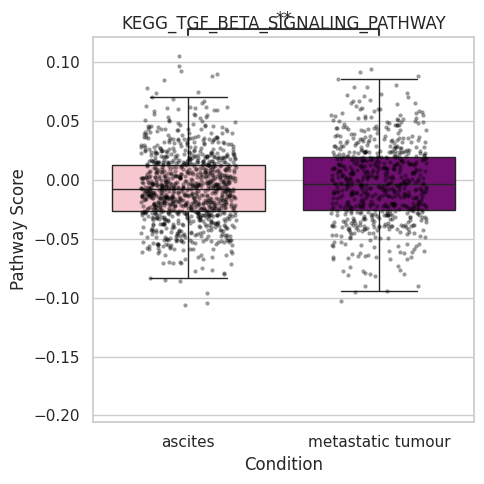

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.128e-46 t=-1.489e+01


/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



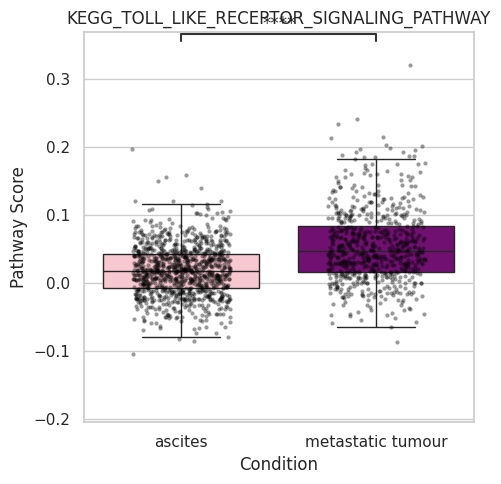

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.363e-01 t=-6.185e-01


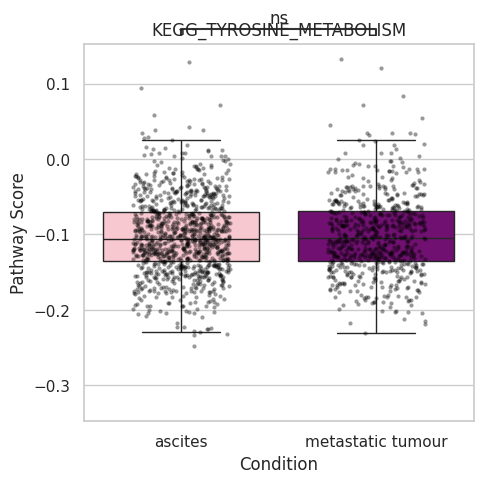

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.756e-19 t=-9.177e+00


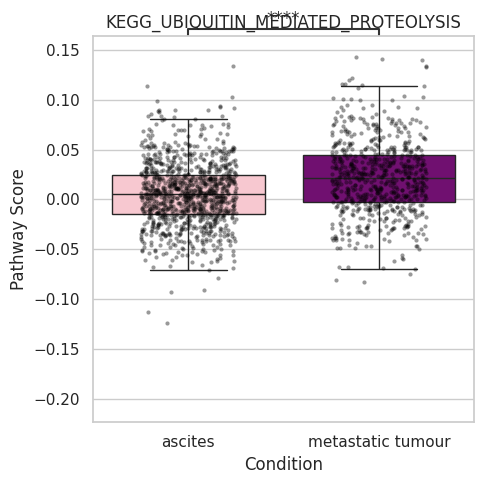

/scratch/temp/25256248/ipykernel_2078942/1889192475.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.302e-04 t=-3.599e+00


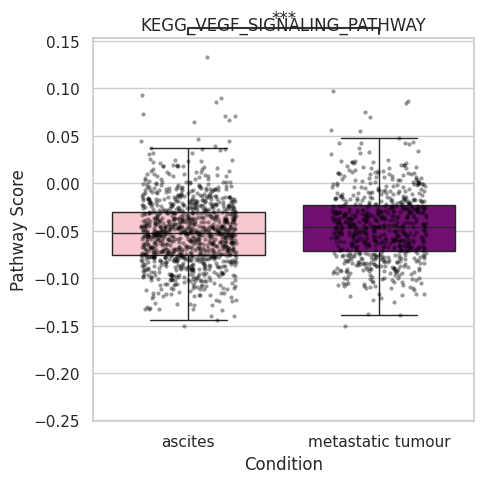

In [82]:
# Use .obs dataframe
obs_df = data_DC1.obs.copy()

# Keep only conditions of interest
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Set plotting style
sns.set(style="whitegrid")

# Consistent colour palette
palette = {
    "ascites": "#FFC0CB",     # pink
    "metastatic tumour": "#800080"   # purple
}

# Comparison pair
pairs = [("ascites", "metastatic tumour")]

# Loop through gene sets
for gene_set in K_sets_sub.keys():

    score_col = f"{gene_set}_score"

    # Skip missing pathways
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col}")
        continue

    # Remove NA values
    plot_df = obs_df[
        ["sample_type_major2", score_col]
    ].dropna()

    # Skip empty groups
    ascites_n = (
        plot_df["sample_type_major2"] == "ascites"
    ).sum()

    metastatic_n = (
        plot_df["sample_type_major2"] == "metastatic tumour"
    ).sum()

    if ascites_n == 0 or metastatic_n == 0:
        continue

    # Create figure
    plt.figure(figsize=(5, 5))

    ax = sns.boxplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        palette=palette,
        showfliers=False #removes boxplot outliers
    )

    sns.stripplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        #palette=palette,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.25     #True
    )

    # Add t-test annotation
    annotator = Annotator(
        ax,
        pairs,
        data=plot_df,
        x="sample_type_major2",
        y=score_col
    )

    annotator.configure(
        test="t-test_welch",
        text_format="star",   # or "simple"
        loc="outside"
    )

    annotator.apply_and_annotate()

     # ---- FIX OVERLAP ISSUE ----
    # Move title slightly higher
    ax.set_title(gene_set, pad=25)

    # Labels
    plt.title(gene_set)
    plt.xlabel("Condition")
    plt.ylabel("Pathway Score")

    # Give extra top margin so stars don't hit title
    plt.ylim(
        plot_df[score_col].min() - 0.1,
        plot_df[score_col].max() * 1.15
    )

    plt.tight_layout()
    plt.show()
     

### Hallmark Pathways

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.174e-01 t=-1.038e-01


/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



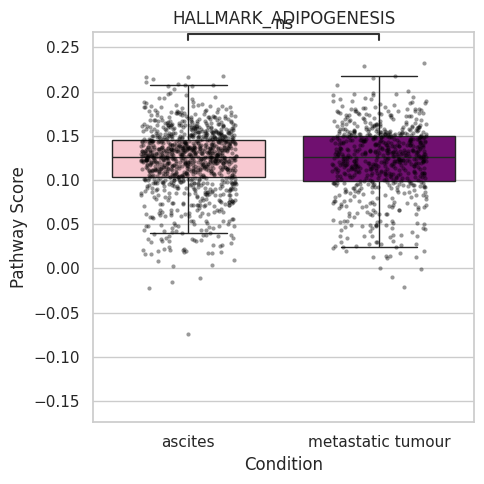

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.412e-04 t=-3.347e+00


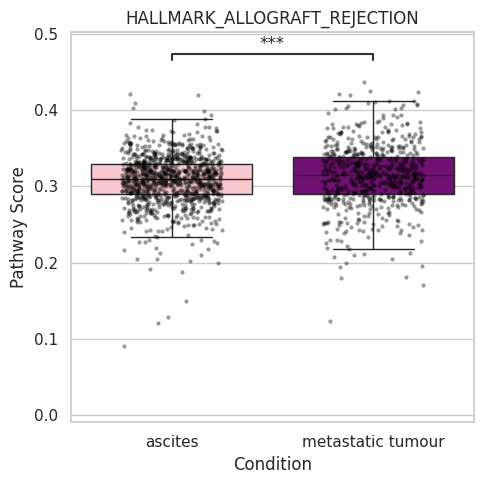

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.539e-75 t=-1.955e+01


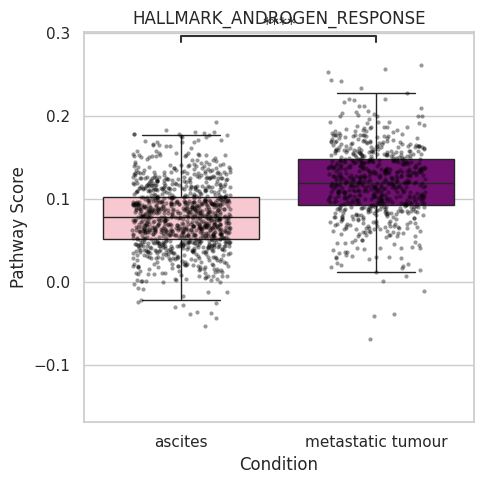

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.925e-04 t=-3.632e+00


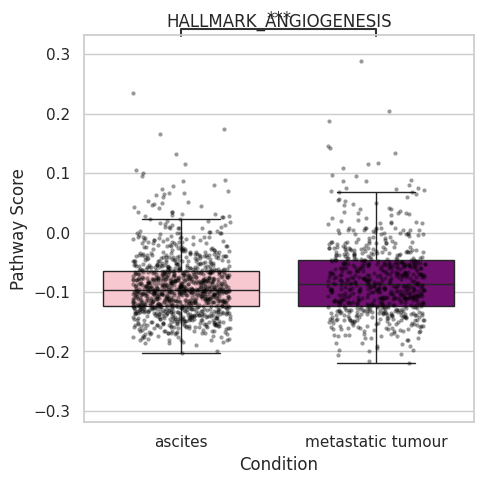

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.553e-02 t=2.423e+00


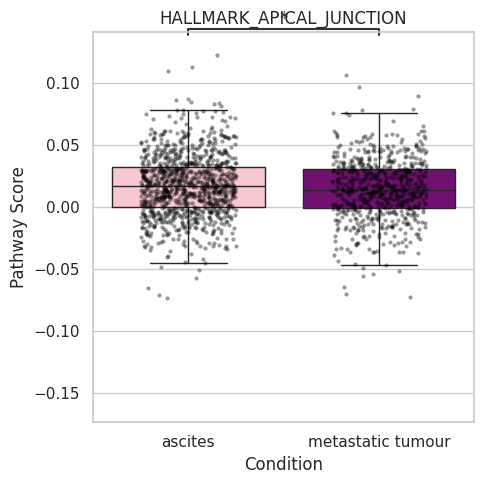

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.510e-02 t=2.433e+00


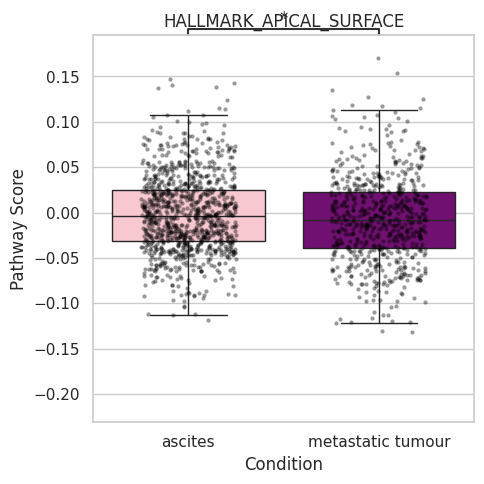

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.482e-83 t=-2.107e+01


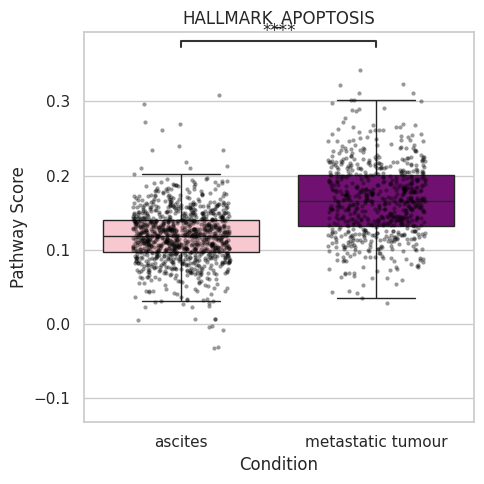

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.128e-20 t=9.359e+00


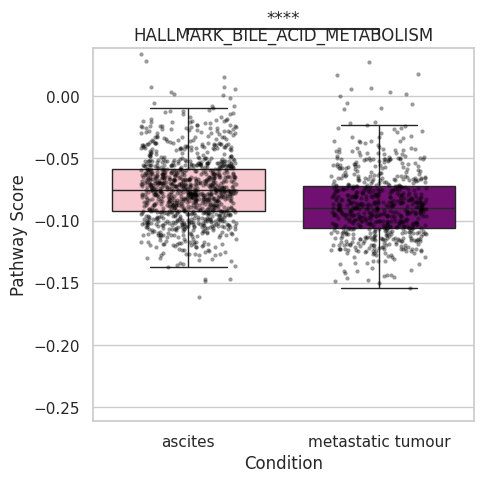

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.980e-06 t=-4.457e+00


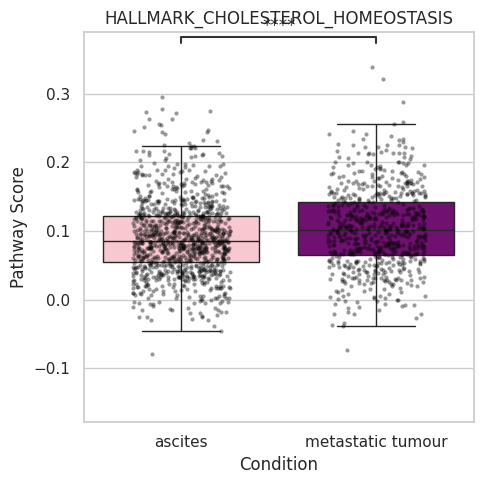

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.035e-11 t=-6.544e+00


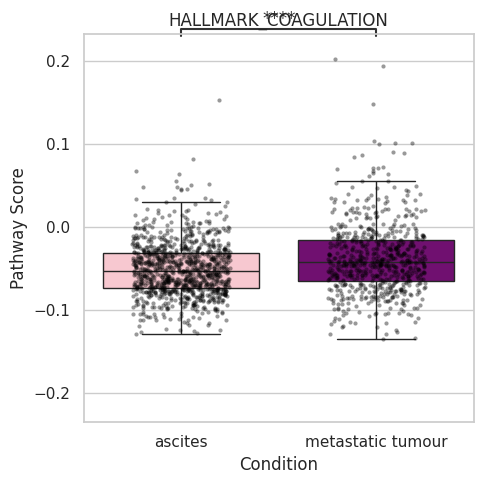

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.212e-16 t=-8.405e+00


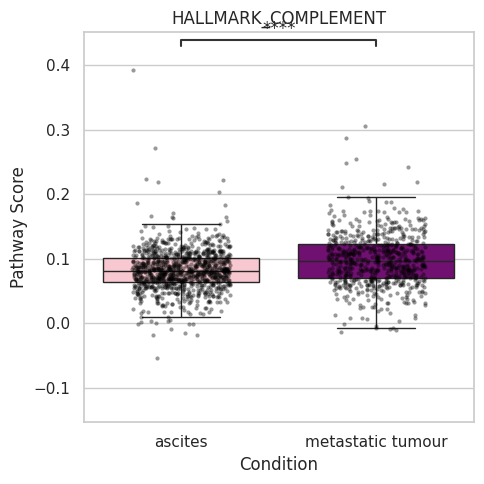

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.795e-01 t=-8.791e-01


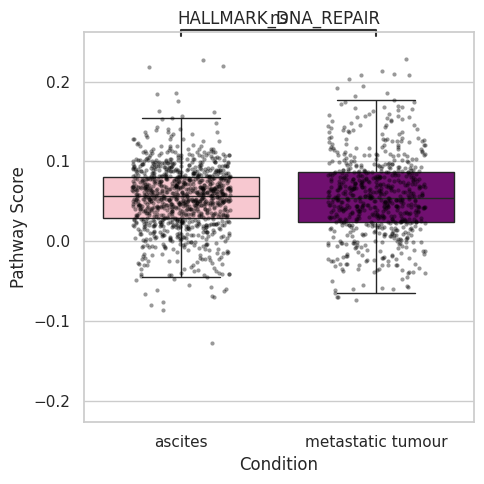

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.237e-21 t=-9.608e+00


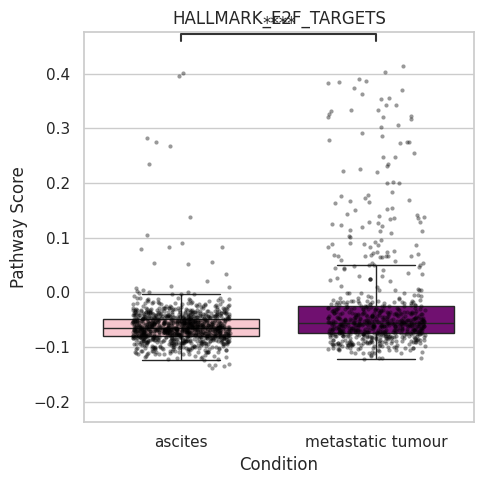

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.300e-47 t=-1.518e+01


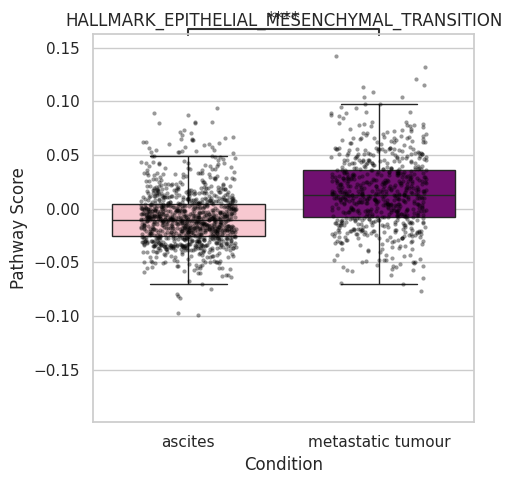

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.502e-59 t=-1.714e+01


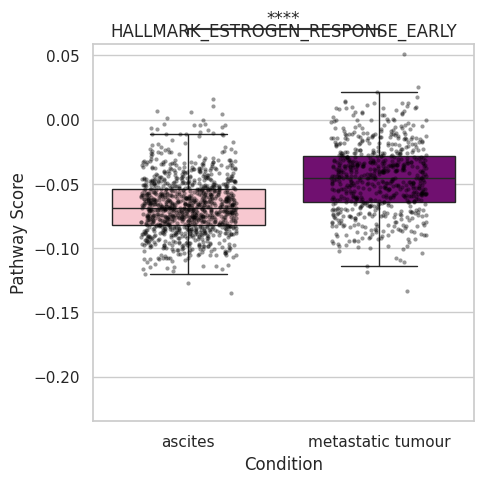

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.185e-116 t=-2.549e+01


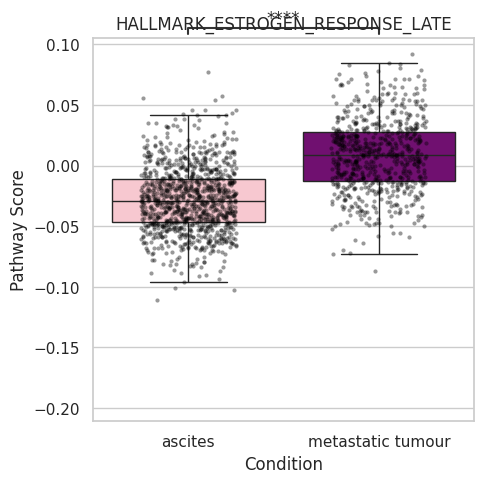

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.702e-02 t=2.389e+00


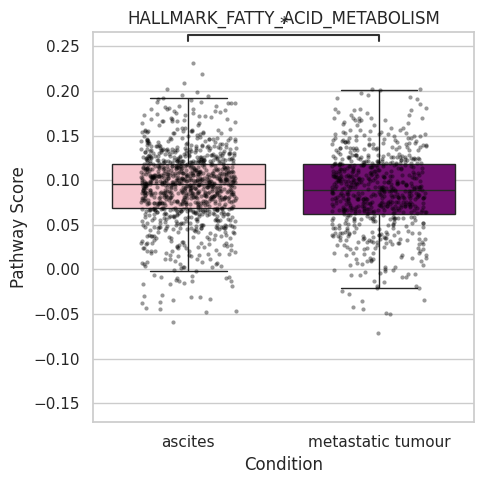

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.621e-29 t=-1.173e+01


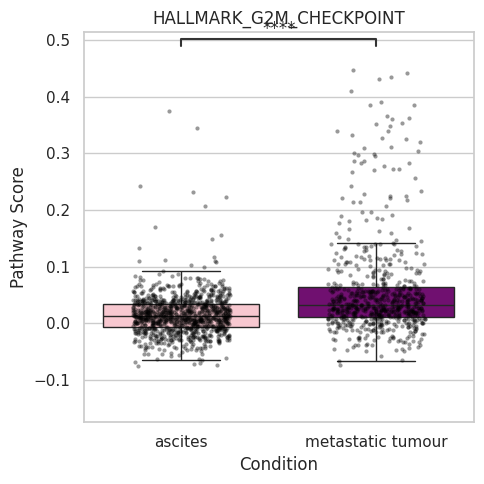

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.185e-18 t=-8.738e+00


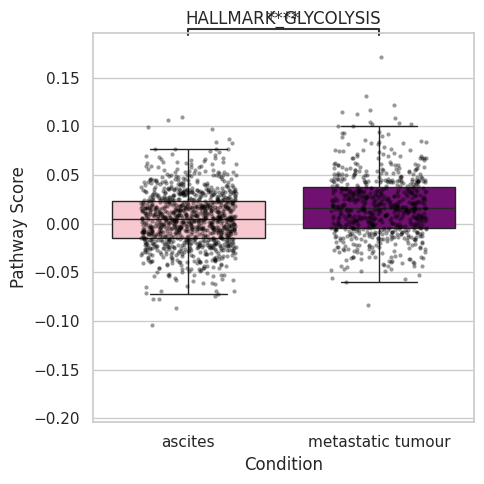

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.576e-14 t=-7.604e+00


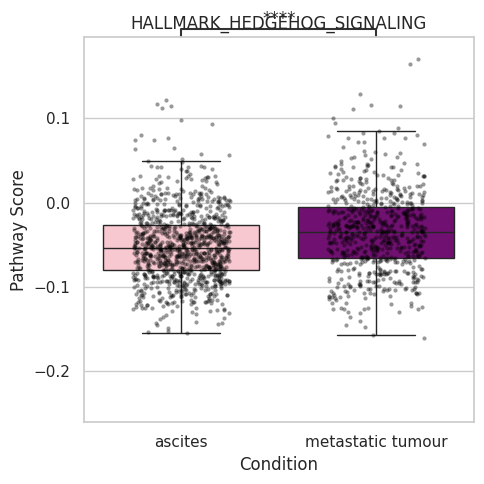

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.263e-02 t=2.497e+00


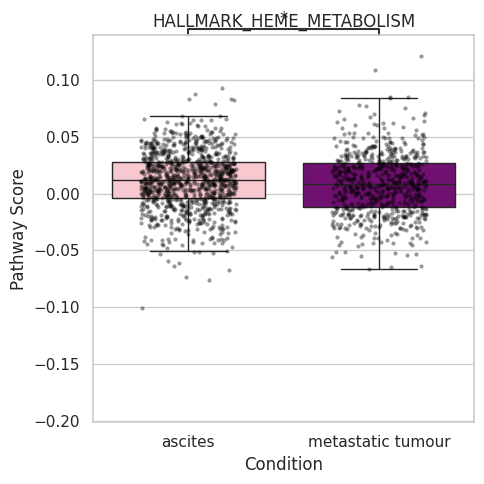

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.069e-142 t=-2.901e+01


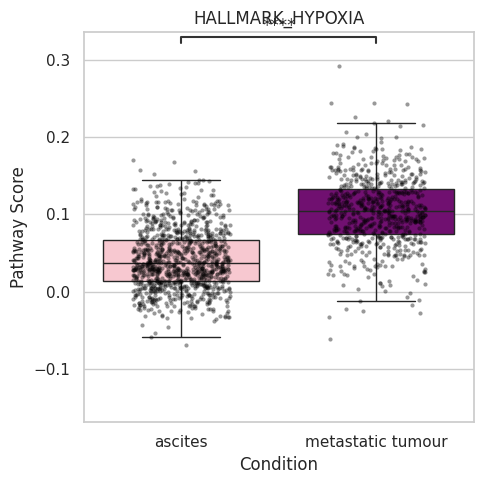

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.278e-72 t=-1.938e+01


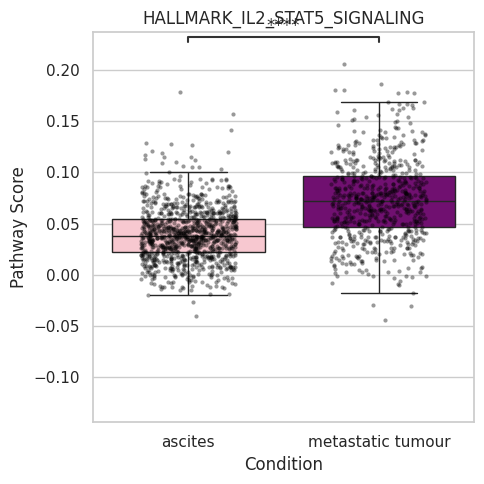

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.371e-29 t=-1.157e+01


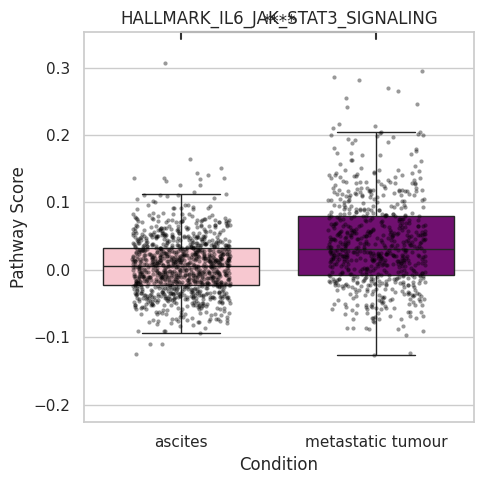

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.791e-75 t=-2.004e+01


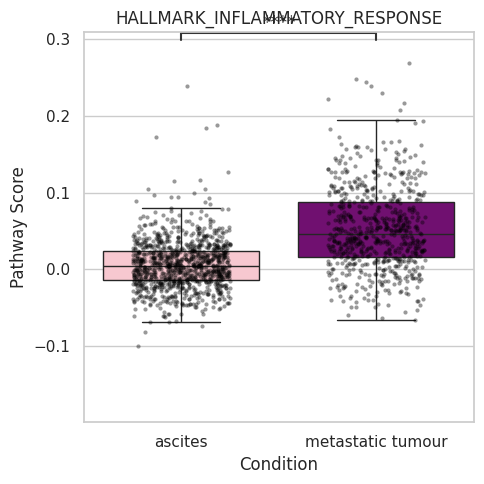

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.957e-01 t=-5.451e-03


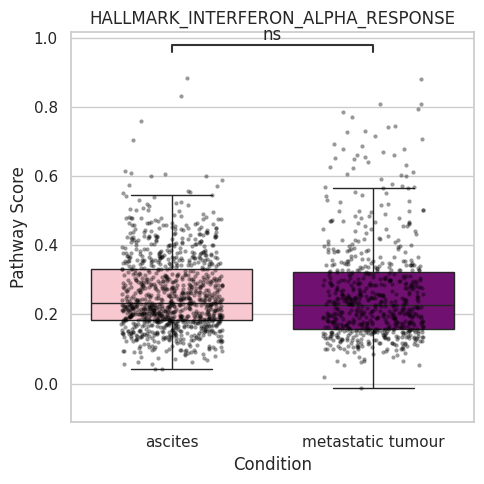

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.281e-09 t=-5.969e+00


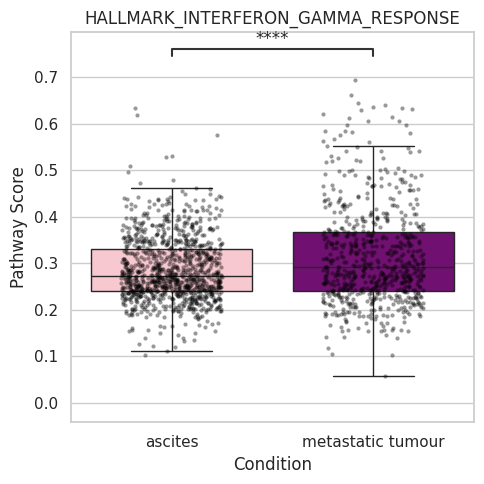

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.476e-40 t=-1.372e+01


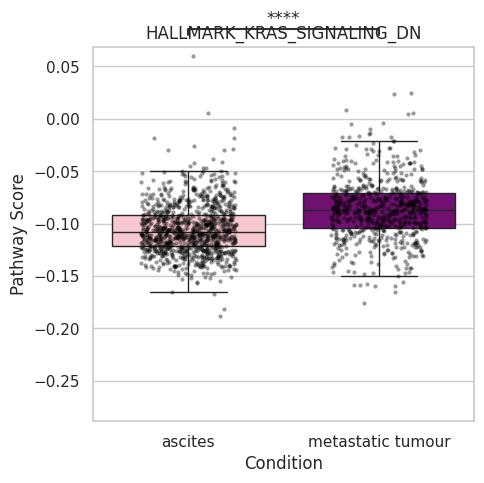

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.905e-24 t=-1.046e+01


/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



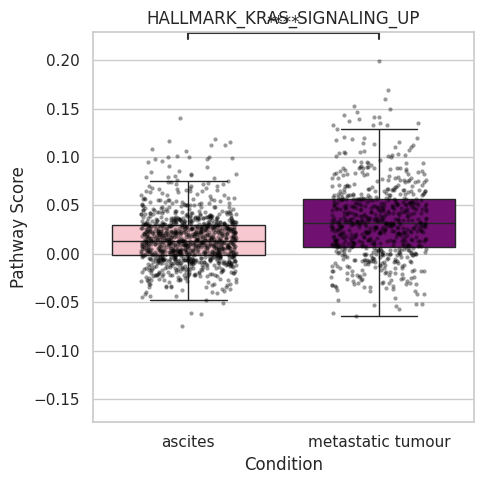

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.860e-20 t=-9.374e+00


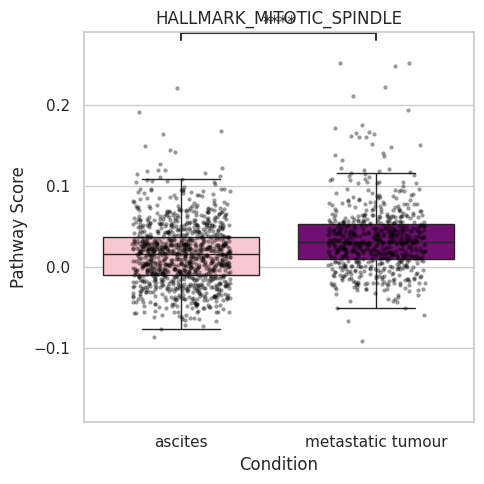

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.436e-81 t=-2.058e+01


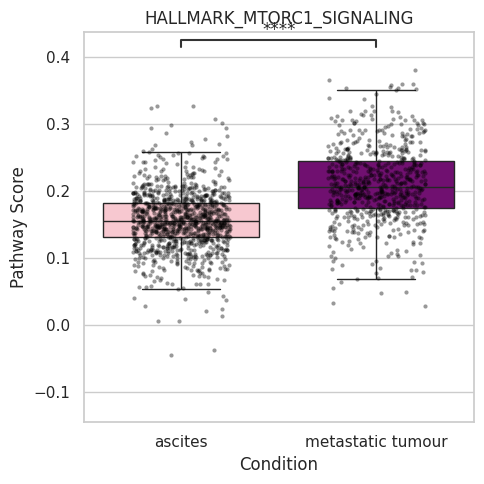

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.834e-16 t=-8.198e+00


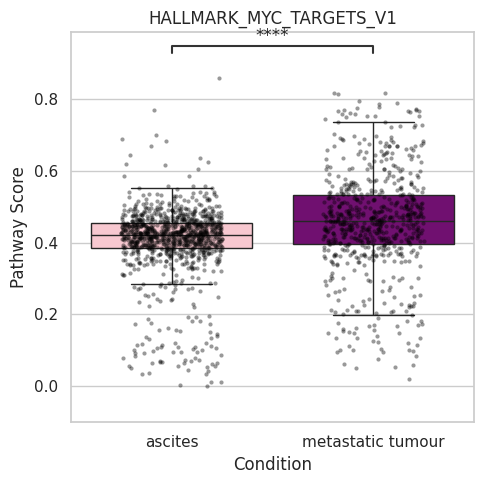

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.976e-54 t=-1.645e+01


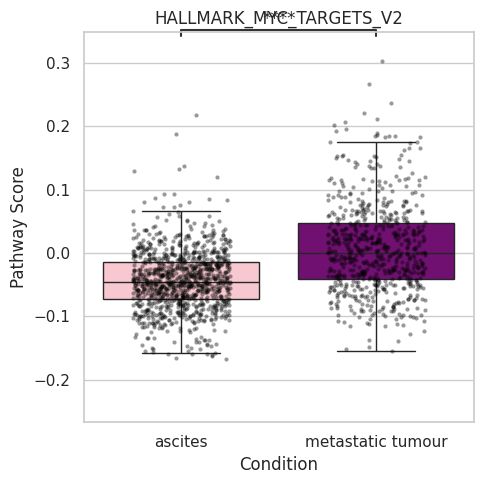

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.071e-02 t=2.316e+00


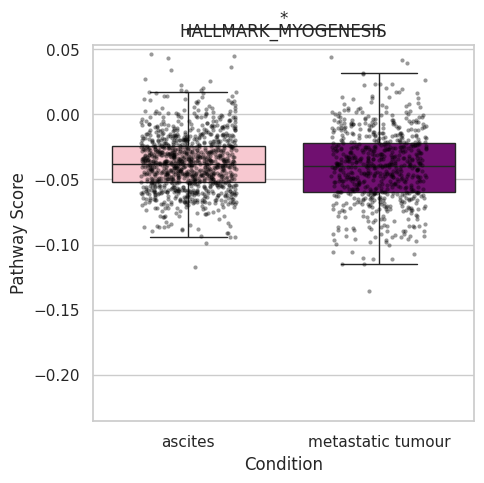

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.687e-01 t=5.701e-01


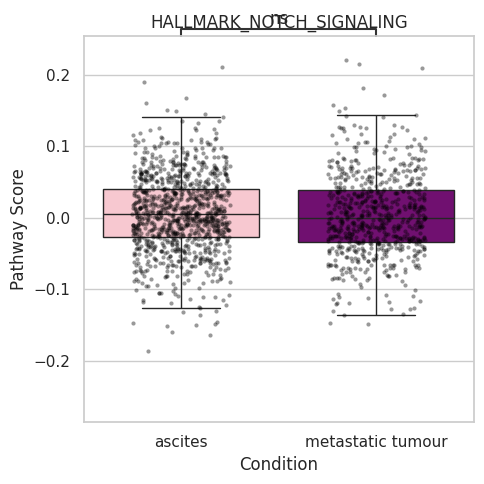

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.926e-03 t=2.619e+00


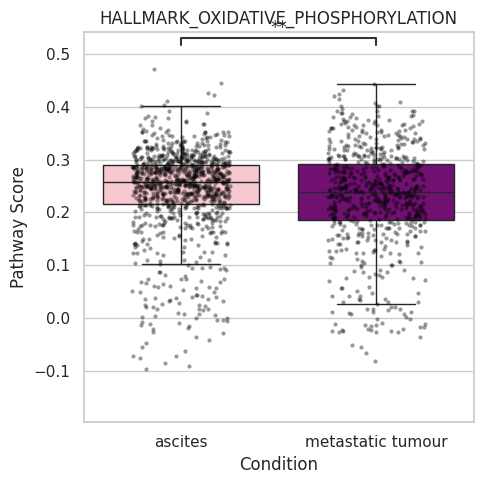

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.741e-77 t=-2.009e+01


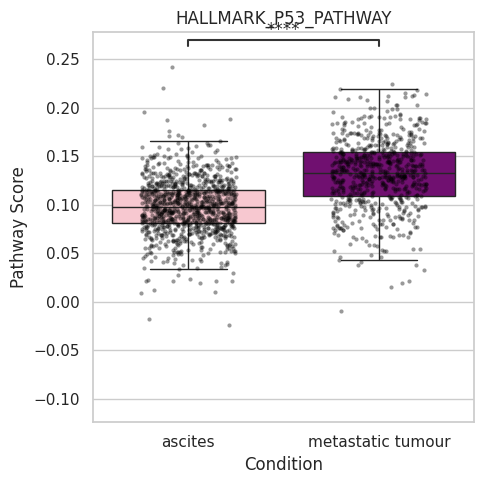

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.702e-11 t=6.604e+00


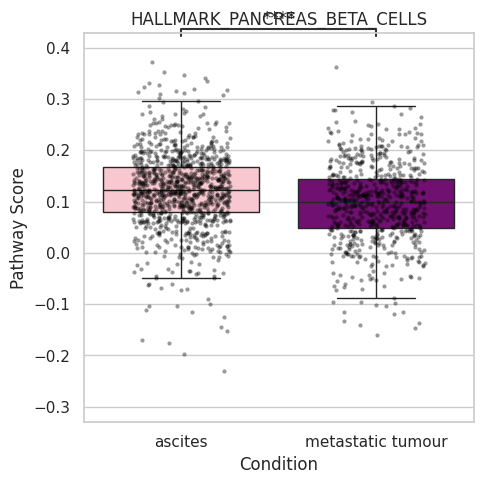

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.192e-12 t=7.087e+00


/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



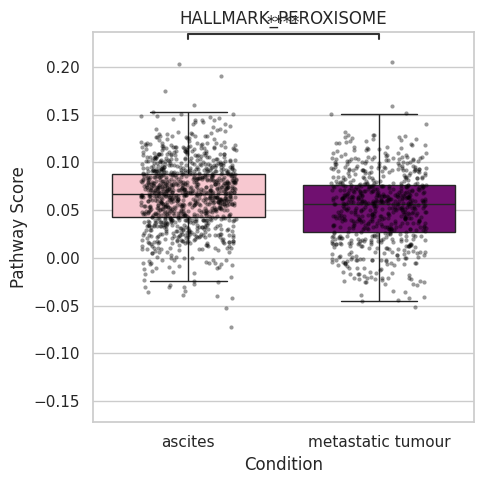

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.348e-11 t=-6.693e+00


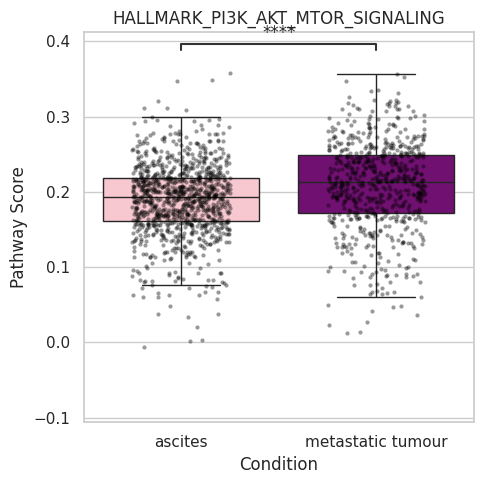

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.483e-06 t=-4.660e+00


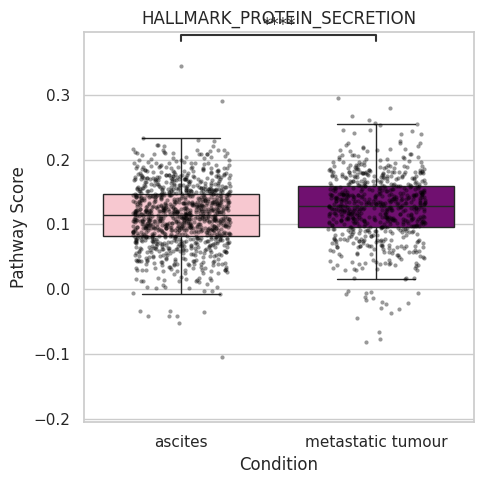

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.944e-04 t=-3.442e+00


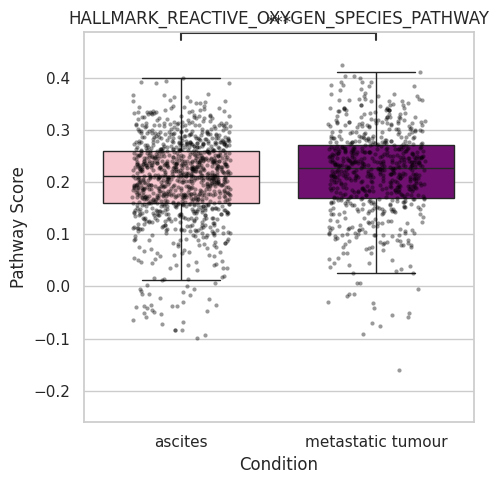

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.361e-08 t=-5.512e+00


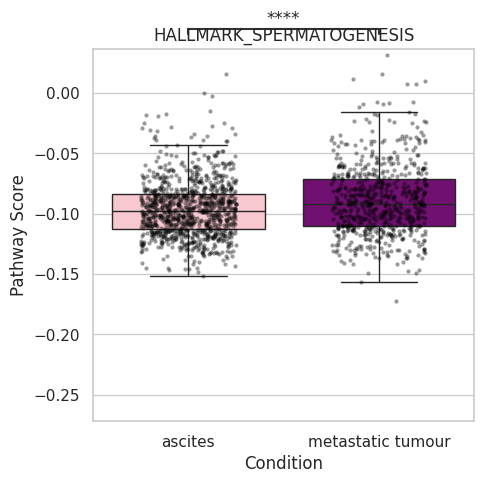

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.955e-36 t=-1.288e+01


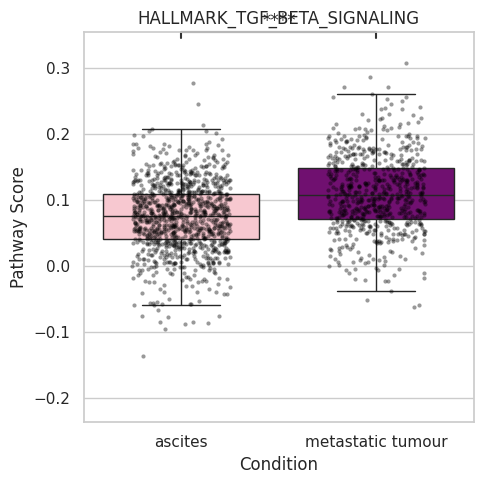

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.065e-197 t=-3.846e+01


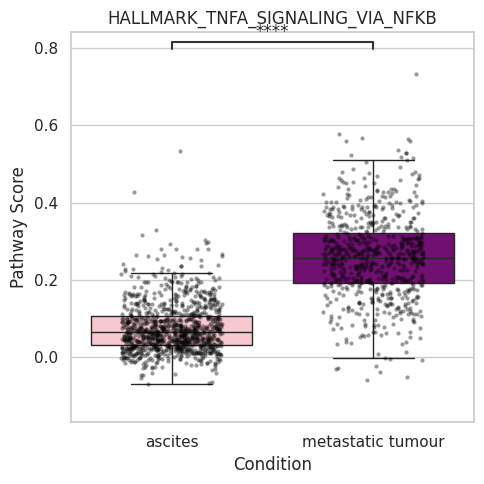

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.388e-69 t=-1.876e+01


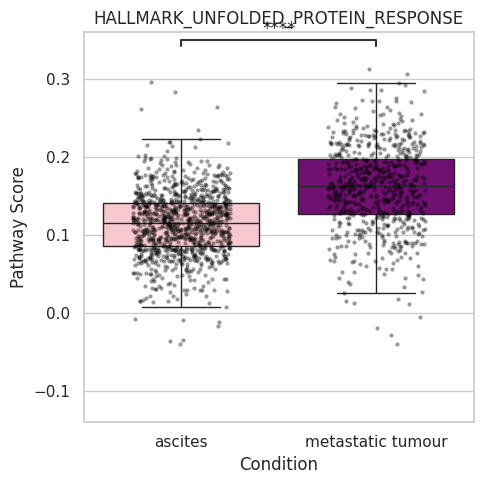

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.188e-16 t=-8.152e+00


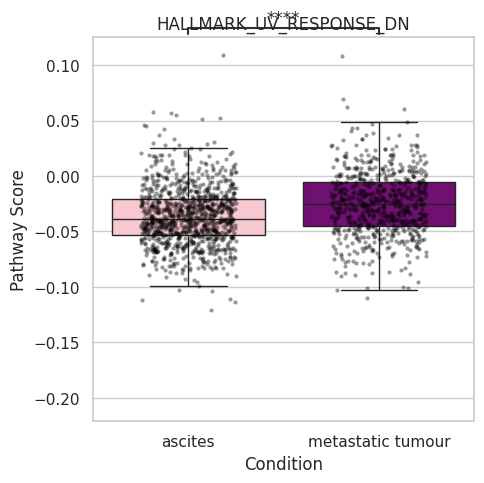

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.365e-132 t=-2.771e+01


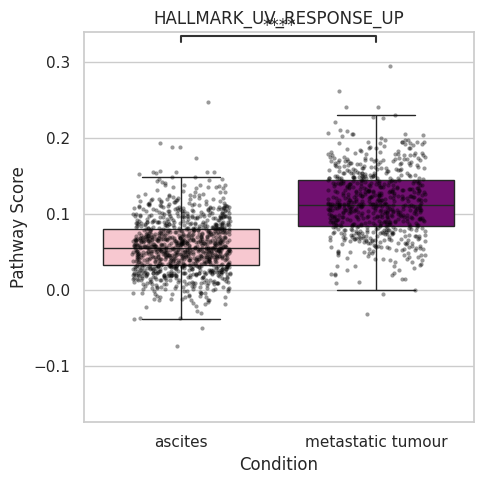

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.055e-02 t=-2.050e+00


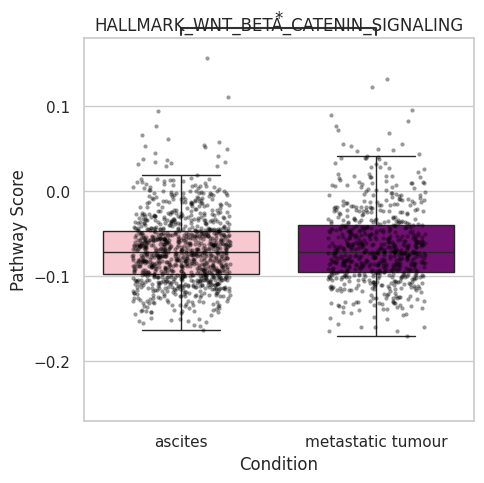

/scratch/temp/25256248/ipykernel_2078942/310605597.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.406e-15 t=7.967e+00


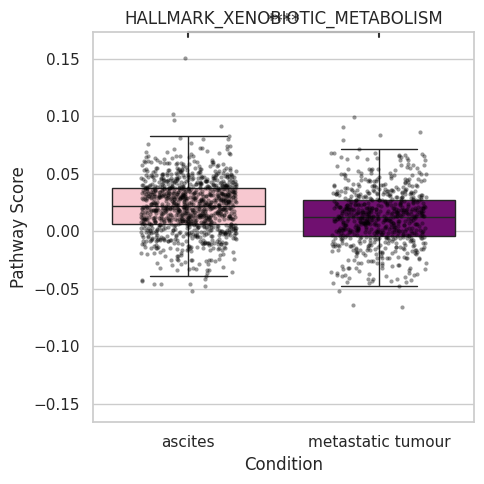

In [83]:
# Use .obs dataframe
obs_df = data_DC1.obs.copy()

# Keep only conditions of interest
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Set plotting style
sns.set(style="whitegrid")

# Consistent colour palette
palette = {
    "ascites": "#FFC0CB",     # pink
    "metastatic tumour": "#800080"   # purple
}

# Comparison pair
pairs = [("ascites", "metastatic tumour")]

# Loop through gene sets
for gene_set in H_sets.keys():

    score_col = f"{gene_set}_score"

    # Skip missing pathways
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col}")
        continue

    # Remove NA values
    plot_df = obs_df[
        ["sample_type_major2", score_col]
    ].dropna()

    # Skip empty groups
    ascites_n = (
        plot_df["sample_type_major2"] == "ascites"
    ).sum()

    metastatic_n = (
        plot_df["sample_type_major2"] == "metastatic tumour"
    ).sum()

    if ascites_n == 0 or metastatic_n == 0:
        continue

    # Create figure
    plt.figure(figsize=(5, 5))

    ax = sns.boxplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        palette=palette,
        showfliers=False #removes boxplot outliers
    )

    sns.stripplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        #palette=palette,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.25     #True
    )

    # Add t-test annotation
    annotator = Annotator(
        ax,
        pairs,
        data=plot_df,
        x="sample_type_major2",
        y=score_col
    )

    annotator.configure(
        test="t-test_welch",
        text_format="star",   # or "simple"
        loc="outside"
    )

    annotator.apply_and_annotate()

     # ---- FIX OVERLAP ISSUE ----
    # Move title slightly higher
    ax.set_title(gene_set, pad=25)

    # Labels
    plt.title(gene_set)
    plt.xlabel("Condition")
    plt.ylabel("Pathway Score")

    # Give extra top margin so stars don't hit title
    plt.ylim(
        plot_df[score_col].min() - 0.1,
        plot_df[score_col].max() * 1.15
    )

    plt.tight_layout()
    plt.show()
     

## Do per sample - generate score for DC2s

### KEGG Pathways

In [84]:
# Create a dictionary to store mean scores per sample
sample_scores = {}

# Iterate through each gene set
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()

    # Score the cells using the gene set
    sc.tl.score_genes(data_DC2, gene_list=gene_set, score_name=f"{set_name}_score")


# Select only numeric columns for aggregation
numeric_columns = [f"{set_name}_score" for set_name in K_sets_sub.keys()]

# Ensure these columns exist in data_DC2.obs
numeric_columns = [col for col in numeric_columns if col in data_DC2.obs.columns]

# Group by 'integration_id' and calculate mean only for numeric columns
sample_scores_df = data_DC2.obs.groupby("integration_id")[numeric_columns].mean()

# Add the sample_type_major2 metadata for each sample
sample_scores_df["sample_type_major2"] = data_DC2.obs.groupby("integration_id")["sample_type_major2"].first()
     

       'PPARGC1A', 'PRKAG3'],
      dtype='object')
       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL5A', 'KIR2DS1', 'KIR2DS3',
       'KIR2DS4', 'KIR2DS5', 'KIR3DL3'],
      dtype='object')
       'AVPR1A', 'AVPR1B', 'BDKRB1', 'CACNA1B', 'CACNA1E', 'CACNA1I',
       'CACNA1S', 'CALML6', 'CAMK2A', 'CCKAR', 'CCKBR', 'CHP2', 'CHRM1',
       'CHRM2', 'CHRM5', 'DRD1', 'DRD5', 'GRM1', 'GRM5', 'GRPR', 'HTR2A',
       'HTR2C', 'HTR4', 'HTR5A', 'HTR6', 'LHCGR', 'MYLK2', 'MYLK3', 'NOS2',
       'P2RX3', 'P2RX6', 'PLCZ1', 'PLN', 'PPP3R2', 'PRKACG', 'PTGFR',
       'SLC25A31', 'TACR3', 'TRHR', 'VDAC2P5'],
      dtype='object')
       'CLDN6', 'CLDN8', 'HLA-DRB3', 'HLA-DRB4', 'NECTIN1', 'NECTIN2',
       'NECTIN3', 'NLGN4X', 'PECAM1'],
      dtype='object')
       'CCL3L3', 'CCR8', 'CXCL8', 'GNG13', 'GRK1', 'GRK2', 'GRK3', 'PF4V1',
       'PPBPP1', 'PRKACG'],
      dtype='object')
       'CCR8', 'CNTFR', 'CXCL8', 'EDAR', 'EPO', 'G

/scratch/temp/25256248/ipykernel_2078942/3438767559.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/scratch/temp/25256248/ipykernel_2078942/3438767559.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


/scratch/temp/25256248/ipykernel_2078942/4103517962.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


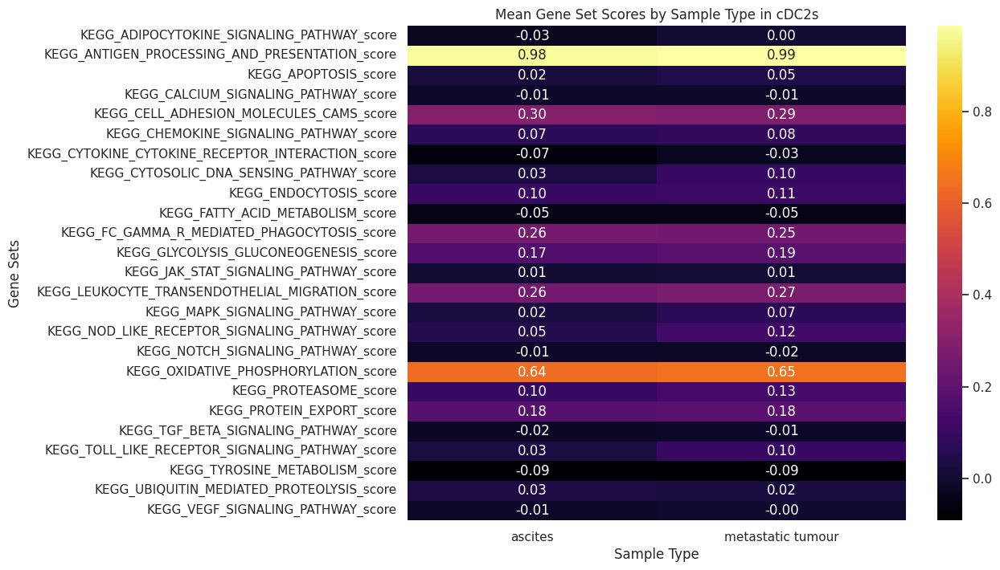

In [86]:
# Group by cancer type and compute the average score for each cancer type 
cancer_type_scores_df = sample_scores_df.groupby("sample_type_major2").mean()

# plot the scores
plt.figure(figsize=(10, 8))
sns.heatmap(cancer_type_scores_df.T, cmap="inferno", annot=True, fmt=".2f")
plt.xlabel("Sample Type")
plt.ylabel("Gene Sets")
plt.title("Mean Gene Set Scores by Sample Type in cDC2s")
plt.show()

In [87]:
# Store results
comparison_results = []

# Use .obs dataframe from AnnData
obs_df = data_DC2.obs.copy()

# Keep only ascites and metastatic
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Loop through gene sets
for gene_set in K_sets_sub.keys():

    # Column name of pathway score
    score_col = f"{gene_set}_score"

    # Skip if pathway not present
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col} (not found)")
        continue

    # Split groups
    ascites_scores = obs_df.loc[
        obs_df["sample_type_major2"] == "ascites",
        score_col
    ]

    metastatic_scores = obs_df.loc[
        obs_df["sample_type_major2"] == "metastatic tumour",
        score_col
    ]

    # Skip empty groups
    if len(ascites_scores) == 0 or len(metastatic_scores) == 0:
        continue

    # Welch t-test
    stat, p_value = ttest_ind(
        ascites_scores,
        metastatic_scores,
        equal_var=False
    )

    # Means
    mean_ascites = ascites_scores.mean()
    mean_metastatic = metastatic_scores.mean()

    comparison_results.append({
        "Gene Set": gene_set,
        "Ascites Mean": mean_ascites,
        "Metastatic Mean": mean_metastatic,
        "Difference": mean_metastatic - mean_ascites,
        "P-value": p_value
    })

# Convert to dataframe
comparison_results_df = pd.DataFrame(comparison_results)

# FDR correction
comparison_results_df["FDR"] = multipletests(
    comparison_results_df["P-value"],
    method="fdr_bh"
)[1]

# Sort significant pathways first
comparison_results_df = comparison_results_df.sort_values("FDR")

comparison_results_df.head()

,Gene Set,Ascites Mean,Metastatic Mean,Difference,P-value,FDR
14,KEGG_MAPK_SIGNALING_PATHWAY,0.025570,0.068601,0.043031,4.128888e-259,1.032222e-257
15,KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY,0.044107,0.121405,0.077298,2.590362e-212,3.237952e-211
21,KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY,0.029551,0.093555,0.064004,4.865674e-170,4.054728e-169
6,KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,-0.067451,-0.029525,0.037926,1.010322e-153,6.314516e-153
7,KEGG_CYTOSOLIC_DNA_SENSING_PATHWAY,0.029382,0.096333,0.066951,3.446502e-109,1.723251e-108


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.812e-70 t=-1.816e+01


/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



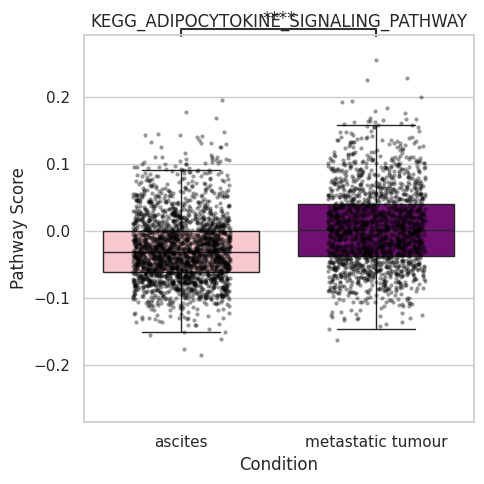

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.301e-01 t=4.816e-01


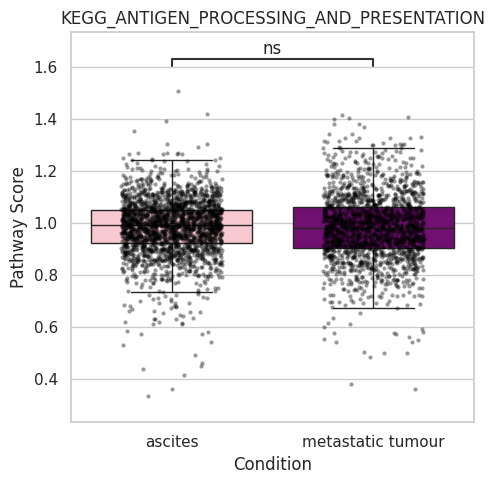

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.157e-28 t=-1.121e+01


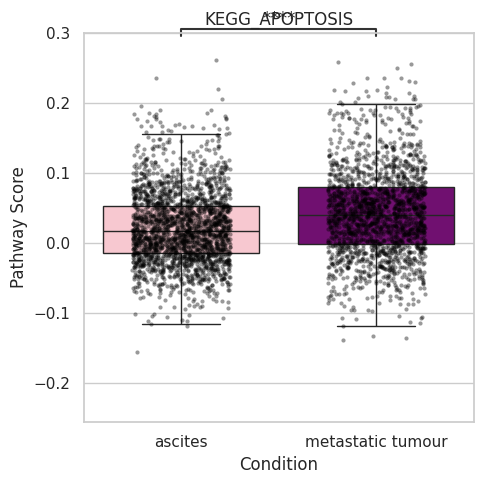

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.458e-01 t=-1.945e-01


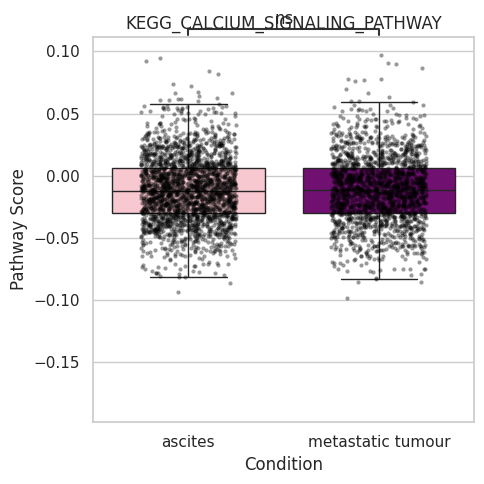

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.904e-11 t=6.596e+00


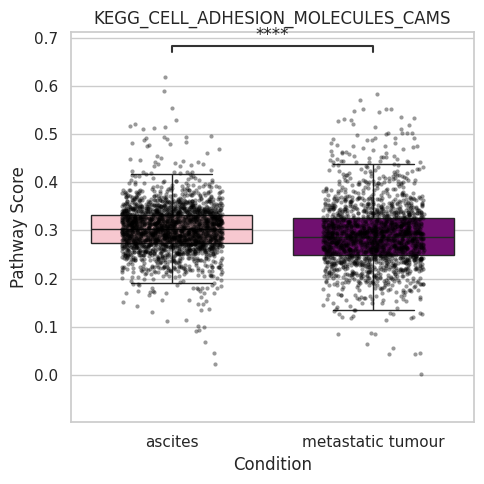

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.028e-08 t=-5.622e+00


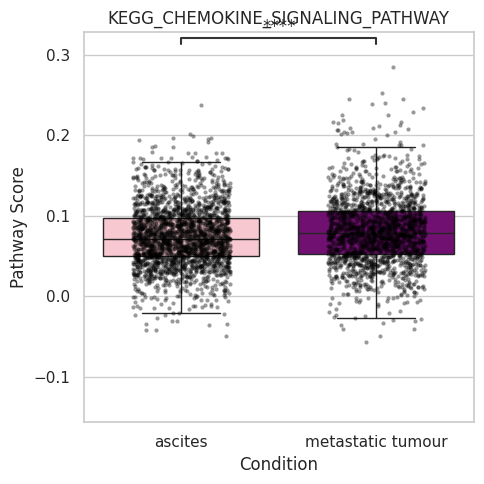

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.010e-153 t=-2.824e+01


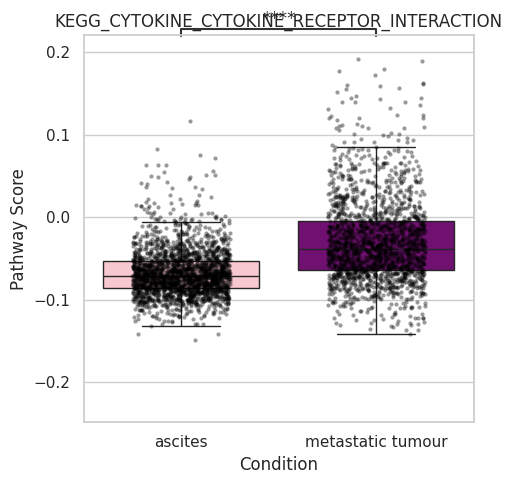

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.447e-109 t=-2.329e+01


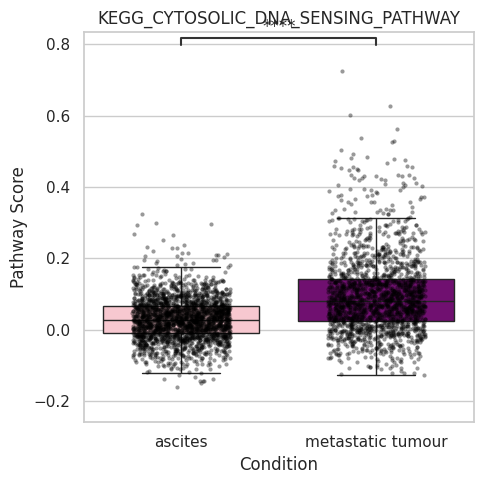

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.659e-19 t=-8.928e+00


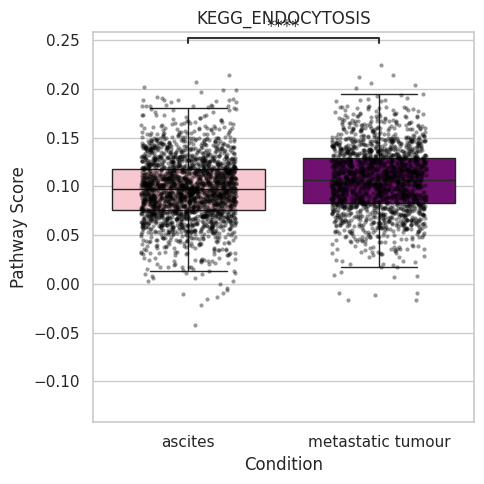

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.688e-01 t=-1.376e+00


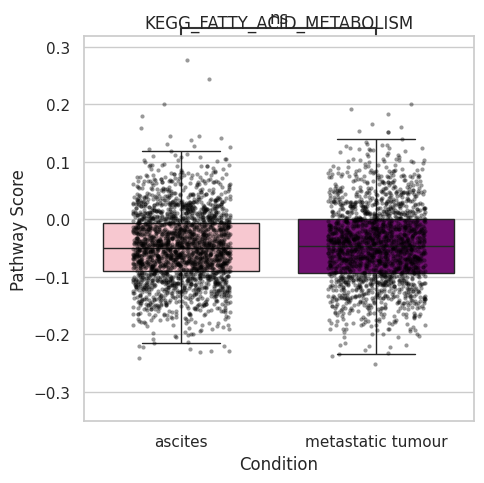

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.630e-12 t=7.087e+00


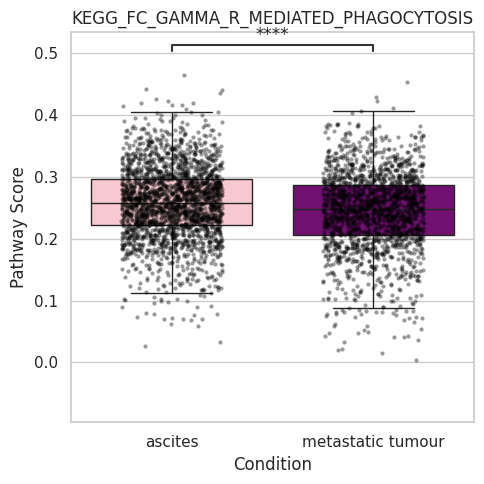

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.303e-04 t=-3.830e+00


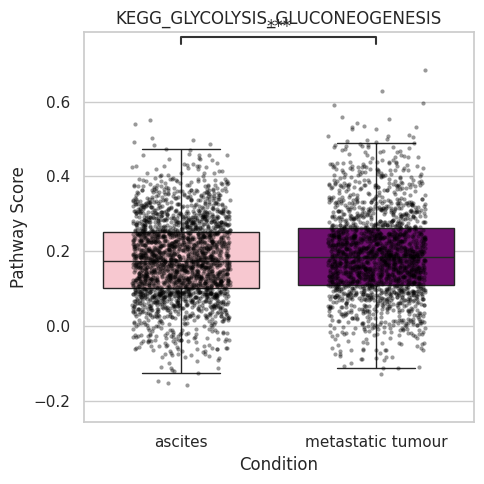

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.614e-01 t=-1.123e+00


/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



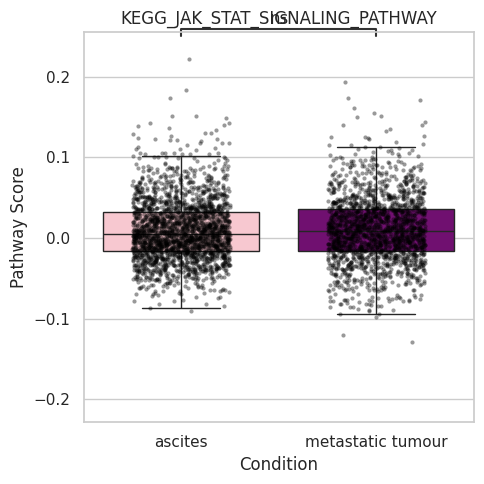

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.203e-14 t=-7.747e+00


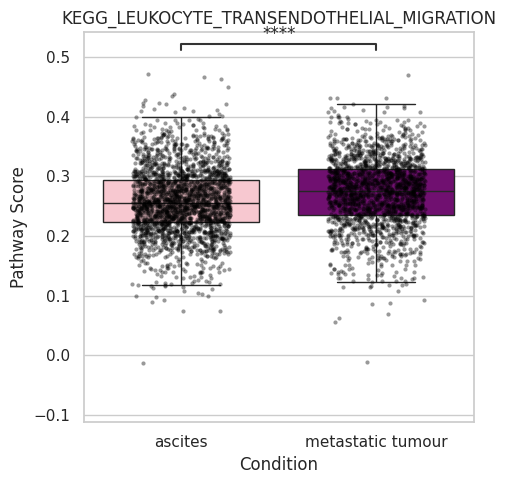

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.129e-259 t=-3.737e+01


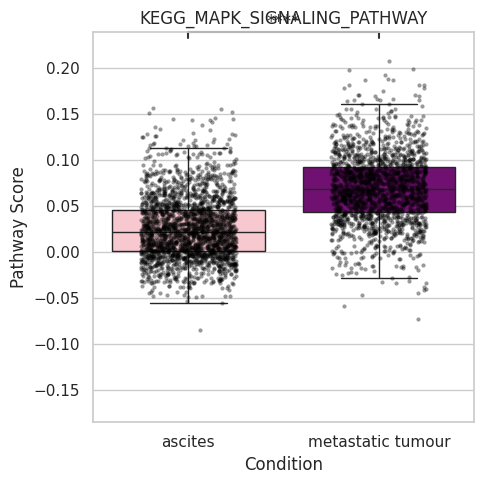

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.590e-212 t=-3.376e+01


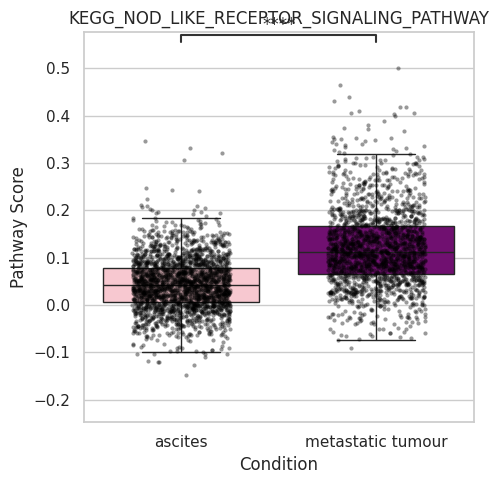

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.764e-05 t=4.298e+00


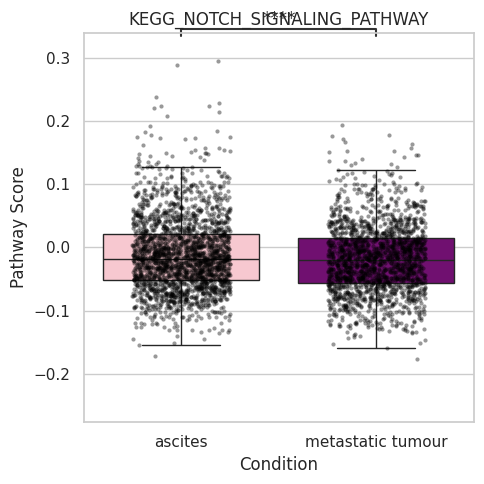

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.251e-08 t=-5.422e+00


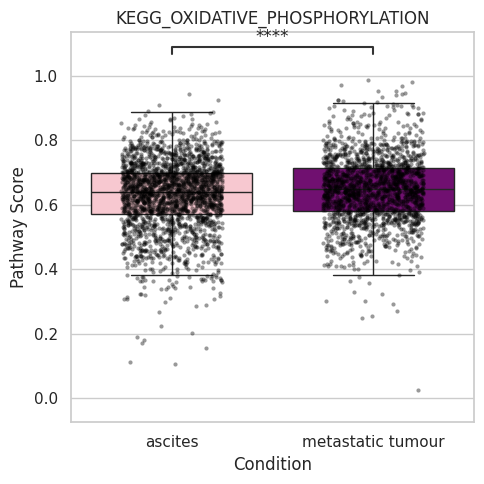

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.289e-09 t=-5.798e+00


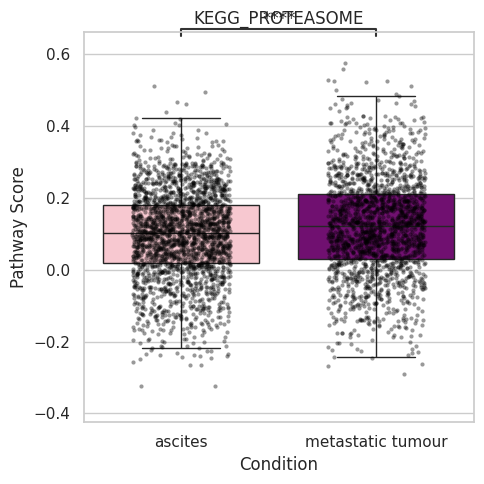

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.632e-03 t=-2.770e+00


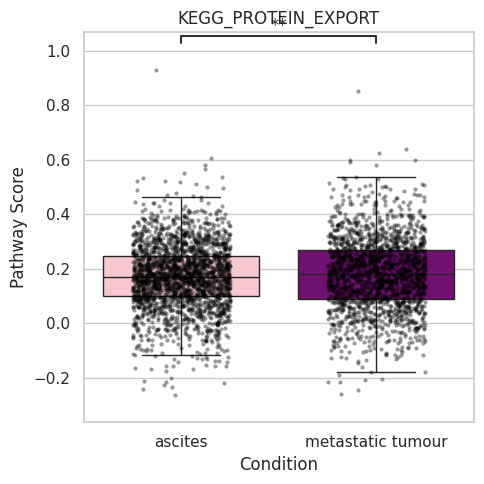

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.087e-12 t=-6.998e+00


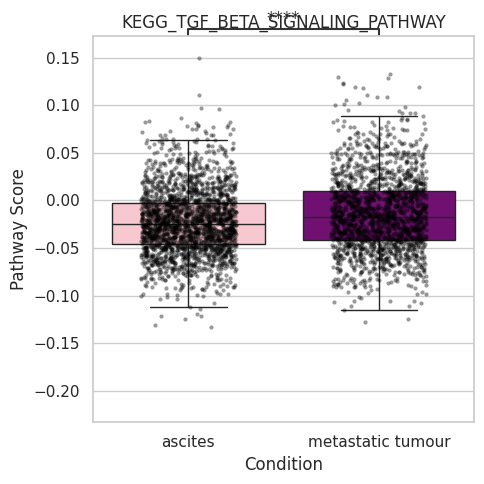

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.866e-170 t=-2.982e+01


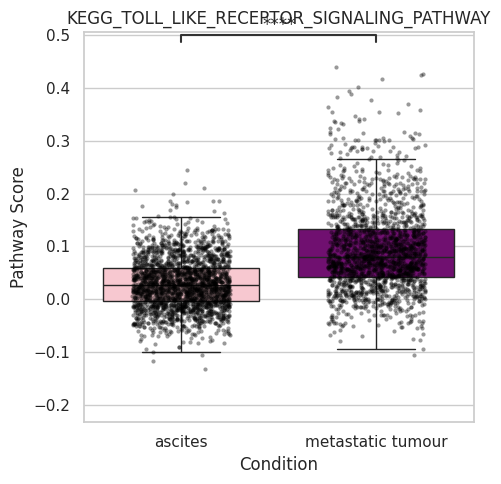

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.280e-01 t=4.846e-01


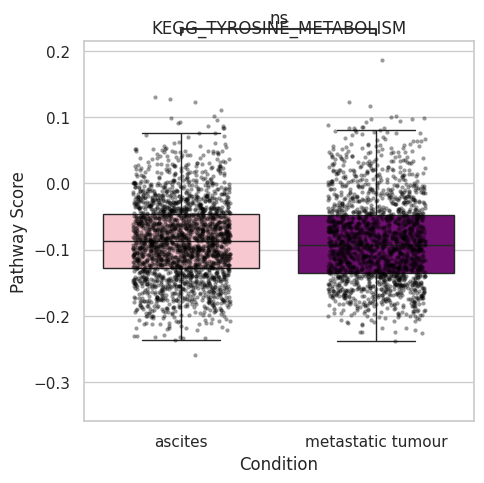

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.345e-21 t=9.607e+00


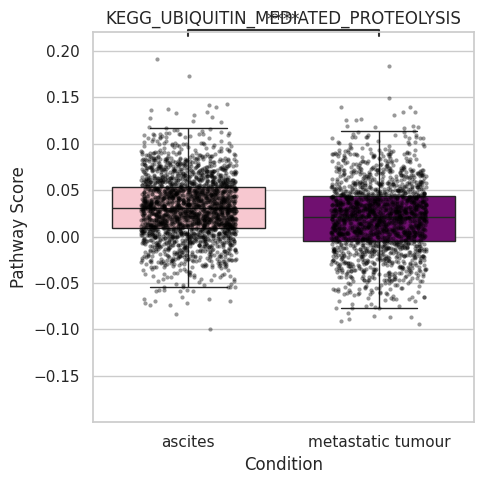

/scratch/temp/25256248/ipykernel_2078942/1682521969.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.643e-13 t=-7.294e+00


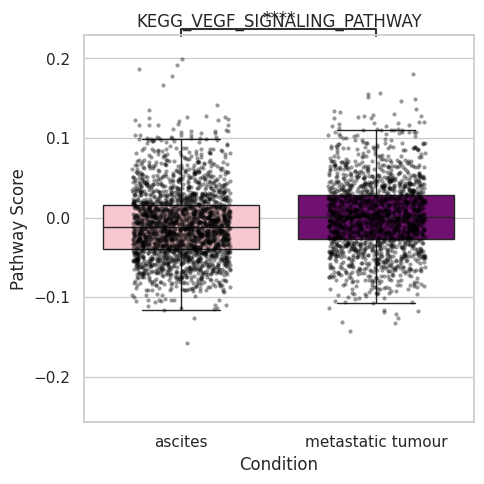

In [88]:
# Use .obs dataframe
obs_df = data_DC2.obs.copy()

# Keep only conditions of interest
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Set plotting style
sns.set(style="whitegrid")

# Consistent colour palette
palette = {
    "ascites": "#FFC0CB",     # pink
    "metastatic tumour": "#800080"   # purple
}

# Comparison pair
pairs = [("ascites", "metastatic tumour")]

# Loop through gene sets
for gene_set in K_sets_sub.keys():

    score_col = f"{gene_set}_score"

    # Skip missing pathways
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col}")
        continue

    # Remove NA values
    plot_df = obs_df[
        ["sample_type_major2", score_col]
    ].dropna()

    # Skip empty groups
    ascites_n = (
        plot_df["sample_type_major2"] == "ascites"
    ).sum()

    metastatic_n = (
        plot_df["sample_type_major2"] == "metastatic tumour"
    ).sum()

    if ascites_n == 0 or metastatic_n == 0:
        continue

    # Create figure
    plt.figure(figsize=(5, 5))

    ax = sns.boxplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        palette=palette,
        showfliers=False #removes boxplot outliers
    )

    sns.stripplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        #palette=palette,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.25     #True
    )

    # Add t-test annotation
    annotator = Annotator(
        ax,
        pairs,
        data=plot_df,
        x="sample_type_major2",
        y=score_col
    )

    annotator.configure(
        test="t-test_welch",
        text_format="star",   # or "simple"
        loc="outside"
    )

    annotator.apply_and_annotate()

     # ---- FIX OVERLAP ISSUE ----
    # Move title slightly higher
    ax.set_title(gene_set, pad=25)

    # Labels
    plt.title(gene_set)
    plt.xlabel("Condition")
    plt.ylabel("Pathway Score")

    # Give extra top margin so stars don't hit title
    plt.ylim(
        plot_df[score_col].min() - 0.1,
        plot_df[score_col].max() * 1.15
    )

    plt.tight_layout()
    plt.show()
     

### Hallmark Pathways

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.389e-19 t=-8.975e+00


/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



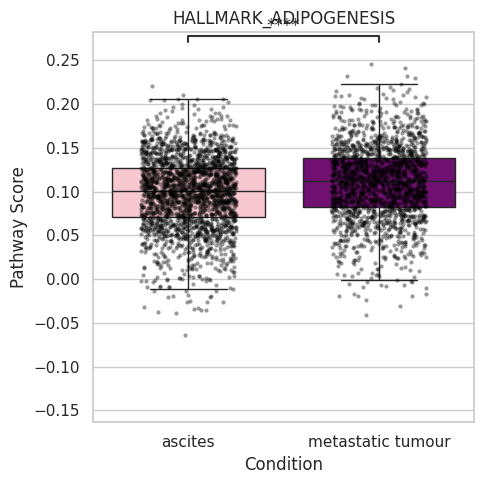

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.616e-04 t=-3.777e+00


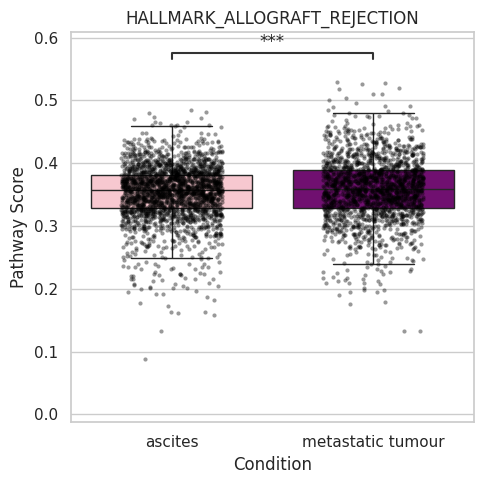

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.869e-269 t=-3.857e+01


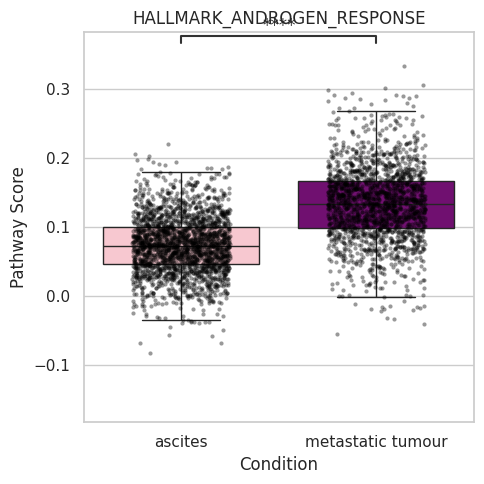

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.978e-110 t=-2.335e+01


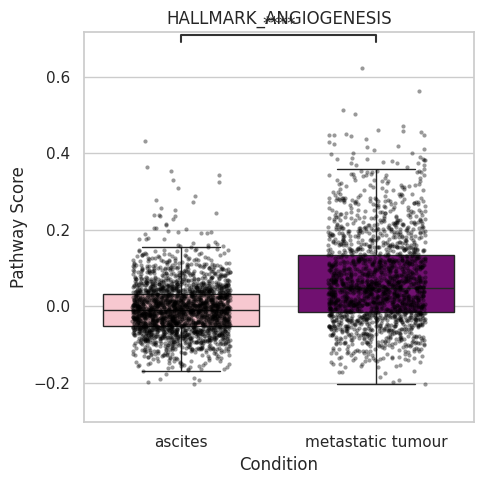

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.448e-03 t=-2.927e+00


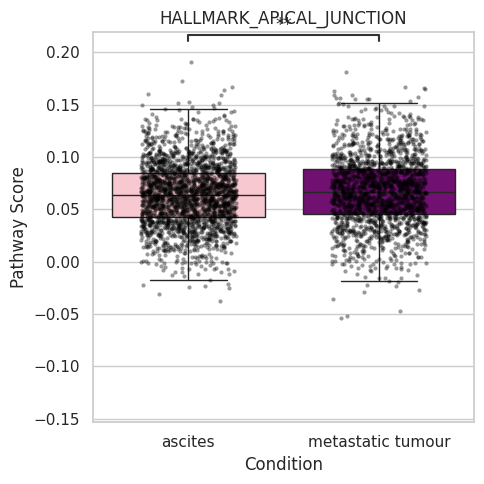

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.689e-02 t=-2.088e+00


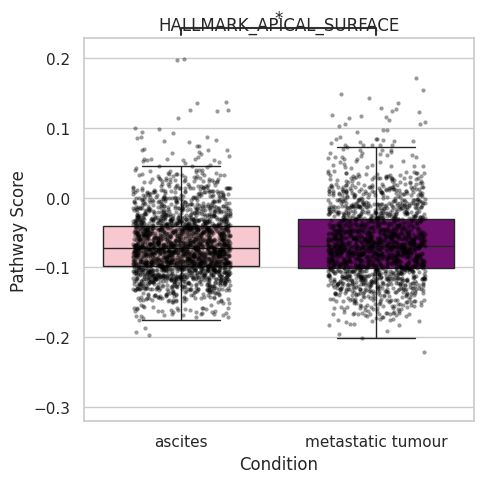

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.940e-228 t=-3.546e+01


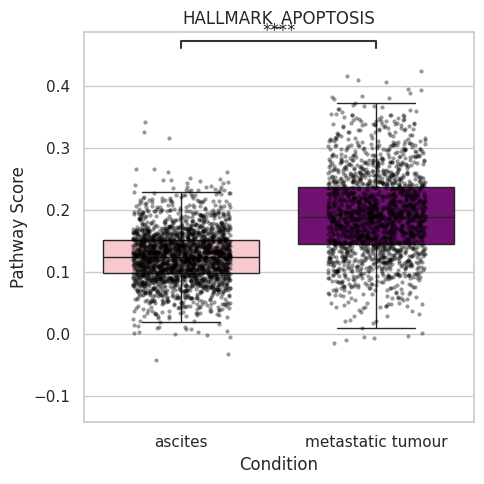

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.805e-02 t=-1.978e+00


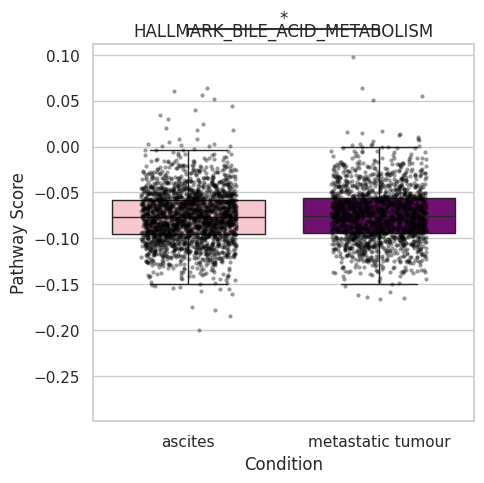

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.364e-127 t=-2.504e+01


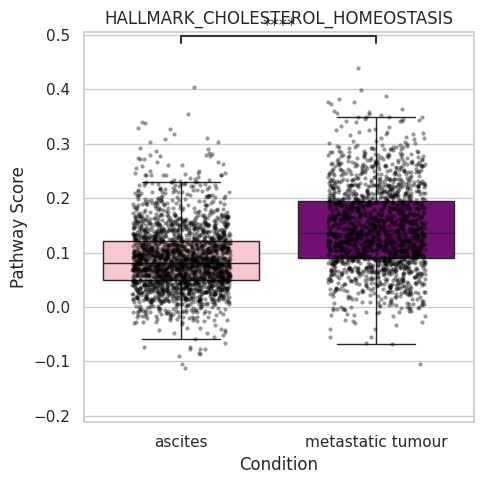

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.060e-77 t=-1.913e+01


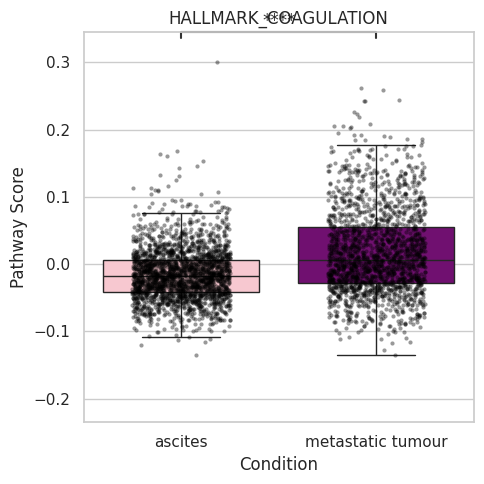

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.236e-50 t=-1.519e+01


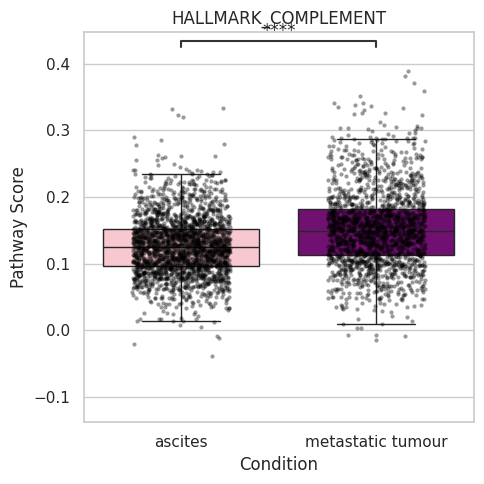

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.824e-05 t=4.123e+00


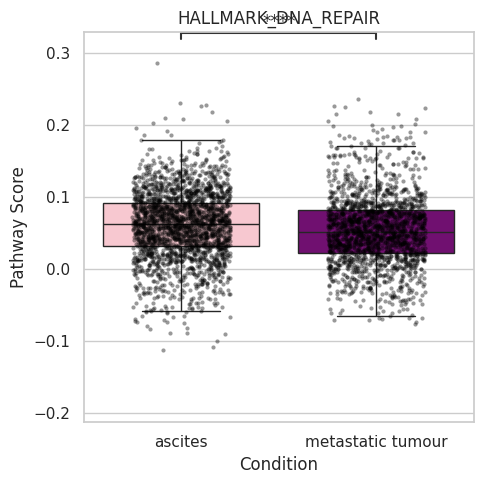

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.849e-22 t=-9.846e+00


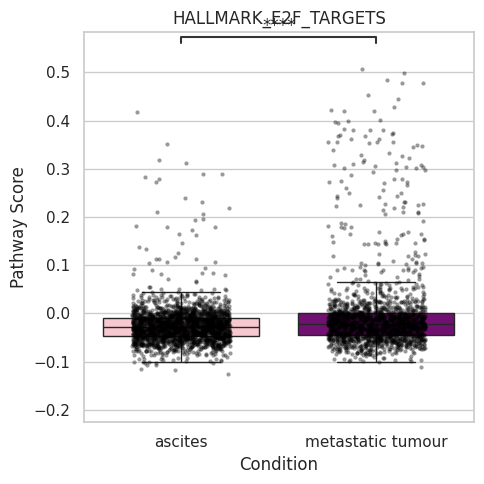

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:0.000e+00 t=-4.705e+01


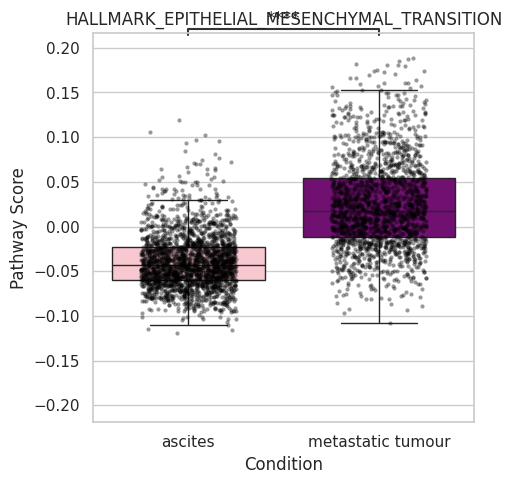

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:0.000e+00 t=-4.405e+01


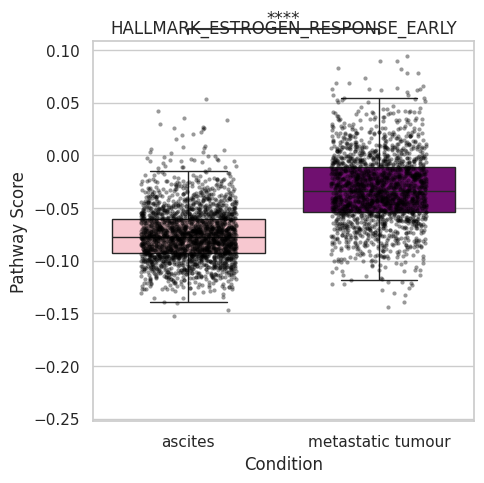

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:0.000e+00 t=-5.527e+01


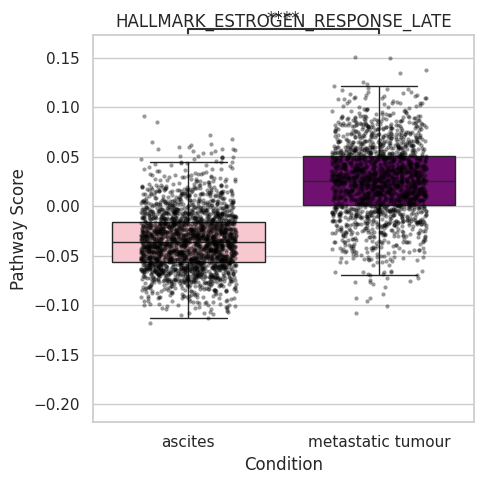

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.945e-20 t=-9.217e+00


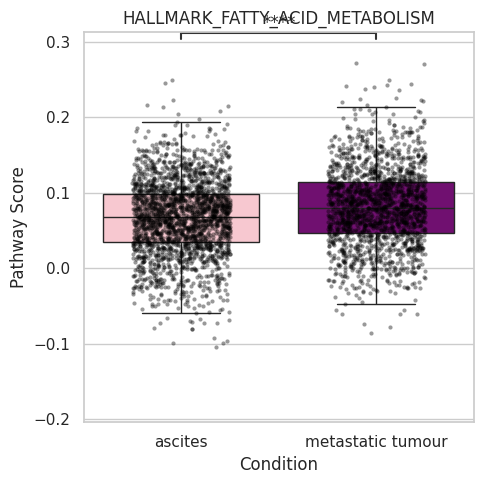

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.693e-66 t=-1.760e+01


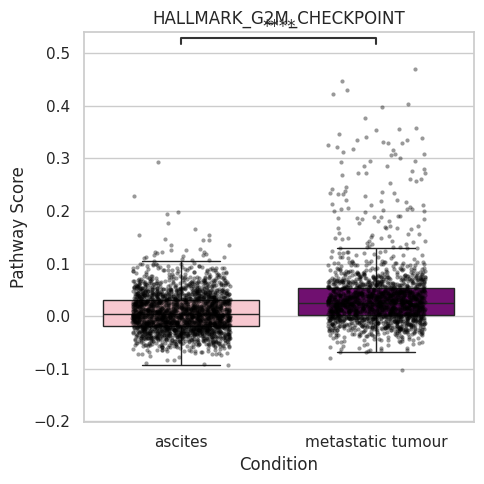

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.195e-116 t=-2.382e+01


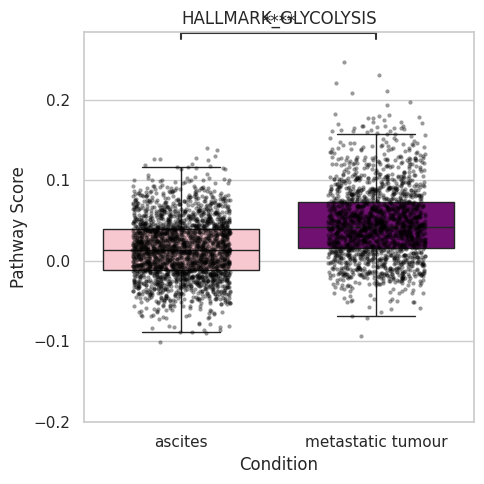

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.171e-56 t=-1.608e+01


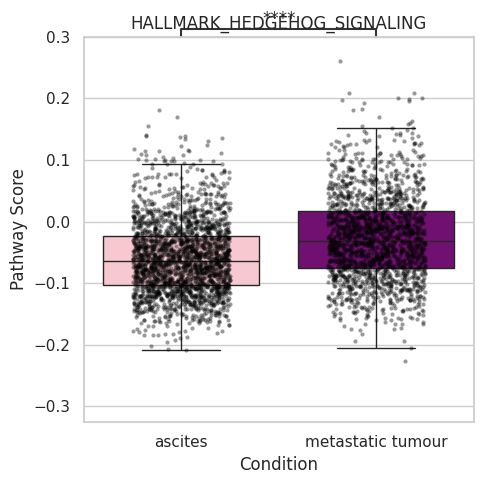

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.442e-05 t=-4.147e+00


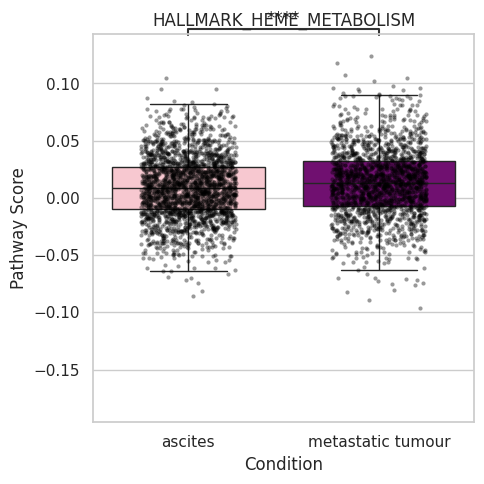

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:0.000e+00 t=-4.874e+01


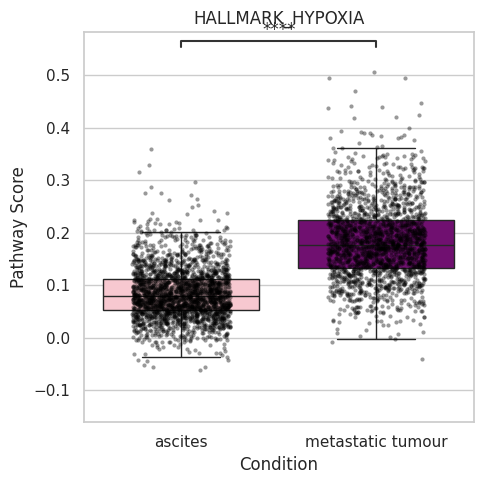

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.445e-233 t=-3.591e+01


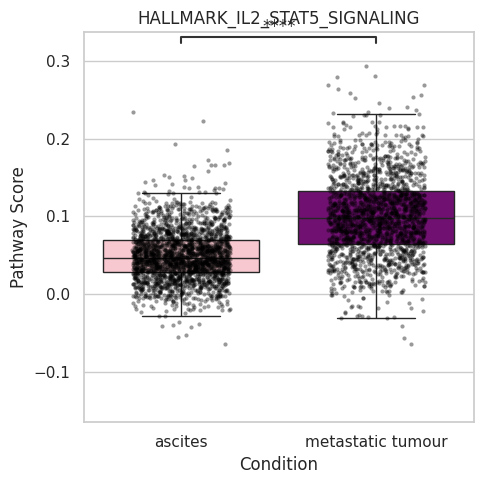

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.214e-32 t=-1.203e+01


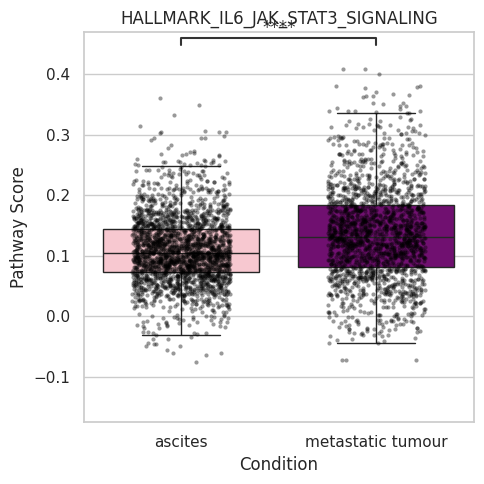

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.181e-235 t=-3.664e+01


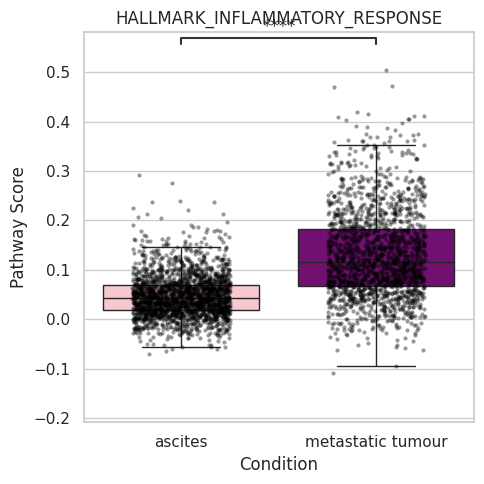

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.296e-157 t=2.801e+01


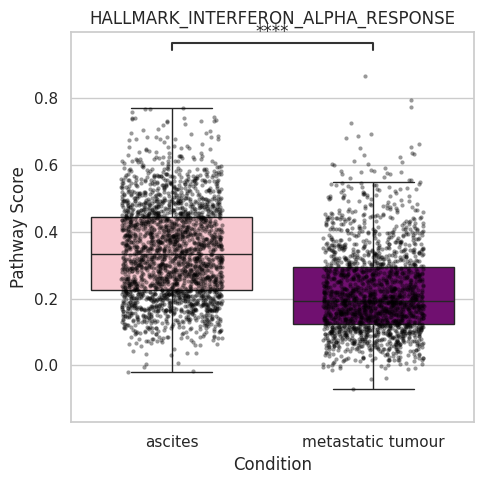

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.554e-20 t=9.347e+00


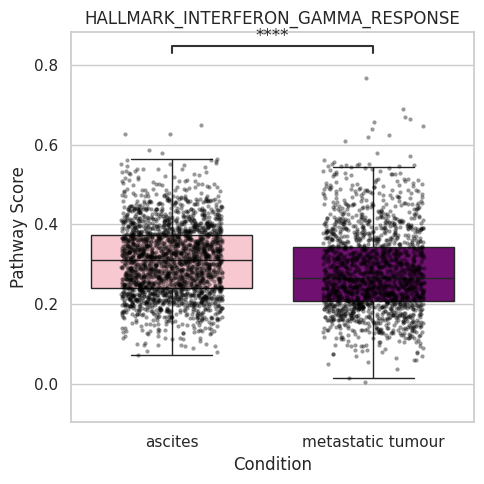

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.481e-188 t=-3.108e+01


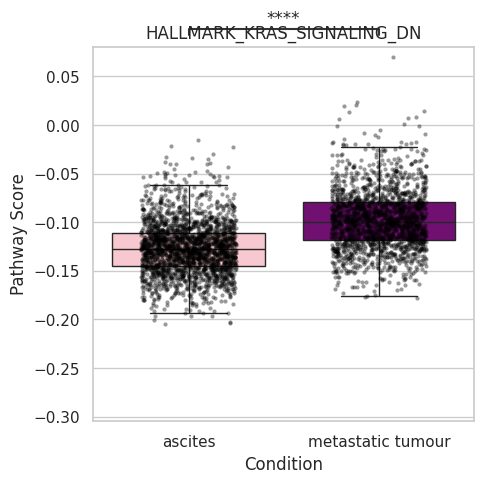

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.100e-305 t=-4.305e+01


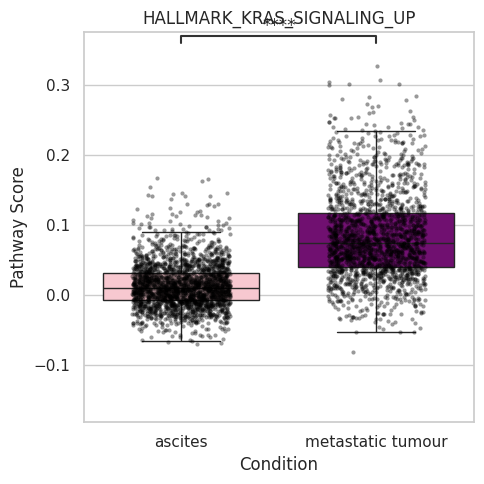

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.080e-05 t=-3.946e+00


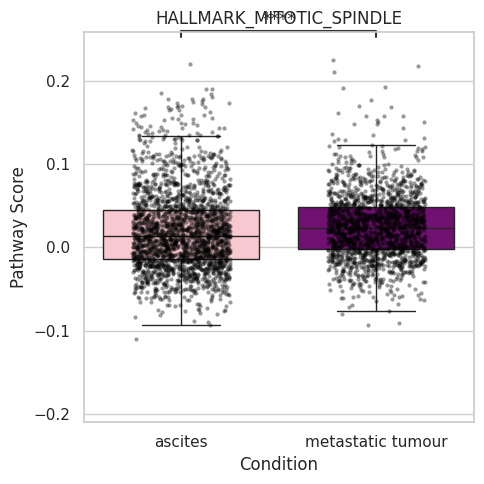

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.202e-151 t=-2.759e+01


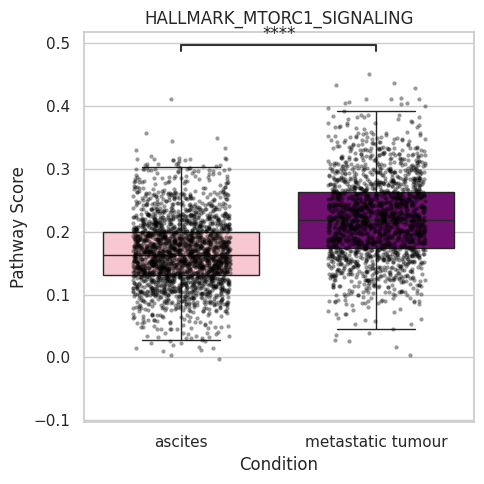

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.886e-08 t=-5.562e+00


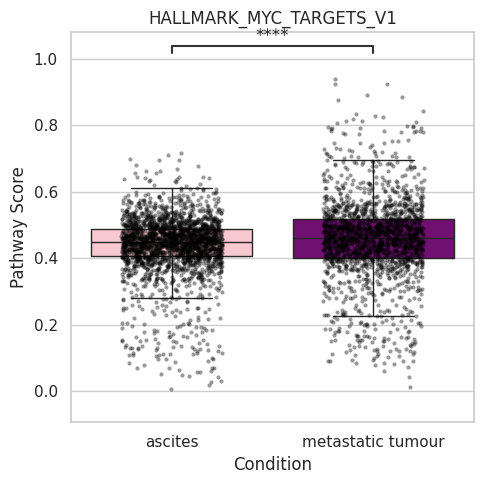

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.280e-58 t=-1.647e+01


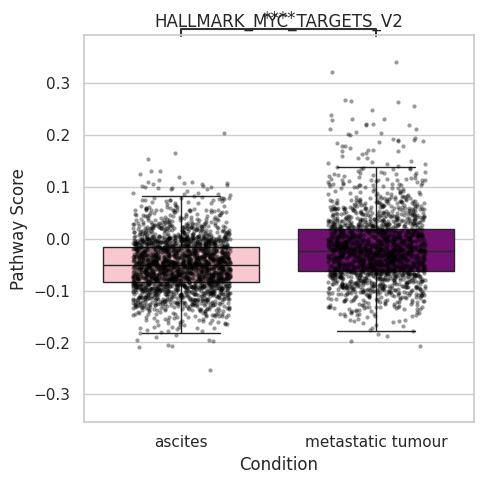

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.159e-30 t=-1.149e+01


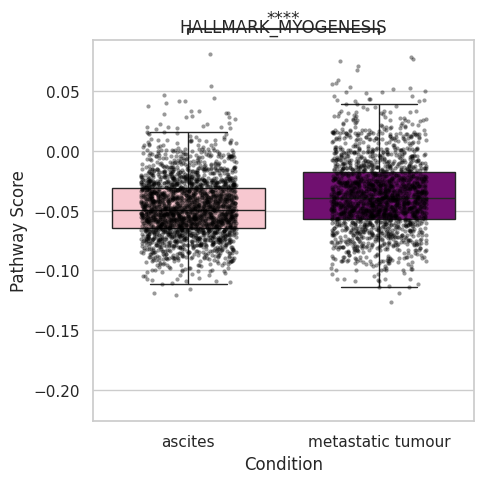

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.998e-01 t=1.282e+00


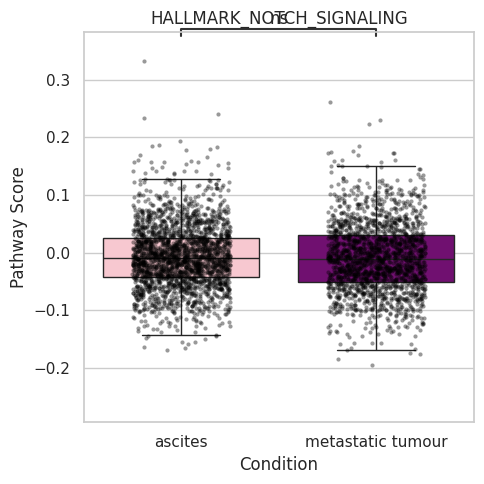

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.204e-09 t=5.757e+00


/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



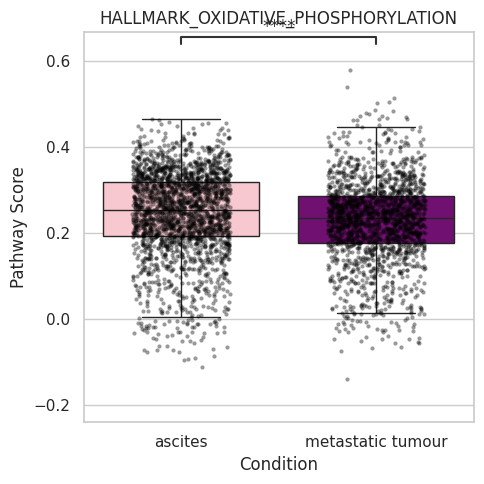

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.126e-181 t=-3.044e+01


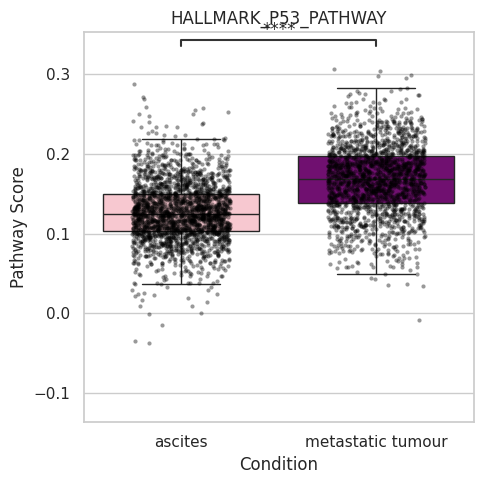

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.020e-10 t=-6.206e+00


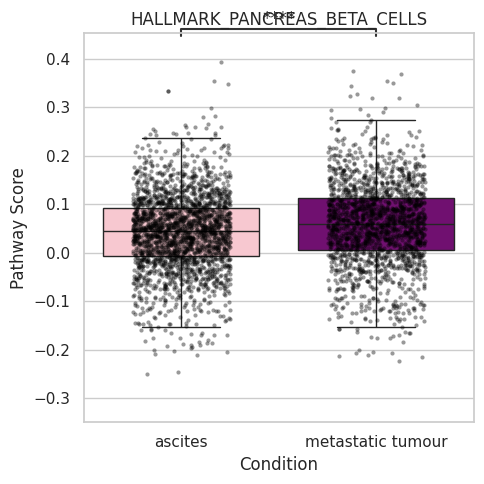

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.213e-01 t=-1.550e+00


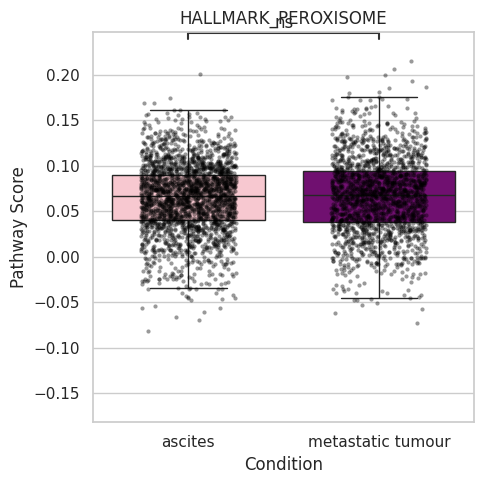

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.002e-01 t=-1.281e+00


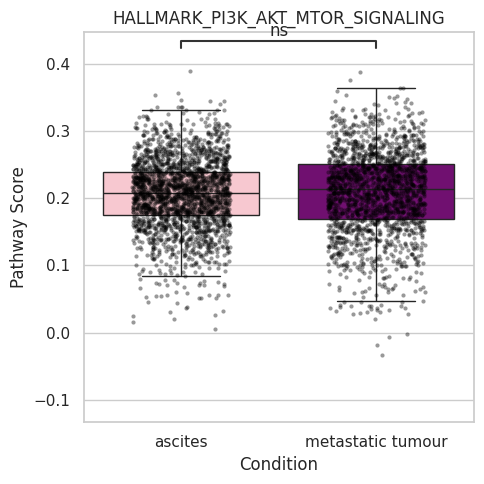

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.265e-01 t=-1.528e+00


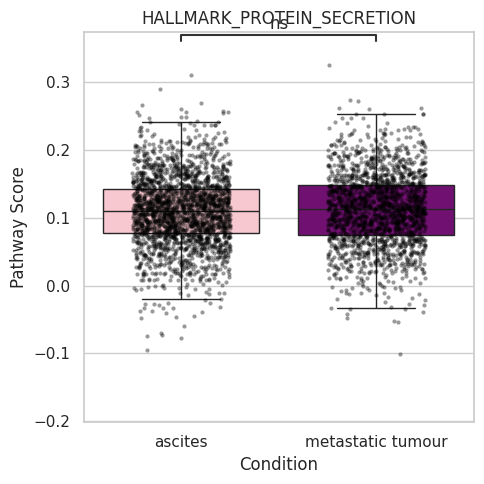

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.011e-04 t=-3.892e+00


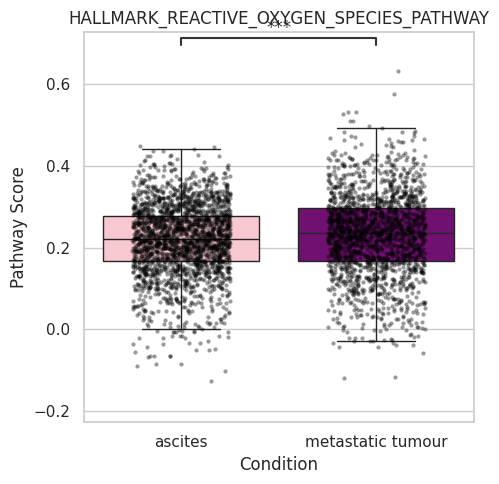

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.845e-09 t=-5.786e+00


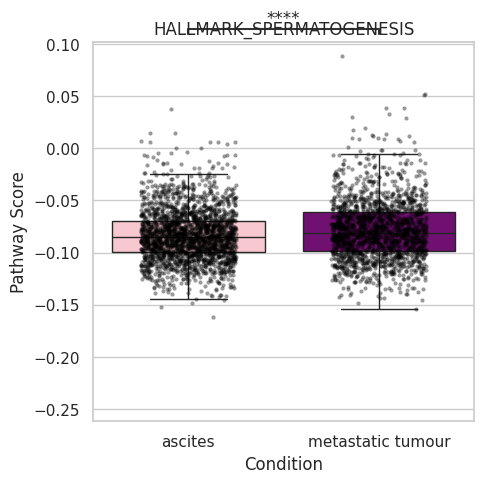

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.265e-80 t=-1.949e+01


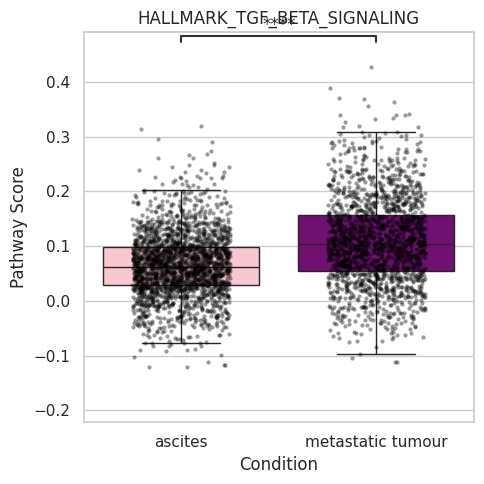

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:0.000e+00 t=-6.299e+01


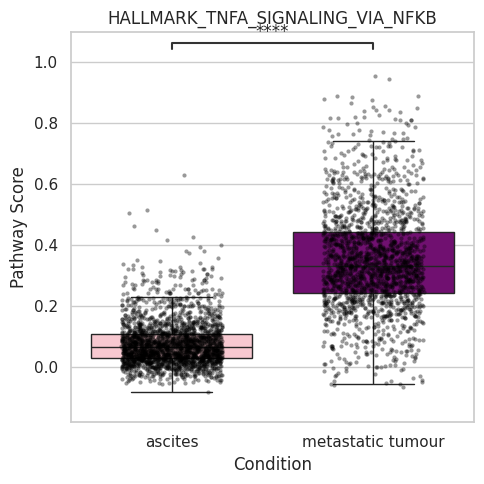

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.320e-86 t=-2.031e+01


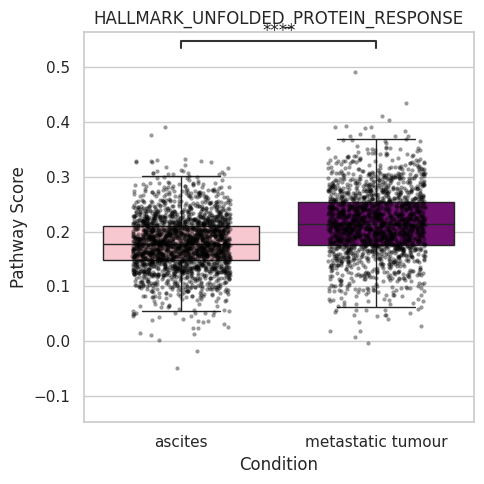

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.970e-54 t=-1.571e+01


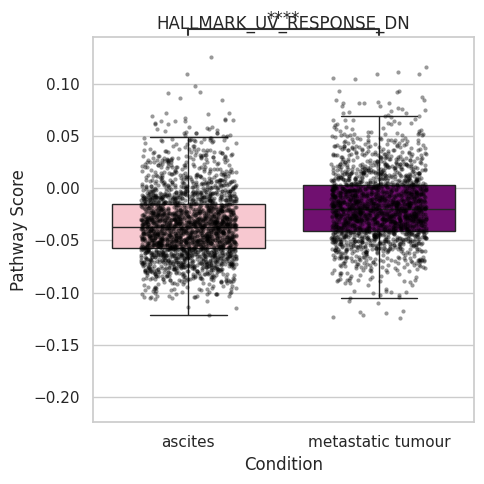

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:0.000e+00 t=-4.353e+01


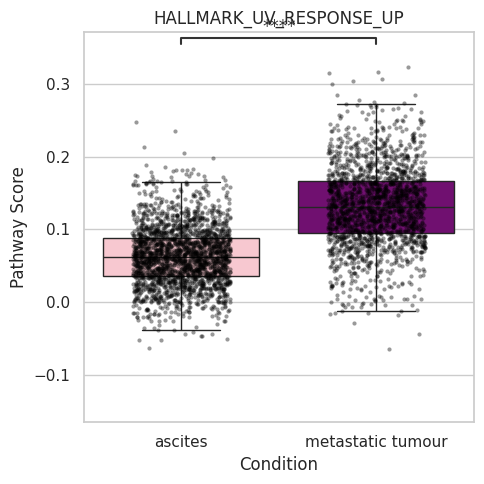

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.443e-15 t=-7.950e+00


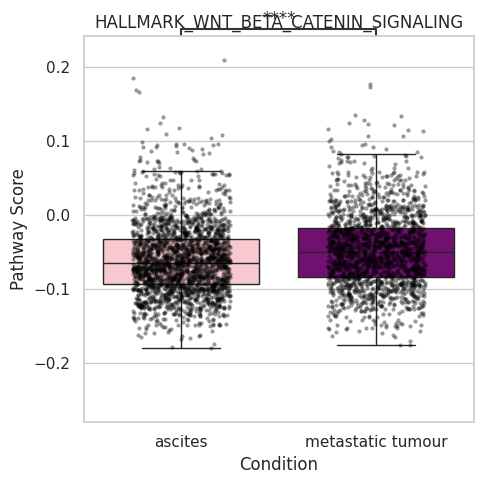

/scratch/temp/25256248/ipykernel_2078942/2607940607.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.722e-27 t=-1.091e+01


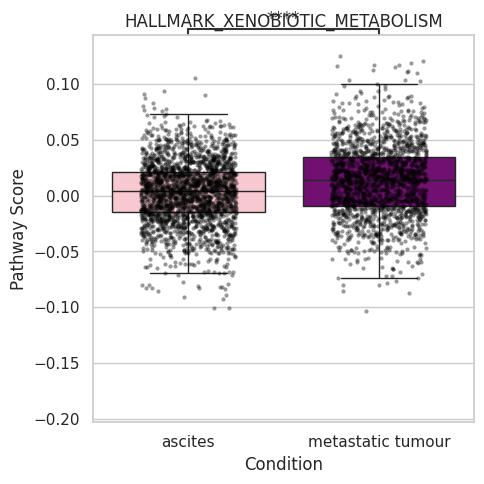

In [89]:
# Use .obs dataframe
obs_df = data_DC2.obs.copy()

# Keep only conditions of interest
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Set plotting style
sns.set(style="whitegrid")

# Consistent colour palette
palette = {
    "ascites": "#FFC0CB",     # pink
    "metastatic tumour": "#800080"   # purple
}

# Comparison pair
pairs = [("ascites", "metastatic tumour")]

# Loop through gene sets
for gene_set in H_sets.keys():

    score_col = f"{gene_set}_score"

    # Skip missing pathways
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col}")
        continue

    # Remove NA values
    plot_df = obs_df[
        ["sample_type_major2", score_col]
    ].dropna()

    # Skip empty groups
    ascites_n = (
        plot_df["sample_type_major2"] == "ascites"
    ).sum()

    metastatic_n = (
        plot_df["sample_type_major2"] == "metastatic tumour"
    ).sum()

    if ascites_n == 0 or metastatic_n == 0:
        continue

    # Create figure
    plt.figure(figsize=(5, 5))

    ax = sns.boxplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        palette=palette,
        showfliers=False #removes boxplot outliers
    )

    sns.stripplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        #palette=palette,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.25     #True
    )

    # Add t-test annotation
    annotator = Annotator(
        ax,
        pairs,
        data=plot_df,
        x="sample_type_major2",
        y=score_col
    )

    annotator.configure(
        test="t-test_welch",
        text_format="star",   # or "simple"
        loc="outside"
    )

    annotator.apply_and_annotate()

     # ---- FIX OVERLAP ISSUE ----
    # Move title slightly higher
    ax.set_title(gene_set, pad=25)

    # Labels
    plt.title(gene_set)
    plt.xlabel("Condition")
    plt.ylabel("Pathway Score")

    # Give extra top margin so stars don't hit title
    plt.ylim(
        plot_df[score_col].min() - 0.1,
        plot_df[score_col].max() * 1.15
    )

    plt.tight_layout()
    plt.show()
     

## Do per sample - generate score for mregDCs

### KEGG Pathways

In [90]:
# Create a dictionary to store mean scores per sample
sample_scores = {}

# Iterate through each gene set
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()

    # Score the cells using the gene set
    sc.tl.score_genes(data_mregDC, gene_list=gene_set, score_name=f"{set_name}_score")


# Select only numeric columns for aggregation
numeric_columns = [f"{set_name}_score" for set_name in K_sets_sub.keys()]

# Ensure these columns exist in data_mregDC.obs
numeric_columns = [col for col in numeric_columns if col in data_mregDC.obs.columns]

# Group by 'integration_id' and calculate mean only for numeric columns
sample_scores_df = data_mregDC.obs.groupby("integration_id")[numeric_columns].mean()

# Add the sample_type_major2 metadata for each sample
sample_scores_df["sample_type_major2"] = data_mregDC.obs.groupby("integration_id")["sample_type_major2"].first()
     

       'PPARGC1A', 'PRKAG3'],
      dtype='object')
       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL5A', 'KIR2DS1', 'KIR2DS3',
       'KIR2DS4', 'KIR2DS5', 'KIR3DL3'],
      dtype='object')
       'AVPR1A', 'AVPR1B', 'BDKRB1', 'CACNA1B', 'CACNA1E', 'CACNA1I',
       'CACNA1S', 'CALML6', 'CAMK2A', 'CCKAR', 'CCKBR', 'CHP2', 'CHRM1',
       'CHRM2', 'CHRM5', 'DRD1', 'DRD5', 'GRM1', 'GRM5', 'GRPR', 'HTR2A',
       'HTR2C', 'HTR4', 'HTR5A', 'HTR6', 'LHCGR', 'MYLK2', 'MYLK3', 'NOS2',
       'P2RX3', 'P2RX6', 'PLCZ1', 'PLN', 'PPP3R2', 'PRKACG', 'PTGFR',
       'SLC25A31', 'TACR3', 'TRHR', 'VDAC2P5'],
      dtype='object')
       'CLDN6', 'CLDN8', 'HLA-DRB3', 'HLA-DRB4', 'NECTIN1', 'NECTIN2',
       'NECTIN3', 'NLGN4X', 'PECAM1'],
      dtype='object')
       'CCL3L3', 'CCR8', 'CXCL8', 'GNG13', 'GRK1', 'GRK2', 'GRK3', 'PF4V1',
       'PPBPP1', 'PRKACG'],
      dtype='object')
       'CCR8', 'CNTFR', 'CXCL8', 'EDAR', 'EPO', 'G

/scratch/temp/25256248/ipykernel_2078942/1722264459.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/scratch/temp/25256248/ipykernel_2078942/1722264459.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


/scratch/temp/25256248/ipykernel_2078942/1915393413.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


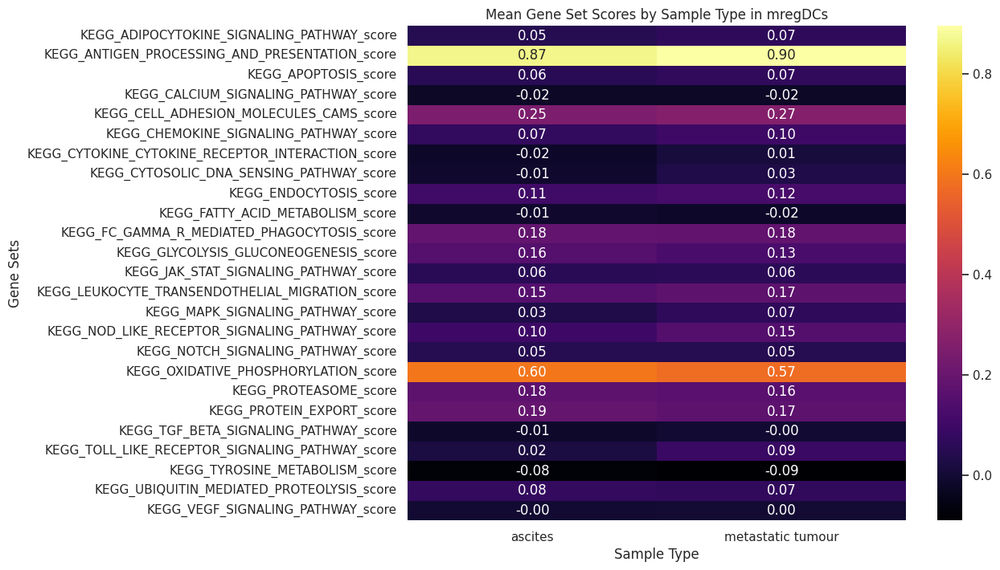

In [91]:
# Group by cancer type and compute the average score for each cancer type 
cancer_type_scores_df = sample_scores_df.groupby("sample_type_major2").mean()

# plot the scores
plt.figure(figsize=(10, 8))
sns.heatmap(cancer_type_scores_df.T, cmap="inferno", annot=True, fmt=".2f")
plt.xlabel("Sample Type")
plt.ylabel("Gene Sets")
plt.title("Mean Gene Set Scores by Sample Type in mregDCs")
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.684e-04 t=-3.792e+00


/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



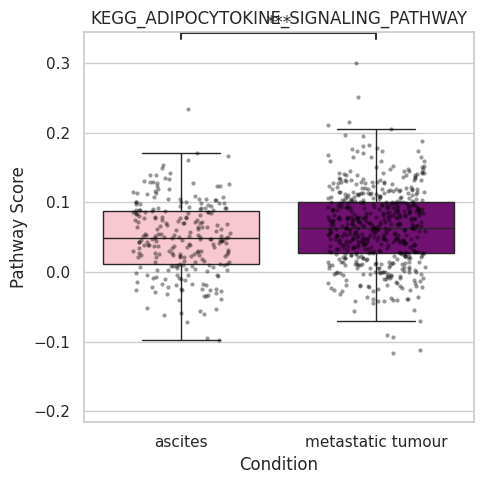

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.032e-02 t=-2.056e+00


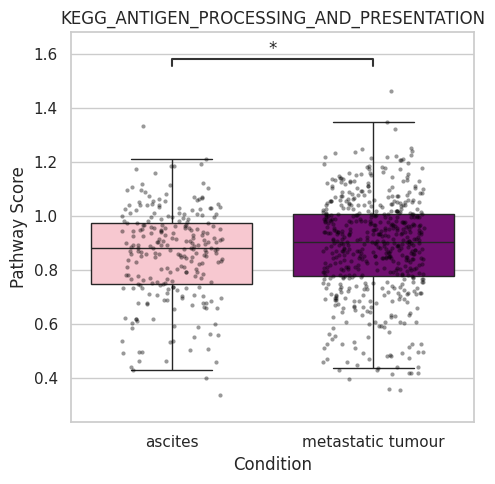

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.168e-06 t=-4.920e+00


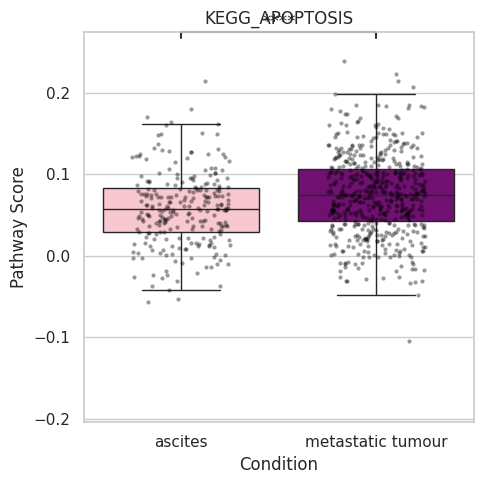

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.939e-01 t=-8.534e-01


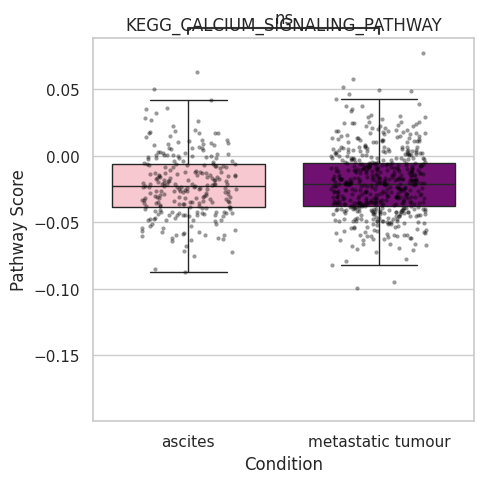

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.256e-04 t=-3.440e+00


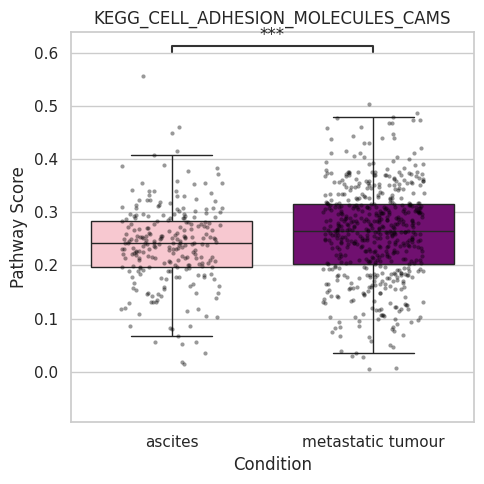

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.261e-12 t=-6.962e+00


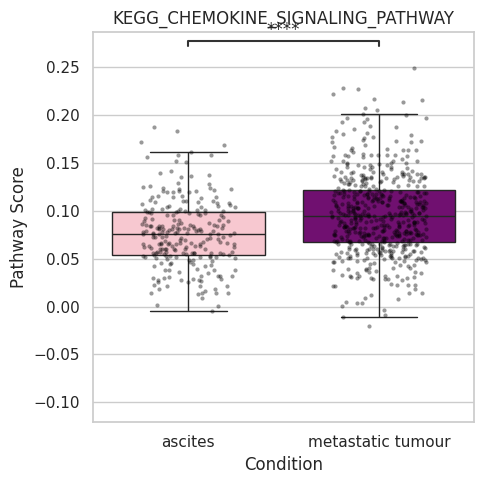

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.779e-13 t=-7.334e+00


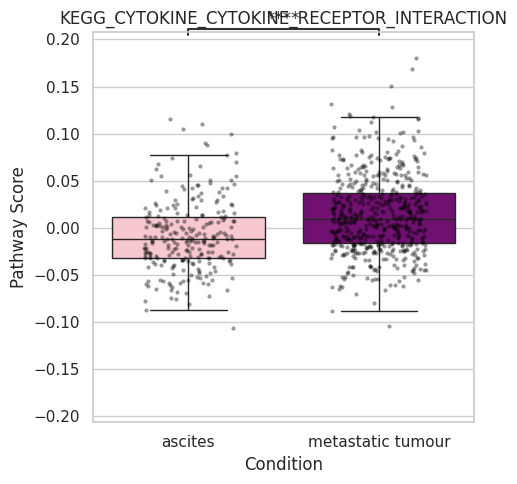

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.132e-24 t=-1.065e+01


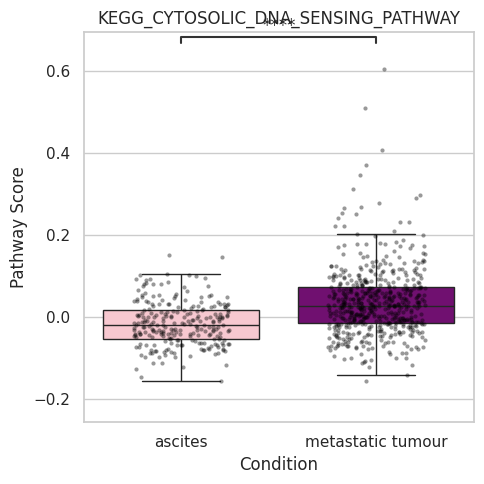

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.061e-12 t=-7.147e+00


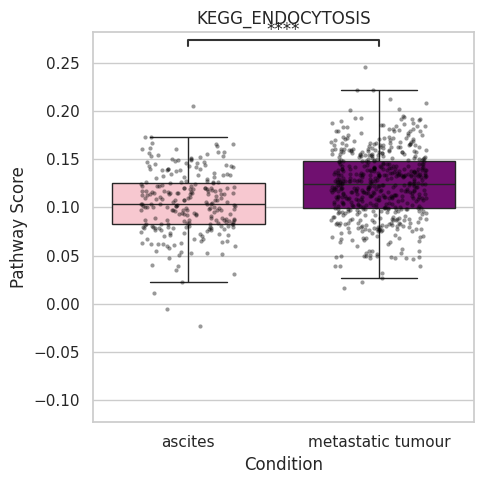

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.982e-01 t=1.289e+00


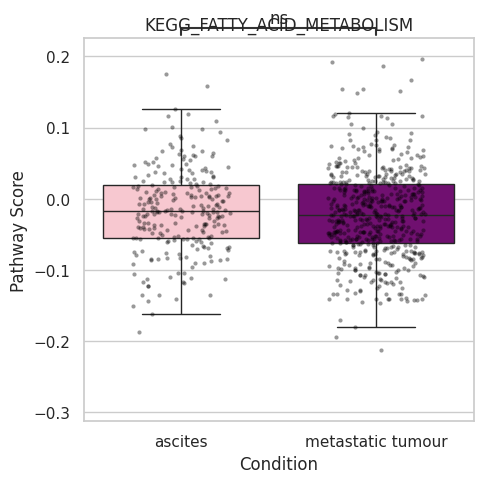

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.924e-01 t=-8.560e-01


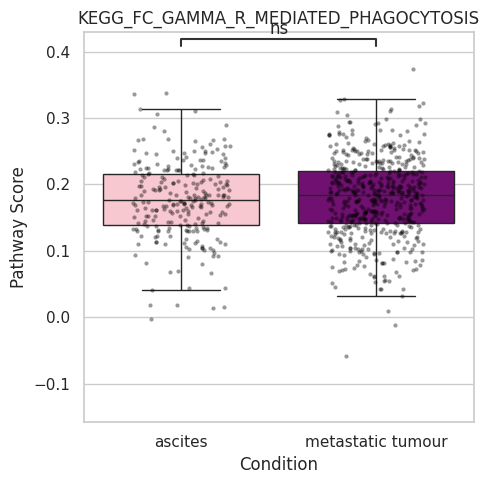

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.620e-04 t=3.528e+00


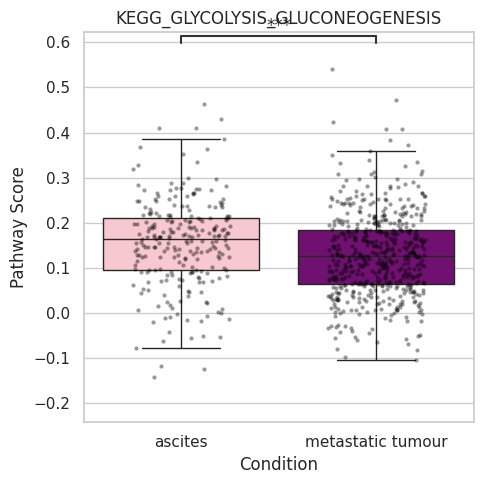

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.005e-01 t=8.413e-01


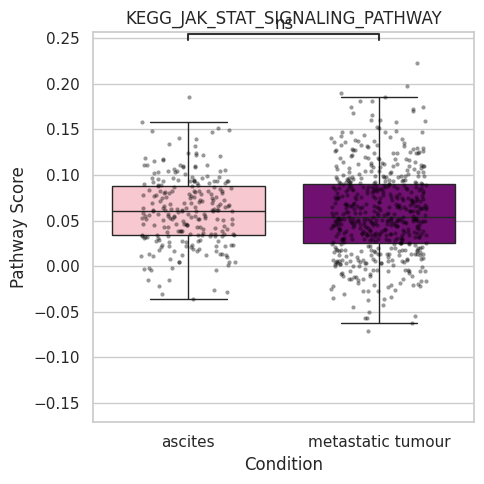

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.855e-10 t=-6.235e+00


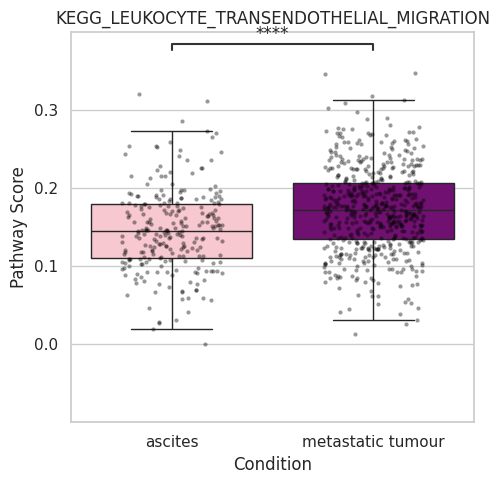

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.004e-37 t=-1.369e+01


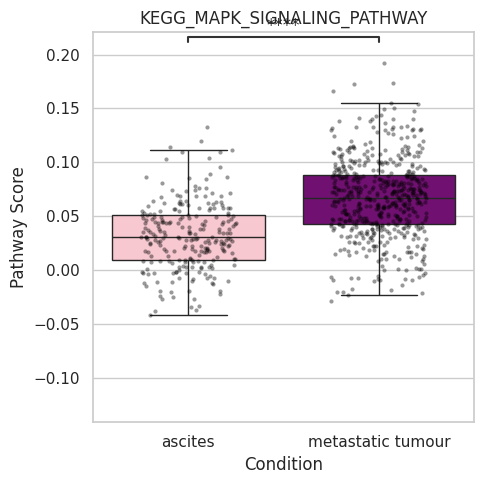

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.229e-33 t=-1.274e+01


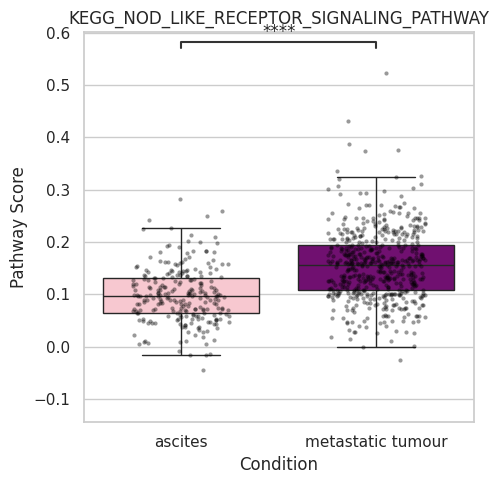

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.929e-02 t=2.348e+00


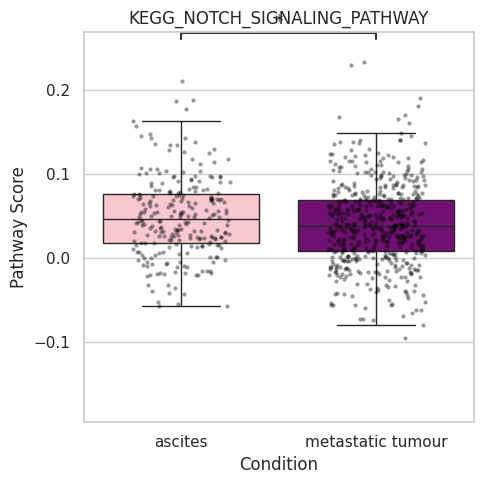

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.355e-01 t=6.201e-01


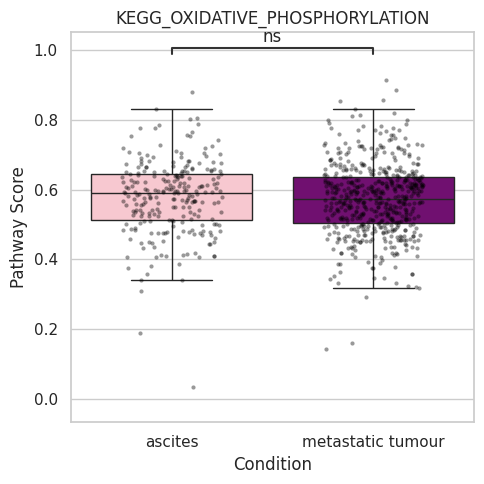

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.577e-01 t=3.086e-01


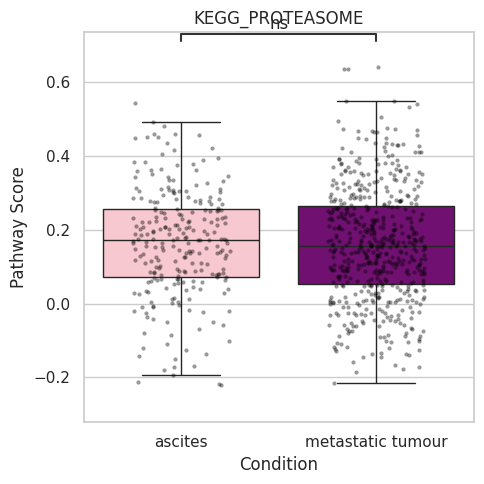

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.372e-01 t=7.775e-01


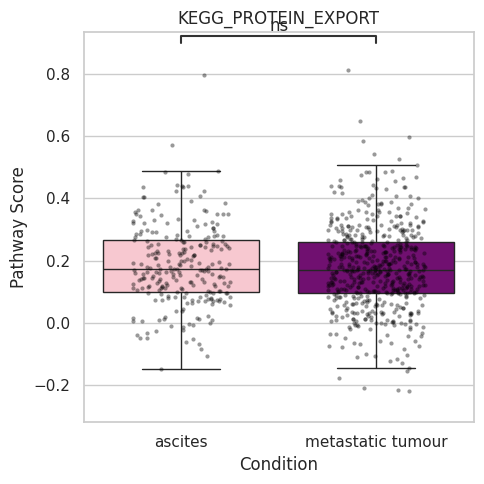

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.494e-07 t=-5.036e+00


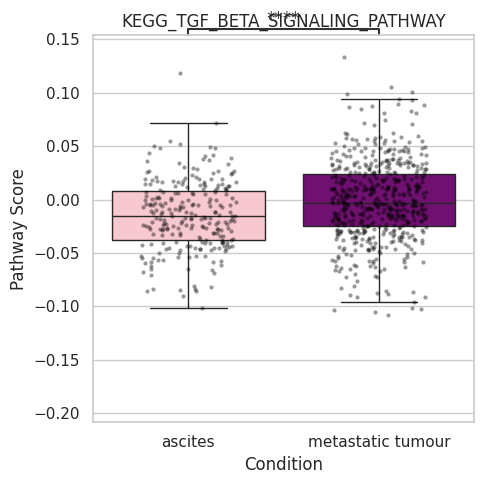

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.911e-58 t=-1.768e+01


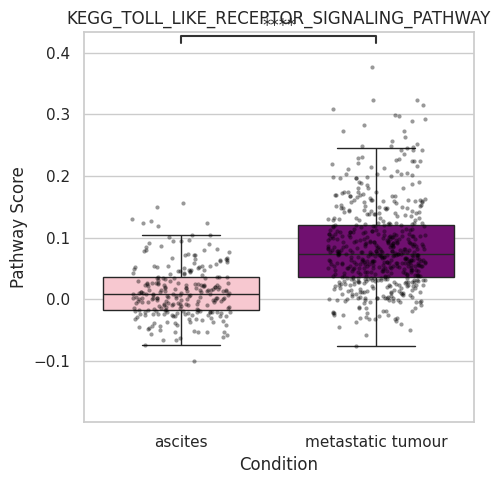

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.749e-03 t=3.009e+00


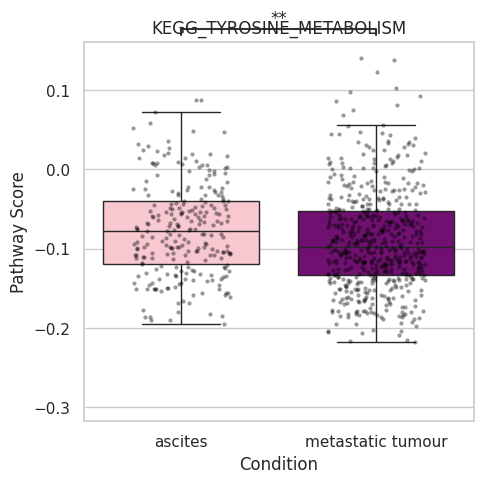

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.345e-01 t=1.499e+00


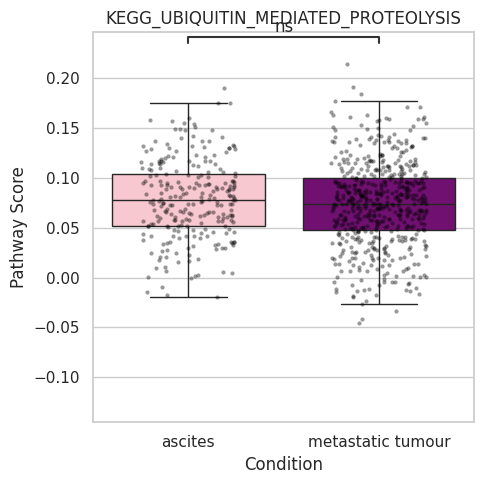

/scratch/temp/25256248/ipykernel_2078942/947822375.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.337e-02 t=-2.483e+00


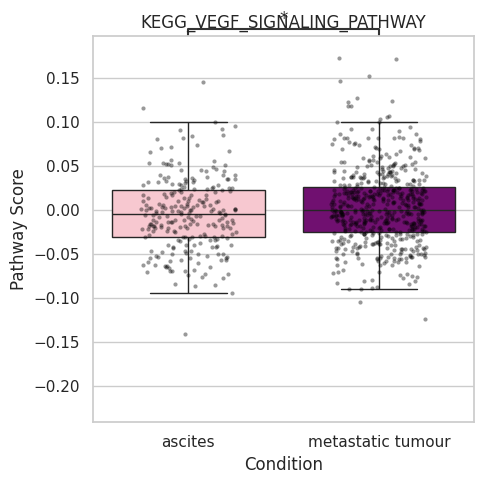

In [92]:
# Use .obs dataframe
obs_df = data_mregDC.obs.copy()

# Keep only conditions of interest
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Set plotting style
sns.set(style="whitegrid")

# Consistent colour palette
palette = {
    "ascites": "#FFC0CB",     # pink
    "metastatic tumour": "#800080"   # purple
}

# Comparison pair
pairs = [("ascites", "metastatic tumour")]

# Loop through gene sets
for gene_set in K_sets_sub.keys():

    score_col = f"{gene_set}_score"

    # Skip missing pathways
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col}")
        continue

    # Remove NA values
    plot_df = obs_df[
        ["sample_type_major2", score_col]
    ].dropna()

    # Skip empty groups
    ascites_n = (
        plot_df["sample_type_major2"] == "ascites"
    ).sum()

    metastatic_n = (
        plot_df["sample_type_major2"] == "metastatic tumour"
    ).sum()

    if ascites_n == 0 or metastatic_n == 0:
        continue

    # Create figure
    plt.figure(figsize=(5, 5))

    ax = sns.boxplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        palette=palette,
        showfliers=False #removes boxplot outliers
    )

    sns.stripplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        #palette=palette,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.25     #True
    )

    # Add t-test annotation
    annotator = Annotator(
        ax,
        pairs,
        data=plot_df,
        x="sample_type_major2",
        y=score_col
    )

    annotator.configure(
        test="t-test_welch",
        text_format="star",   # or "simple"
        loc="outside"
    )

    annotator.apply_and_annotate()

     # ---- FIX OVERLAP ISSUE ----
    # Move title slightly higher
    ax.set_title(gene_set, pad=25)

    # Labels
    plt.title(gene_set)
    plt.xlabel("Condition")
    plt.ylabel("Pathway Score")

    # Give extra top margin so stars don't hit title
    plt.ylim(
        plot_df[score_col].min() - 0.1,
        plot_df[score_col].max() * 1.15
    )

    plt.tight_layout()
    plt.show()
     

### Hallmark pathways

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.027e-02 t=-2.329e+00


/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



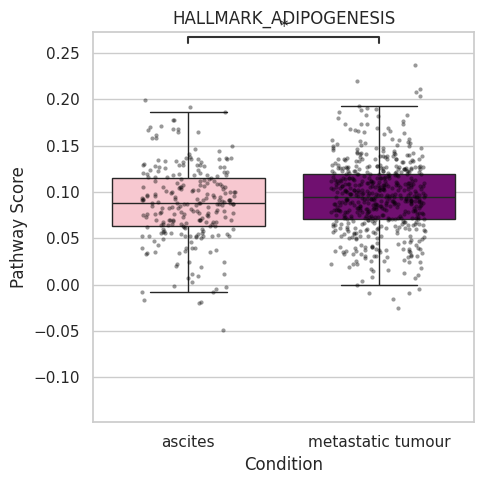

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.551e-11 t=-6.610e+00


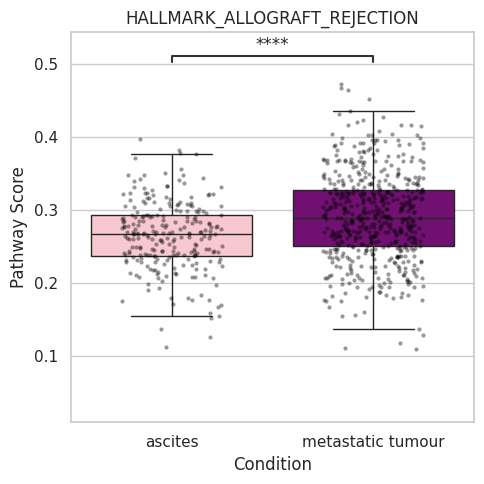

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.519e-07 t=-5.323e+00


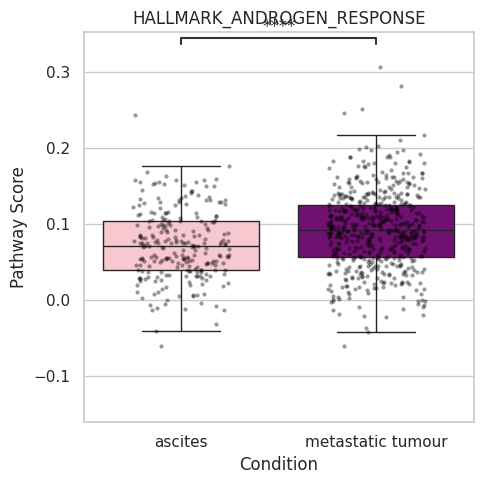

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.080e-12 t=-7.081e+00


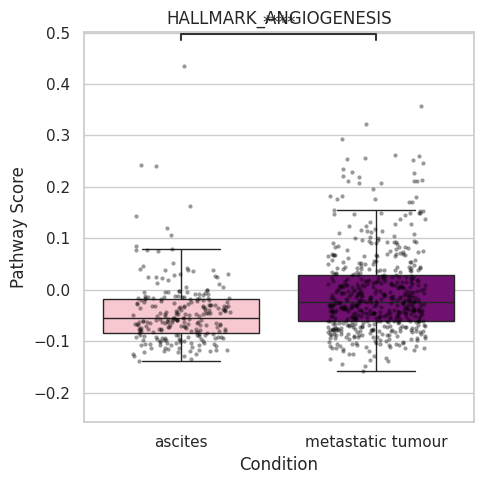

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.115e-02 t=1.809e+00


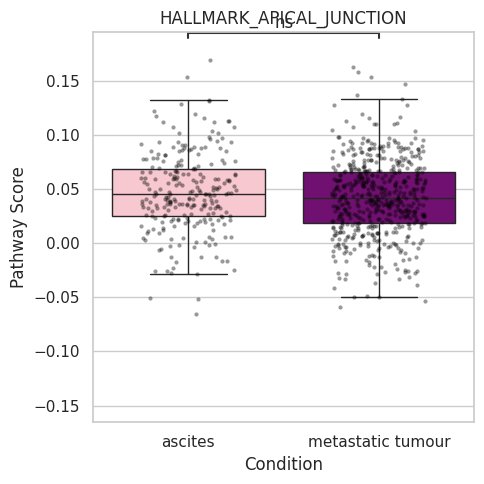

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.980e-08 t=5.568e+00


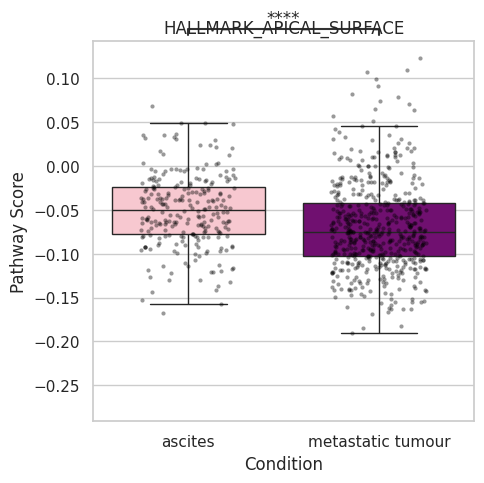

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.989e-21 t=-9.907e+00


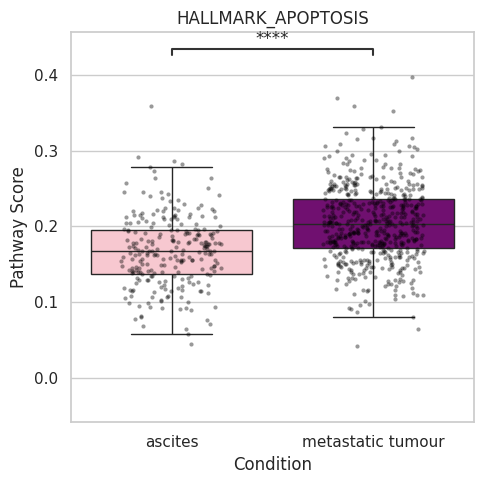

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.821e-01 t=7.035e-01


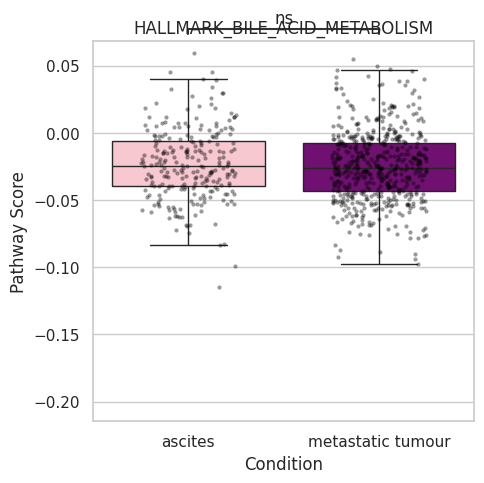

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.126e-04 t=3.740e+00


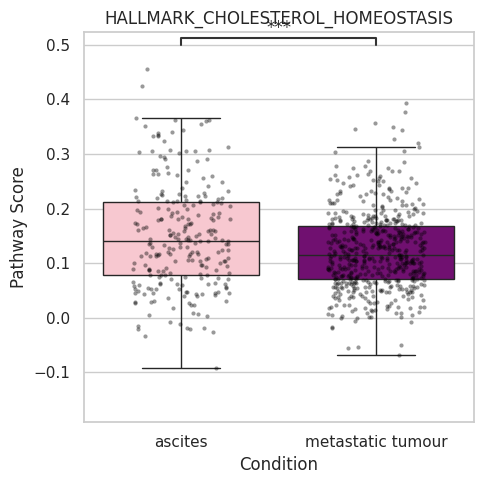

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.736e-16 t=-8.343e+00


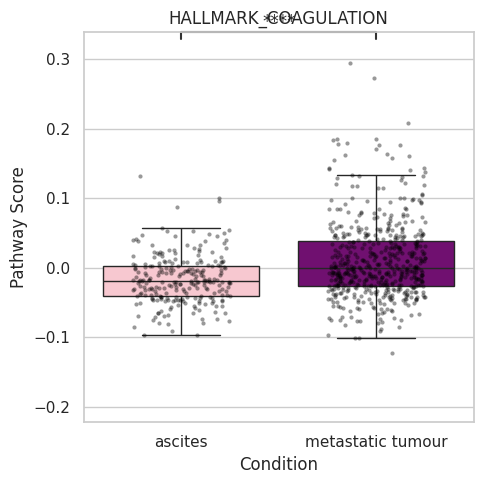

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.758e-14 t=-7.675e+00


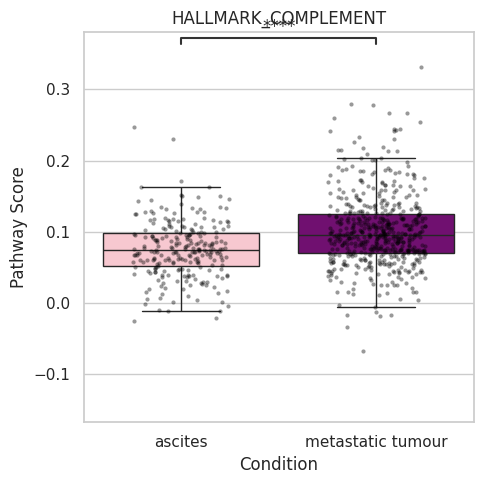

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.073e-04 t=3.452e+00


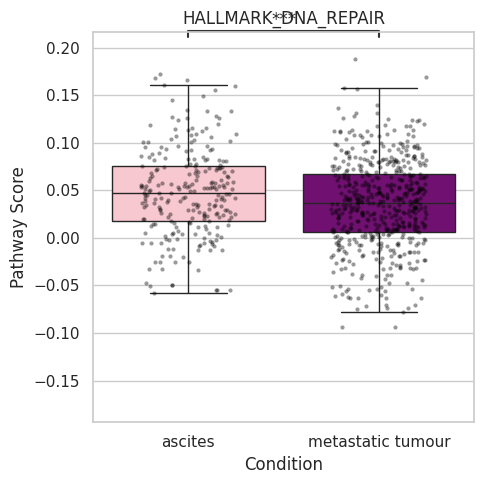

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.576e-02 t=1.779e+00


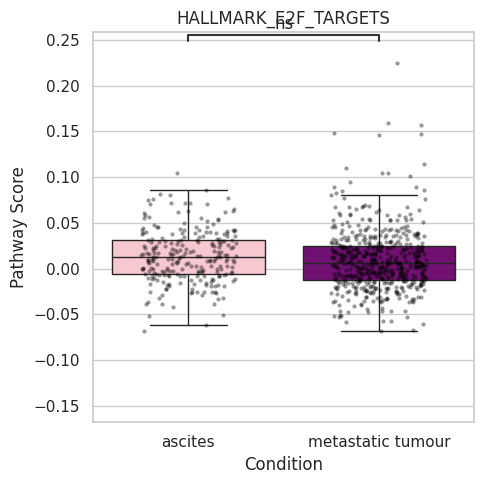

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.057e-35 t=-1.338e+01


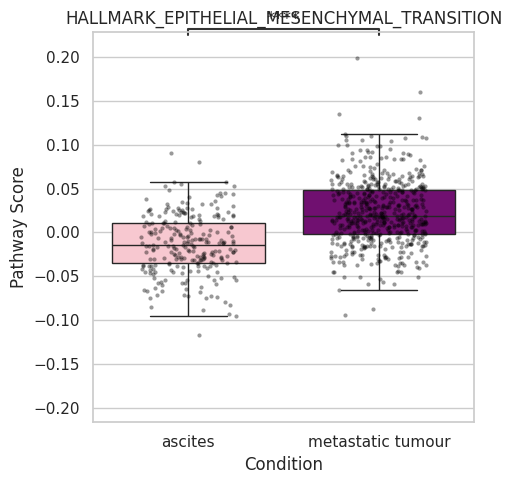

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.446e-23 t=-1.041e+01


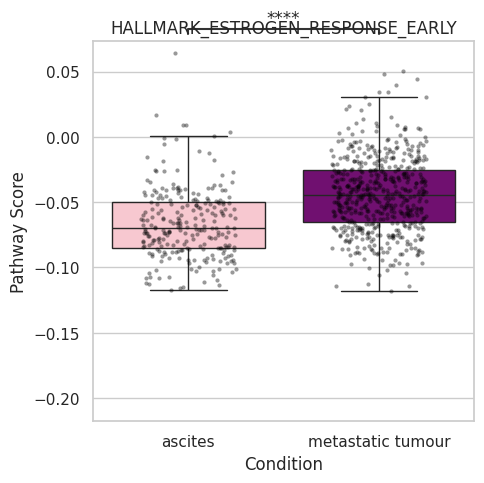

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.152e-49 t=-1.644e+01


/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



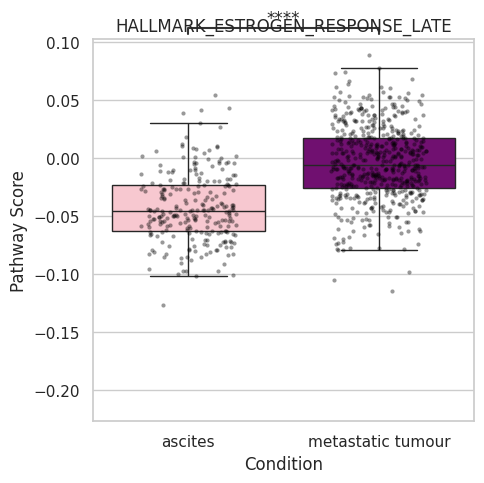

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.022e-02 t=2.579e+00


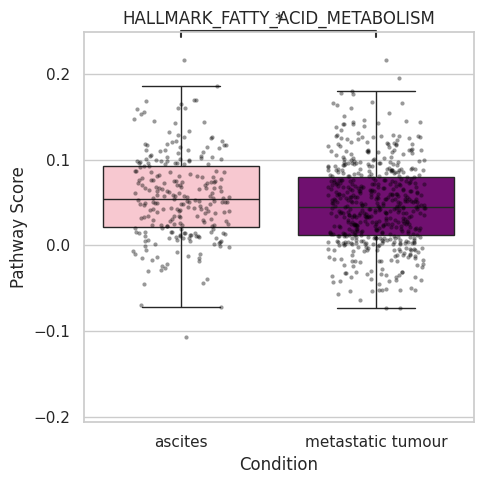

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.184e-01 t=-9.988e-01


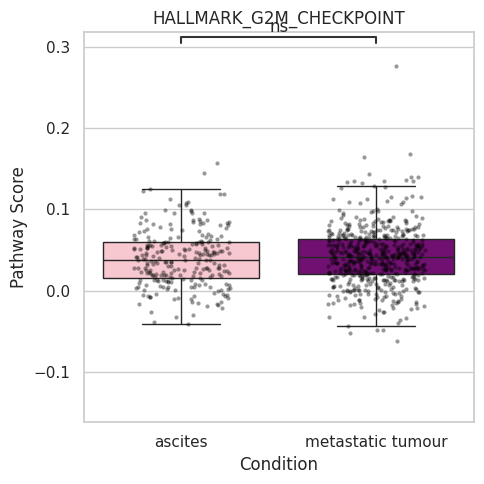

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.738e-02 t=-2.087e+00


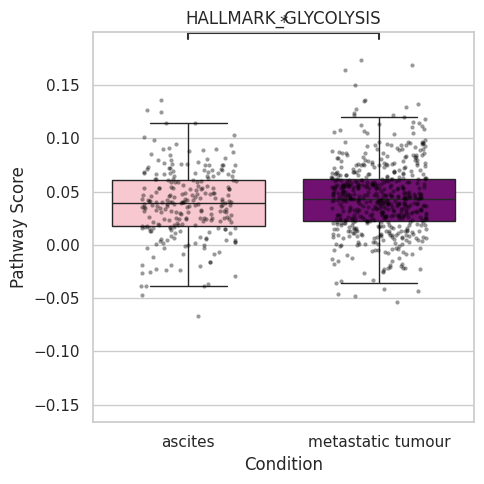

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.410e-03 t=-3.210e+00


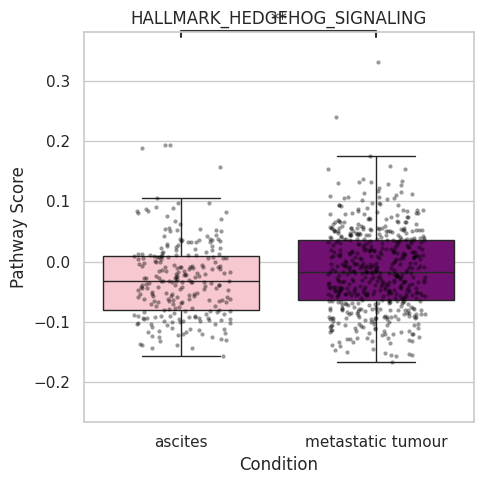

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:8.606e-02 t=-1.720e+00


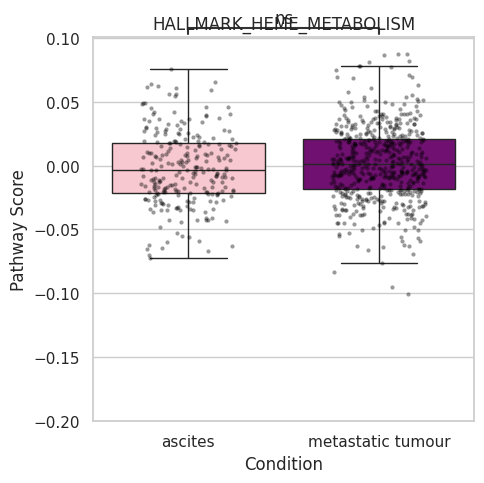

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.134e-52 t=-1.687e+01


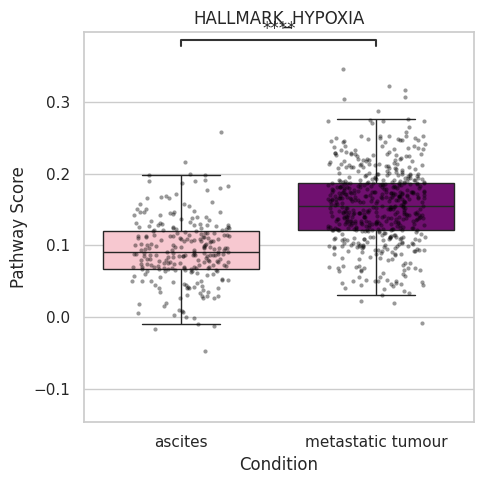

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.359e-20 t=-9.519e+00


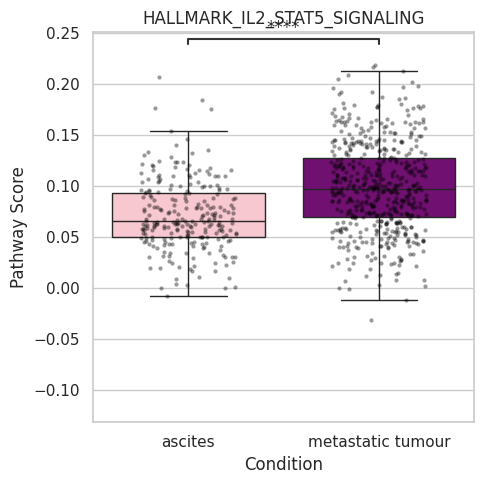

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.364e-06 t=-4.592e+00


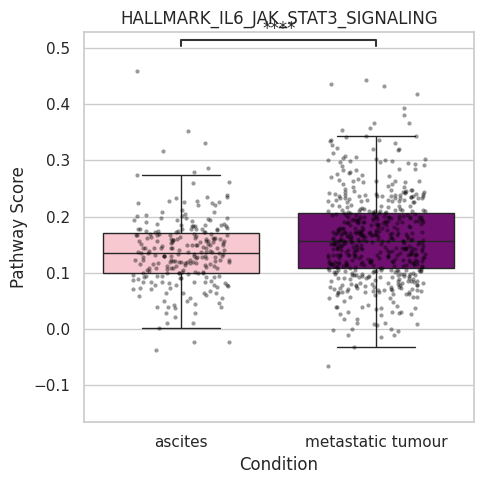

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.816e-35 t=-1.335e+01


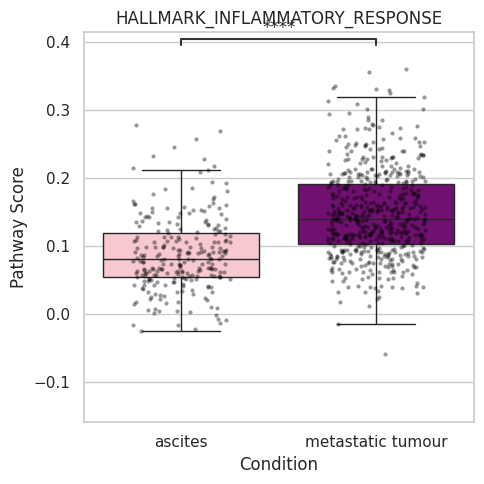

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.047e-01 t=-3.791e-01


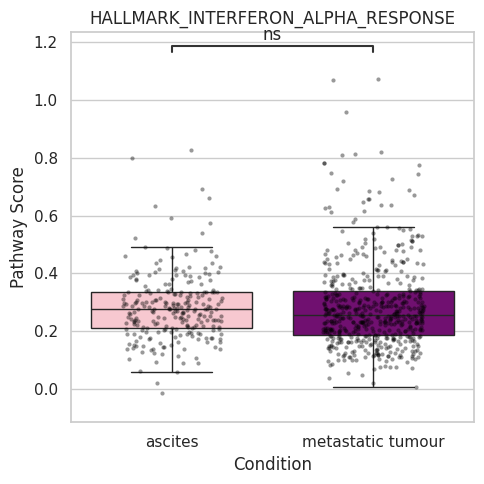

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.940e-07 t=-5.264e+00


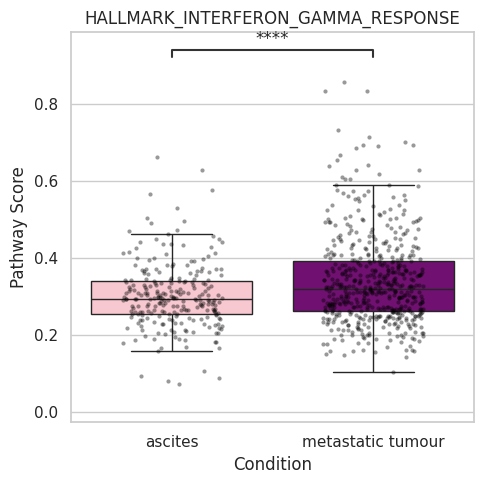

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.217e-19 t=-9.331e+00


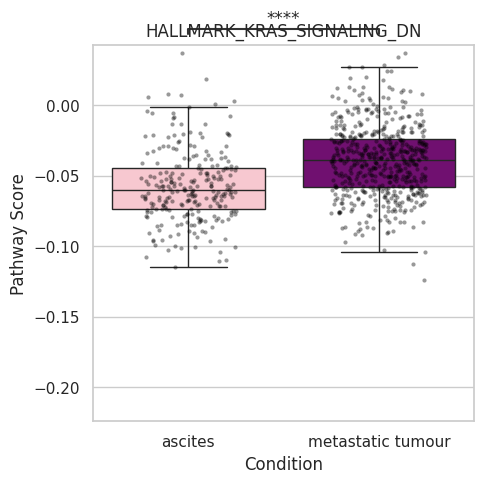

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.526e-39 t=-1.423e+01


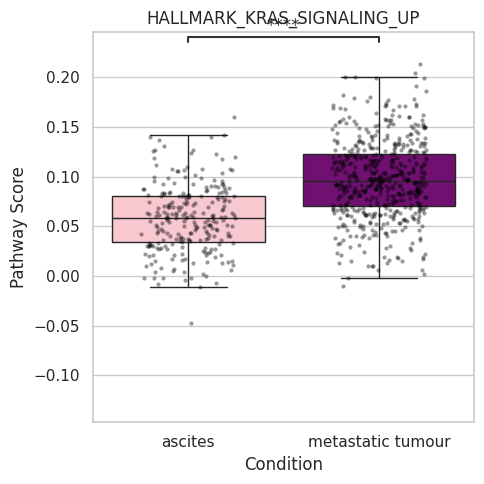

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.826e-01 t=1.076e+00


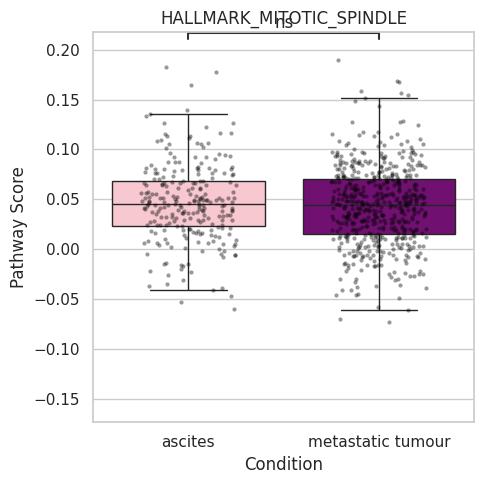

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.884e-02 t=-1.893e+00


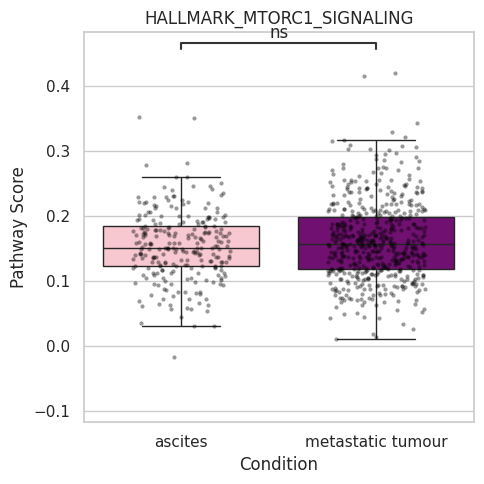

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.289e-01 t=1.521e+00


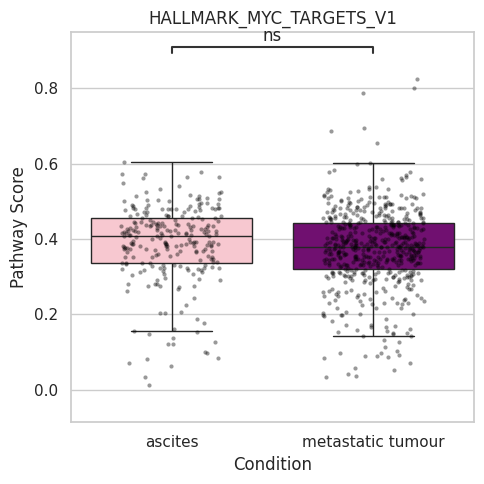

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.732e-05 t=-4.334e+00


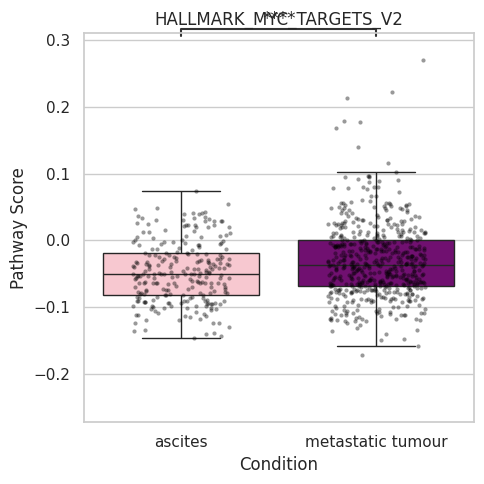

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.677e-08 t=5.588e+00


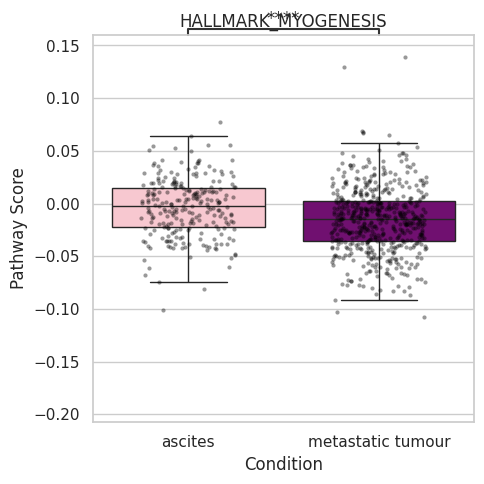

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.650e-01 t=2.991e-01


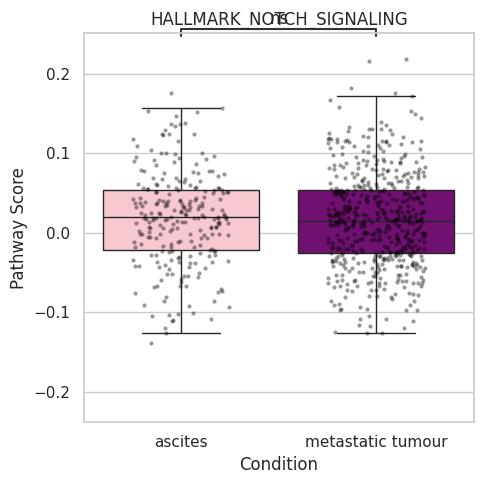

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.494e-02 t=2.011e+00


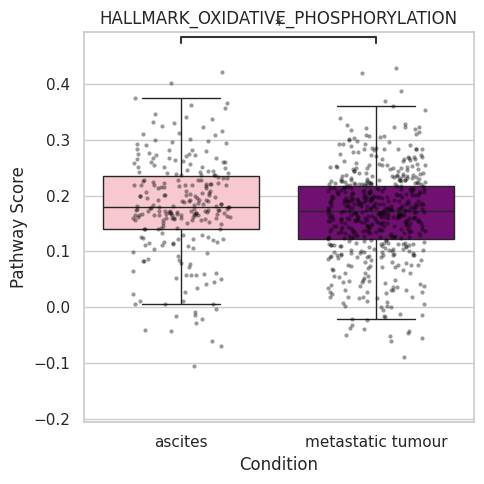

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.002e-12 t=-7.334e+00


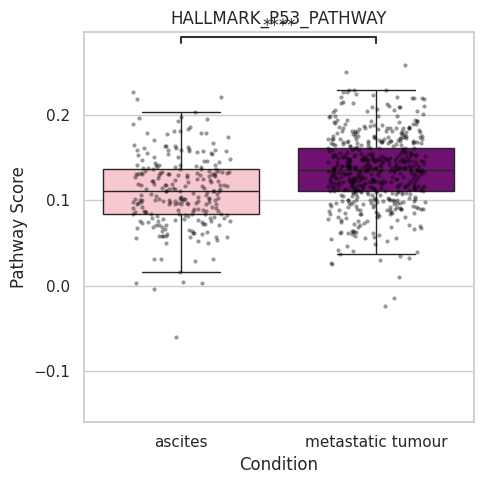

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.490e-02 t=-2.116e+00


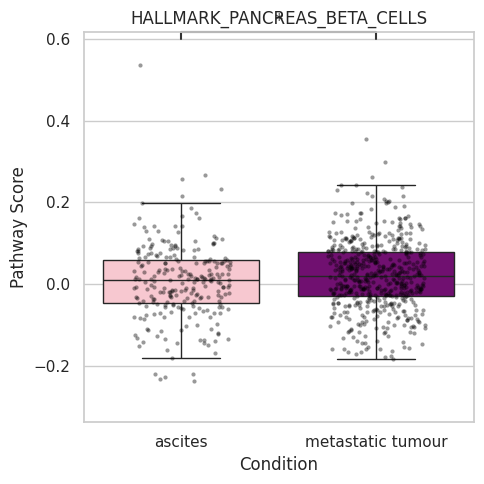

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:6.830e-02 t=1.827e+00


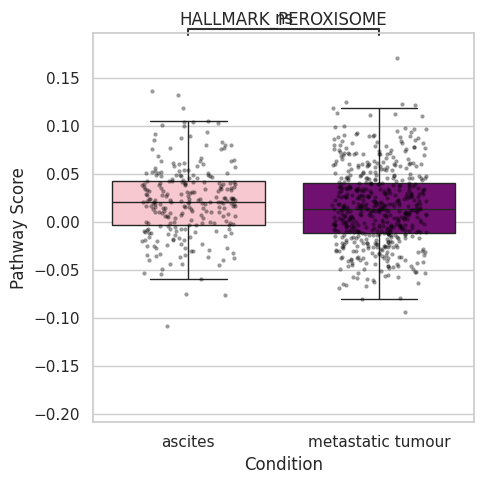

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:9.229e-01 t=-9.688e-02


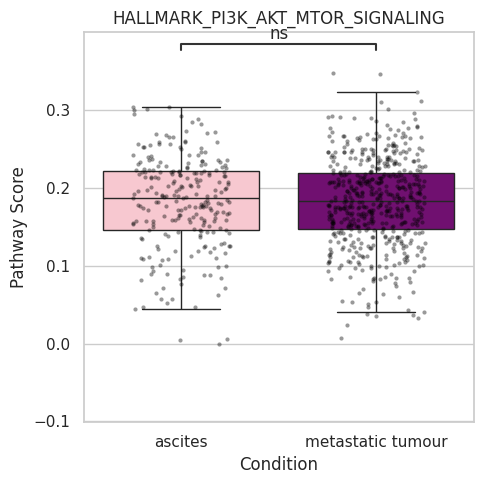

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.106e-01 t=-1.253e+00


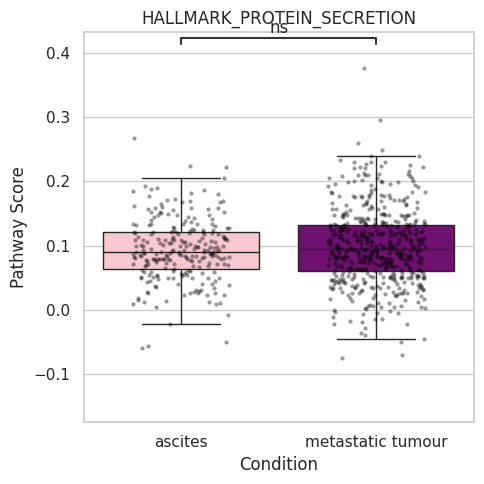

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.004e-01 t=-1.646e+00


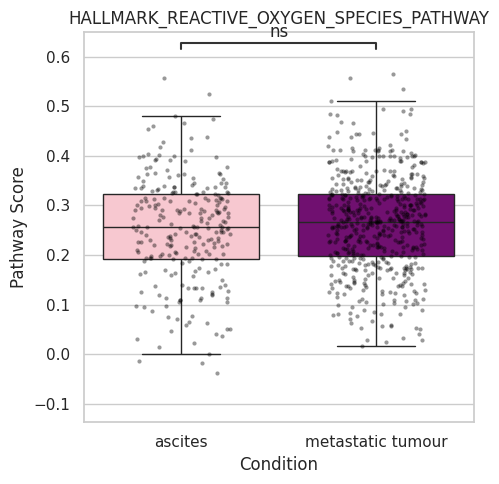

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.963e-01 t=-1.294e+00


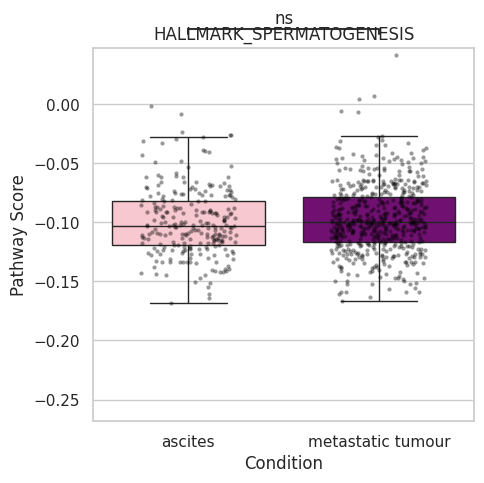

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:7.277e-13 t=-7.359e+00


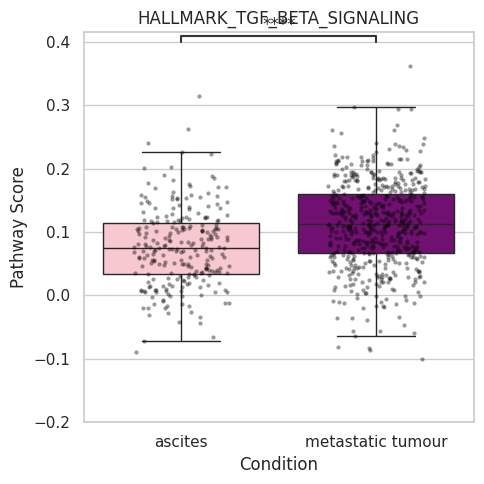

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.546e-70 t=-2.039e+01


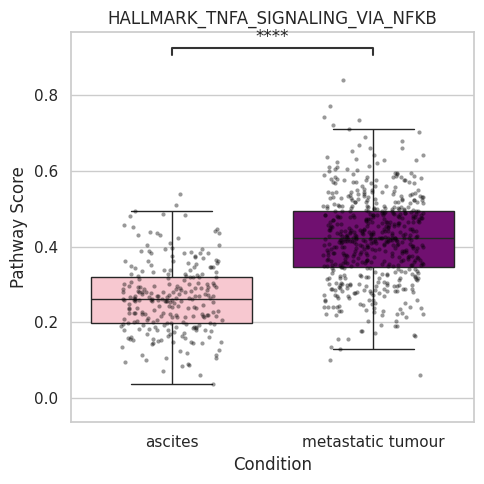

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:4.499e-03 t=-2.854e+00


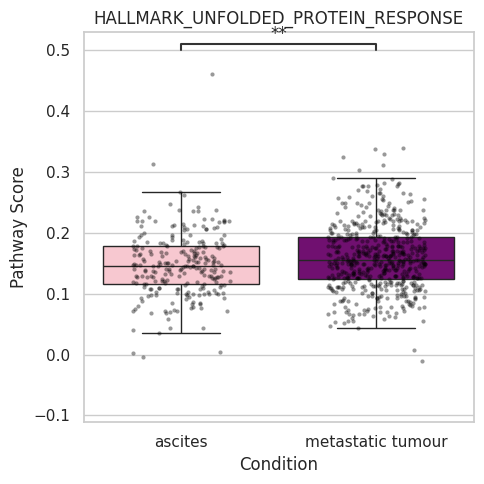

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:5.670e-05 t=-4.062e+00


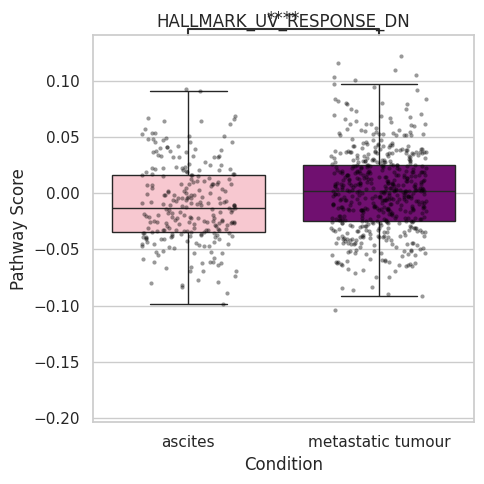

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:3.607e-35 t=-1.321e+01


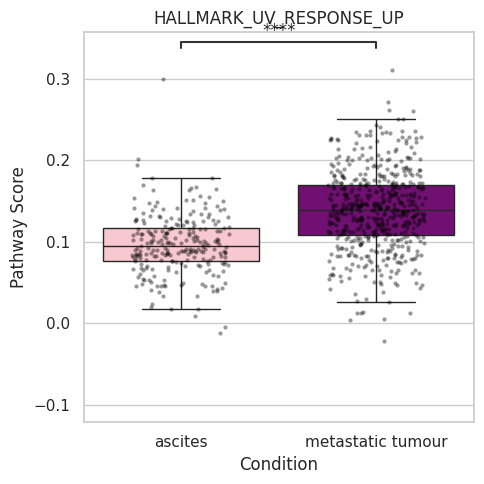

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:1.844e-02 t=-2.365e+00


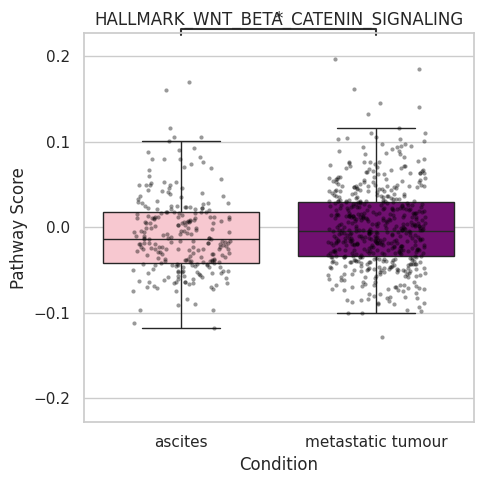

/scratch/temp/25256248/ipykernel_2078942/319836329.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ascites vs. metastatic tumour: Welch's t-test independent samples, P_val:2.609e-10 t=-6.452e+00


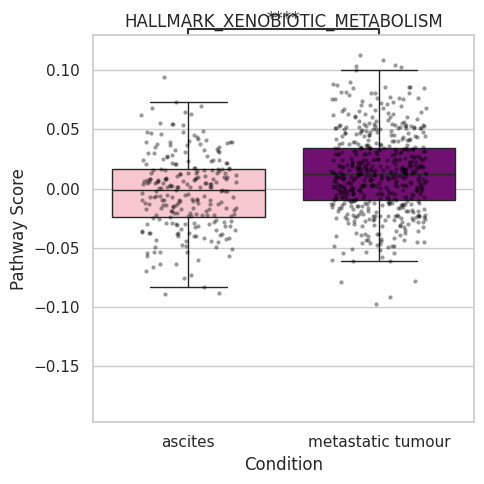

In [93]:
# Use .obs dataframe
obs_df = data_mregDC.obs.copy()

# Keep only conditions of interest
obs_df = obs_df[
    obs_df["sample_type_major2"].isin(
        ["ascites", "metastatic tumour"]
    )
]

# Set plotting style
sns.set(style="whitegrid")

# Consistent colour palette
palette = {
    "ascites": "#FFC0CB",     # pink
    "metastatic tumour": "#800080"   # purple
}

# Comparison pair
pairs = [("ascites", "metastatic tumour")]

# Loop through gene sets
for gene_set in H_sets.keys():

    score_col = f"{gene_set}_score"

    # Skip missing pathways
    if score_col not in obs_df.columns:
        print(f"Skipping {score_col}")
        continue

    # Remove NA values
    plot_df = obs_df[
        ["sample_type_major2", score_col]
    ].dropna()

    # Skip empty groups
    ascites_n = (
        plot_df["sample_type_major2"] == "ascites"
    ).sum()

    metastatic_n = (
        plot_df["sample_type_major2"] == "metastatic tumour"
    ).sum()

    if ascites_n == 0 or metastatic_n == 0:
        continue

    # Create figure
    plt.figure(figsize=(5, 5))

    ax = sns.boxplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        palette=palette,
        showfliers=False #removes boxplot outliers
    )

    sns.stripplot(
        data=plot_df,
        x="sample_type_major2",
        y=score_col,
        #palette=palette,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.25     #True
    )

    # Add t-test annotation
    annotator = Annotator(
        ax,
        pairs,
        data=plot_df,
        x="sample_type_major2",
        y=score_col
    )

    annotator.configure(
        test="t-test_welch",
        text_format="star",   # or "simple"
        loc="outside"
    )

    annotator.apply_and_annotate()

     # ---- FIX OVERLAP ISSUE ----
    # Move title slightly higher
    ax.set_title(gene_set, pad=25)

    # Labels
    plt.title(gene_set)
    plt.xlabel("Condition")
    plt.ylabel("Pathway Score")

    # Give extra top margin so stars don't hit title
    plt.ylim(
        plot_df[score_col].min() - 0.1,
        plot_df[score_col].max() * 1.15
    )

    plt.tight_layout()
    plt.show()
     